# ENTRENAMIENTO V16 (solo telas de fibras): curva presión–diámetro de carótida in vivo reconstruida con capas de un injerto biomimético

**Objetivo.** Dada la curva presión–diámetro de una arteria, encontrar la **cantidad de cada capa** de un injerto (matriz elastomérica y/o telas de fibras) cuya superposición reproduce esa curva. La red neuronal propone las cantidades; el pulido (conjunto activo + KKT) las lleva al óptimo exacto.

*Variable objetivo (cambio respecto de V15)*
1. **P_pared(λθ) = Pi − Pa** [kPa], con λθ el estiramiento circunferencial en el radio medio (λθ = r_m/R_m, **proporcional al diámetro**). Se calcula integrando el equilibrio radial sobre el espesor, P_pared = ∫(σθθ − σrr)/r dr, con la cinemática y los parámetros publicados de Masson et al. (2011) para los 41 sujetos.
2. **No depende de la presión perivascular Pa**: la curva presión–diámetro es independiente de esa condición de borde, a diferencia de σθθ(r_m). Es la magnitud que el injerto debe igualar (compliance).
3. Supuesto: espesor in vivo **h = 0,6 mm** (`H_PARED_MM`, Célula G). La validación de la reconstrucción sigue haciéndose sobre σθθ, que es lo que el paper publica.

*Bases = capas del injerto (Célula 2)*

Se usa un modelo de membrana delgada con ley de Laplace (P = T/r) y estiramiento axial fijo:
- **Tela de fibras** que se engancha en λ = k: tensión lineal tras el enganche, P_k ∝ max(0, λ − k)/λ.
- **Matriz elastomérica** neo-Hookeana con reposo en λ = s: P_m ∝ 1 − (λ/s)⁻⁴.

Cada coeficiente c_j ≥ 0 es una **cantidad de material** (espesor × módulo), y c_j ≤ 6 es el límite de fabricación. La forma J surge del **reclutamiento escalonado** de las telas.

*Diseños*
- **`DISENO = "matriz"`**: matriz (s = 0,90) + 4 telas con enganche en λ = 1,0256 / 1,086 / 1,1207 / 1,1437. Piso NRMSE medio ≈ 0,50 %, cond(A) ≈ 19. El piso casi no depende de s en 0,81–0,90.
- **`DISENO = "fibras"`**: 5 telas con enganche en λ = 0,8922 / 1,026 / 1,0871 / 1,1213 / 1,1437. Piso NRMSE medio ≈ 0,48 %, cond(A) ≈ 19. La primera tela se engancha antes del rango medido y hace de "matriz lineal".
- Referencia: las líneas quebradas de V15 en esta misma variable dan un piso ≈ 0,43 %. Pasar a capas fabricables cuesta menos de 0,1 punto.

**Pretensado.** λ se mide respecto del radio de reposo de la *arteria*. Si el injerto se fabrica con radio de reposo s_g·R_m, con s_g ≤ primer enganche (0,90 en el diseño con matriz, 0,892 en el de solo fibras), todas las capas se tensan **después** del reposo del injerto, de modo que ninguna necesita pretensado. La Célula 14 imprime el enganche de cada capa también respecto del injerto (λ_g = λ/s_g ≥ 1).

*Clase de curvas y generador*
- La clase del método son las curvas **realizables con telas**: combinaciones no negativas de 40 telas con enganches en [0,85; 1,16]. P_pared puede ser levemente cóncava al pie (λ < 1,05; en el 49 % de los sujetos), por eso la convexidad se exige desde `X_INICIO_CONVEXIDAD = 1,05`.
- El generador (Célula 4) es el de V15 aplicado a P_pared. La mezcla de parámetros incluye ahora R_m y Θ0, que intervienen en la integral transmural.

*Método de ajuste: mínimos cuadrados*
- El ajuste es **mínimos cuadrados** sobre las bases. La Celda 1 y la Celda 14 informan las dos variantes: ordinarios (sin cotas, c = A⁺y) y con cotas 0 ≤ c ≤ 6.
- En las curvas fisiológicas las cotas no se activan y ambas soluciones coinciden. Las cotas solo garantizan que el injerto sea fabricable en los extremos del espacio humano: no hay cantidades negativas de material.
- Las condiciones KKT se usan únicamente como **certificado** de que el resultado red + pulido es el óptimo exacto de mínimos cuadrados.

Se mantienen de V15: el pulido exacto, la arquitectura y la pérdida, la población de 41 sujetos con 10 reservados para test, el seguimiento de NT08, la prueba OOD con ley de Fung y la comparación red frente a óptimo.

**Archivos de datos requeridos** (en `DIR_MASSON`): `tabla2_masson_NT.csv`, `tabla4_masson_HT.csv` y, opcional para validar σθθ, `masson2011_curvas_medias.csv`.

## Célula G — Configuración global (ejecutar SIEMPRE primero)

In [3]:
# ==============================================================================
# CÉLULA G: CONFIGURACIÓN GLOBAL ÚNICA (constantes, archivos, diseño del injerto y clase de curvas)
# ==============================================================================
"""
Única fuente de verdad del notebook. EJECUTAR SIEMPRE PRIMERO (también tras reiniciar el kernel).

Variable física (V16): curva PRESIÓN–DIÁMETRO de la pared, P_pared(λθ) = Pi − Pa [kPa], con λθ el
estiramiento circunferencial en el radio medio r_m (λθ = r_m / R_m, proporcional al diámetro).
P_pared = ∫ (σθθ − σrr)/r dr sobre el espesor: es lo que el injerto debe igualar (compliance) y NO
depende de la presión perivascular Pa (Masson et al. 2011; equilibrio radial).

Cada base es una CAPA del injerto (modelo de membrana delgada, ley de Laplace, estiramiento axial fijo):
  • tela de fibras que se engancha en λ = k : P_k(λ) ∝ max(0, λ − k)/λ
      (tensión de membrana lineal en el estiramiento una vez tensas las fibras; P = T / r)
  • matriz elastomérica neo-Hookeana con reposo en λ = s : P_m(λ) ∝ 1 − (λ/s)^(−4)
λ se mide respecto del radio de reposo de la ARTERIA. Si el injerto se fabrica con radio de reposo
s·R_m (s < 1), una tela con k ≥ s se engancha DESPUÉS del reposo del injerto: no hace falta pretensarla.
Coeficiente c_j ≥ 0 = cantidad de esa tela (p. ej. espesor × módulo); c_j ≤ MAX_COEF = límite de fabricación.
"""
import numpy as np

# --- Diseño del injerto: "matriz" (matriz elastomérica + telas) o "fibras" (solo telas) --------
DISENO = "fibras"
VERSION = f"v16_{DISENO}"
SEED = 42

# Nudos (estiramientos de enganche) optimizados sobre los 31 sujetos de entrenamiento (Nelder–Mead,
# objetivo = NRMSE medio + 0,3·NRMSE máx.; ver OPTIMIZAR_NUDOS en la Célula 2).
#   matriz: s = 0,90 + telas en [1,0256; 1,086; 1,1207; 1,1437] → piso medio ≈ 0,50 %, cond ≈ 19
#   fibras: telas en [0,8922; 1,026; 1,0871; 1,1213; 1,1437]    → piso medio ≈ 0,48 %, cond ≈ 19
#           (la primera tela se engancha ANTES del dominio medido: hace de "matriz" lineal)
CONFIG_DISENO = {
    "matriz": dict(s_matriz=0.90, nudos=[1.0256, 1.086, 1.1207, 1.1437]),
    "fibras": dict(s_matriz=None, nudos=[0.8922, 1.026, 1.0871, 1.1213, 1.1437]),
}
S_MATRIZ = CONFIG_DISENO[DISENO]["s_matriz"]          # reposo de la matriz (en λ de la arteria)
NUDOS_DISENO = list(CONFIG_DISENO[DISENO]["nudos"])
OPTIMIZAR_NUDOS = False        # True: re-optimiza nudos (y s) en la Célula 2 (~1–3 min)
# Radio de reposo del injerto en unidades de R_m: debe ser <= primer enganche para no pretensar
S_REPOSO_INJERTO = min([NUDOS_DISENO[0]] + ([S_MATRIZ] if S_MATRIZ else []))

# --- Geometría de la pared para P_pared ---------------------------------------------------------
H_PARED_MM = 0.6               # espesor in vivo (íntima-media) supuesto para la integral transmural
N_RADIAL = 60                  # puntos de cuadratura en el espesor

# --- Coeficientes: caja [COEF_MIN, MAX_COEF] -------------------------------------------------
COEF_MIN = 0.0
MAX_COEF = 6.0
FRAC_CAJA_POBLACION = 0.5     # el mayor coeficiente de la población real ocupa ~50 % de la caja

# --- Dominio y malla (rango de λθ medido in vivo en Masson et al. 2011) ------------------------
X_MIN_DOMINIO = 1.02
X_MAX_DOMINIO = 1.16
N_PUNTOS_MALLA = 999
X_MESH_999 = np.linspace(X_MIN_DOMINIO, X_MAX_DOMINIO, N_PUNTOS_MALLA)   # nombre histórico de la malla

TIPO_BASES = DISENO
UMBRAL_COND = 25.0
UMBRAL_R2 = 0.95

# --- Etiquetas de los gráficos -------------------------------------------------------------------
ETQ_X = r"$\lambda_\theta$ ($\propto$ diámetro)"
ETQ_Y = r"$P_{pared} = P_i - P_a$ [kPa]"

# --- Datos de Masson et al. (2011) -----------------------------------------------------------------

ARCHIVO_TABLA2 = "tabla2_masson_NT.csv"        # 16 normotensos (Tabla 2)
ARCHIVO_TABLA4 = "tabla4_masson_HT.csv"        # 25 hipertensos tratados (Tabla 4)
ARCHIVO_MEDIAS_DIGIT = "masson2011_curvas_medias.csv"


FRAC_SUJETOS_TEST = 0.25      # sujetos reservados: no participan del generador ni del diseño de las bases

# --- Archivos de salida ------------------------------------------------------------------------------
ARCHIVO_BASES = f"funciones_base_{VERSION}.xlsx"
ARCHIVO_MODELO = f"modelo_rn_curva_j_{VERSION}.keras"
ARCHIVO_SCALERS = f"scalers_curva_j_{VERSION}.pkl"

TENSION_MIN_KPA = 0.0         # las curvas con ruido se recortan a P >= 0
TOL_FORMA_REL = 0.01          # tolerancia relativa para monotonía / convexidad (curvas sin ruido)
X_INICIO_CONVEXIDAD = 1.05    # P_pared puede ser levemente cóncava al pie (λ < 1,05): convexidad desde aquí
N_NUDOS_CLASE = 40            # telas de la base fina usada por el control de clase
NUDO_MIN_CLASE = 0.85         # primer enganche de la base fina (antes del dominio)
TOL_CLASE_NRMSE = 2.0         # [%] distancia máxima (RMSE / rango) a la clase realizable para aceptar


# --- Capas del injerto -----------------------------------------------------------------------------
def capa_tela(x, k):
    """P de una tela de fibras que se engancha en λ = k (membrana lineal + Laplace), sin normalizar."""
    x = np.asarray(x, dtype=float)
    return np.maximum(0.0, x - k) / x


def capa_matriz(x, s):
    """P de una matriz neo-Hookeana delgada con reposo en λ = s (incompresible, λz fijo), sin normalizar."""
    x = np.asarray(x, dtype=float)
    return np.maximum(0.0, 1.0 - (x / s) ** -4)


# --- Clase de curvas del método: curvas presión–diámetro realizables con telas -----------------------
def diagnostico_forma(y, x=None, tol_rel=TOL_FORMA_REL):
    """(monótona, convexa desde X_INICIO_CONVEXIDAD) de una curva, con tolerancia relativa a su pendiente máxima."""
    x = X_MESH_999 if x is None else np.asarray(x, dtype=float)
    p = np.diff(y) / np.diff(x)
    escala = max(float(np.abs(p).max()), 1e-9)
    m = x[1:-1] >= X_INICIO_CONVEXIDAD
    convexa = bool(np.diff(p)[m].min() >= -tol_rel * escala) if m.any() else True
    return bool(p.min() >= -tol_rel * escala), convexa


_CACHE_CLASE = {}


def _base_clase(x):
    clave = (len(x), float(x[0]), float(x[-1]))
    if clave not in _CACHE_CLASE:
        nudos = np.linspace(NUDO_MIN_CLASE, x[-1], N_NUDOS_CLASE + 2)[:-1]
        cols = [capa_tela(x, k) for k in nudos]
        if S_MATRIZ is not None:
            cols.append(capa_matriz(x, S_MATRIZ))
        A_f = np.column_stack(cols)
        _CACHE_CLASE[clave] = A_f / A_f.max(axis=0)
    return _CACHE_CLASE[clave]


def distancia_a_clase_J(y, x=None):
    """Distancia (RMSE / rango, en %) de y a la clase de curvas REALIZABLES: combinaciones no negativas
    de N_NUDOS_CLASE telas con enganche en [NUDO_MIN_CLASE, λ_max] (+ la matriz si el diseño la tiene).
    Son curvas positivas y crecientes, de la misma familia física que las bases del método."""
    from scipy.optimize import nnls
    x = X_MESH_999 if x is None else np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    paso = max(1, len(x) // 250)                    # submuestreo: misma distancia, ~4× más rápido
    A_f = _base_clase(x)[::paso]
    c, _ = nnls(A_f, y[::paso])
    rango = max(float(y.max() - y.min()), 1e-12)
    return float(np.sqrt(np.mean((y[::paso] - A_f @ c) ** 2)) / rango * 100.0)


def es_curva_J(y, x=None, tol=TOL_CLASE_NRMSE):
    """Control de clase a la entrada: la curva está a menos de tol % de una curva realizable con telas."""
    return distancia_a_clase_J(y, x) <= tol


def minorante_convexa_monotona(x, y):
    """Mayor minorante convexa de y, forzada a ser no decreciente (se conserva de V13 para diagnósticos)."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    idx = []
    for i in range(len(x)):
        while len(idx) >= 2:
            i1, i2 = idx[-2], idx[-1]
            if (y[i2] - y[i1]) * (x[i] - x[i1]) >= (y[i] - y[i1]) * (x[i2] - x[i1]):
                idx.pop()
            else:
                break
        idx.append(i)
    h = np.interp(x, x[idx], y[idx])
    return np.maximum(h, h[0])


print("✅ Configuración global cargada.")
print(f"   • Versión {VERSION} | variable: P_pared = Pi − Pa [kPa] vs. λθ (∝ diámetro) | "
      f"λθ ∈ [{X_MIN_DOMINIO}, {X_MAX_DOMINIO}] ({N_PUNTOS_MALLA} pts) | espesor h = {H_PARED_MM} mm")
_txt_mat = f"matriz elastomérica (reposo s = {S_MATRIZ:g}) + " if S_MATRIZ else ""
print(f"   • Diseño '{DISENO}': {_txt_mat}{len(NUDOS_DISENO)} telas, enganche en λ = {NUDOS_DISENO} | caja [0, {MAX_COEF:g}]")
print(f"   • Radio de reposo del injerto <= {S_REPOSO_INJERTO:.4f}·R_m → ninguna capa necesita pretensado")
print(f"   • Control de clase: distancia a curvas realizables <= {TOL_CLASE_NRMSE}% ({N_NUDOS_CLASE} telas finas)")
print(f"   • Datos: {ARCHIVO_TABLA2} | {ARCHIVO_TABLA4} | sujetos reservados para test: {FRAC_SUJETOS_TEST:.0%}")
print(f"   • Modelo: {ARCHIVO_MODELO} | Scalers: {ARCHIVO_SCALERS}")

✅ Configuración global cargada.
   • Versión v16_fibras | variable: P_pared = Pi − Pa [kPa] vs. λθ (∝ diámetro) | λθ ∈ [1.02, 1.16] (999 pts) | espesor h = 0.6 mm
   • Diseño 'fibras': 5 telas, enganche en λ = [0.8922, 1.026, 1.0871, 1.1213, 1.1437] | caja [0, 6]
   • Radio de reposo del injerto <= 0.8922·R_m → ninguna capa necesita pretensado
   • Control de clase: distancia a curvas realizables <= 2.0% (40 telas finas)
   • Datos: tabla2_masson_NT.csv | tabla4_masson_HT.csv | sujetos reservados para test: 25%
   • Modelo: modelo_rn_curva_j_v16_fibras.keras | Scalers: scalers_curva_j_v16_fibras.pkl


## Célula M — Modelo de Masson et al. (2011), curva presión–diámetro P_pared(λθ) y población de 41 sujetos

In [4]:
# ==============================================================================
# CÉLULA M: MODELO DE MASSON ET AL. (2011), CURVA PRESIÓN–DIÁMETRO Y POBLACIÓN DE 41 SUJETOS
# ==============================================================================
"""
V16: la curva objetivo es P_pared(λθ) = Pi − Pa = ∫_{ri}^{rm} (σθθ − σrr)/r dr  [kPa]
(equilibrio radial integrado sobre el espesor; λθ en r_m, proporcional al diámetro).
  • Cinemática de Masson (Ec. 1–3): r(R) con ángulo de apertura Θ0, λz fijo, incompresible:
        R² = R_m² − (π λz/Θ0)(r_m² − r²),   λθ(r) = π r / (Θ0 R).
  • La integral NO depende de Pa: la curva presión–diámetro es independiente de la condición de borde
    perivascular, a diferencia de σθθ(r_m) = [σθθ − σrr]_{r_m} − Pa.
  • Espesor in vivo supuesto H_PARED_MM (Célula G); cuadratura trapezoidal con N_RADIAL puntos.
Se conserva sigma_masson (σθθ en r_m) para validar la reconstrucción contra las medias publicadas.

Reconstrucción de σθθ(λθ) en el radio medial r_m para cada sujeto de las Tablas 2 (16 NT) y 4 (25 HT)
de Masson et al. (2011), Biomech Model Mechanobiol 10:867–882, con su modelo (Ec. 4, 6–8):
  elastina neo-Hookeana + 4 familias de colágeno (axial, circunferencial, ±α) + tono activo.

Supuestos:
  • Incompresibilidad λr = 1/(λθ λz), con λz = λ (Tabla) fijo en el ciclo.
  • En r_m la condición de borde es σrr = −Pa (Ec. 10), por lo que
        σθθ(r_m) = σθθ[σrr = 0] − Pa,   Pa = a·exp(b·rm/rm(td)) ≈ a·e^b   (rm/rm(td) ≈ 1).
    Sin restar Pa la reconstrucción sobrestima las medias publicadas en ~3–4 kPa; restándola, el
    error contra las medias digitalizadas cae a ~1 % (validación al final de la celda).
Fuera del tramo medido de cada sujeto la curva es una extrapolación del modelo constitutivo.
"""
import os
import numpy as np
import pandas as pd

COLS_PARAM = ["Rm_mm", "Theta0_deg", "lambda_ax", "c_kPa", "c1_kPa", "c2", "c1circ_kPa", "c2circ", "alpha_deg",
              "Tm_kPa", "lambda0", "lambda_m", "a_kPa", "b"]


def cargar_tabla_masson(ruta, grupo):
    if not os.path.exists(ruta):
        raise FileNotFoundError(f"No se encontró '{ruta}'. Ubicá el CSV de la tabla de Masson en DIR_MASSON.")
    df = pd.read_csv(ruta)
    faltan = [c for c in ["subject", "age"] + COLS_PARAM if c not in df.columns]
    if faltan:
        raise ValueError(f"'{ruta}' no tiene las columnas {faltan}.")
    df = df.copy()
    df["grupo"] = grupo
    df["id"] = [f"{grupo}{int(s):02d}" for s in df["subject"]]
    return df


def sigma_masson(lt, p, restar_Pa=True):
    """σθθ(λθ) [kPa] en r_m para un sujeto (p: fila o dict con COLS_PARAM)."""
    lt = np.asarray(lt, dtype=float)
    lz = p["lambda_ax"]
    al = np.deg2rad(p["alpha_deg"])
    lr = 1.0 / (lt * lz)
    lam_diag = np.sqrt(lt ** 2 * np.sin(al) ** 2 + lz ** 2 * np.cos(al) ** 2)
    familias = [(lz * np.ones_like(lt), p["c1_kPa"], p["c2"], 0.0),            # axial
                (lt, p["c1circ_kPa"], p["c2circ"], np.pi / 2),                  # circunferencial
                (lam_diag, p["c1_kPa"], p["c2"], al),                           # diagonal +α
                (lam_diag, p["c1_kPa"], p["c2"], -al)]                          # diagonal −α
    suma = np.zeros_like(lt)
    for lam_k, c1k, c2k, ang in familias:
        E = lam_k ** 2 - 1.0
        suma += c1k * E * np.exp(c2k * E ** 2) * np.sin(ang) ** 2
    activo = p["Tm_kPa"] * lt * (1.0 - ((p["lambda_m"] - lt) / (p["lambda_m"] - p["lambda0"])) ** 2)
    sigma = -p["c_kPa"] * lr ** 2 + p["c_kPa"] * lt ** 2 + lt ** 2 * suma + activo
    if restar_Pa:
        sigma = sigma - p["a_kPa"] * np.exp(p["b"])
    return sigma


def curva_objetivo(lt_m, p, h=None, n_r=None):
    """P_pared(λθ en r_m) [kPa] para un sujeto o un juego de parámetros p (vectorizada en λθ)."""
    h = H_PARED_MM if h is None else h
    n_r = N_RADIAL if n_r is None else n_r
    lt_m = np.asarray(lt_m, dtype=float)
    Th, lz, Rm = np.deg2rad(p["Theta0_deg"]), p["lambda_ax"], p["Rm_mm"]
    rm = lt_m * Th * Rm / np.pi
    t = np.linspace(0.0, 1.0, n_r)
    rr = (rm - h)[:, None] + h * t[None, :]
    R = np.sqrt(np.maximum(Rm ** 2 - (np.pi * lz / Th) * (rm[:, None] ** 2 - rr ** 2), 1e-12))
    lt = np.pi * rr / (Th * R)
    D = sigma_masson(lt, p, restar_Pa=False)               # σθθ − σrr (sin Pa)
    return np.trapezoid(D / rr, rr, axis=1) if hasattr(np, "trapezoid") else np.trapz(D / rr, rr, axis=1)


POB = pd.concat([cargar_tabla_masson(ARCHIVO_TABLA2, "NT"),
                 cargar_tabla_masson(ARCHIVO_TABLA4, "HT")], ignore_index=True)
POB_SIGMA_TT = np.array([sigma_masson(X_MESH_999, r) for _, r in POB.iterrows()])   # σθθ(r_m), validación
POB_Y = np.array([curva_objetivo(X_MESH_999, r) for _, r in POB.iterrows()])          # P_pared: curva objetivo

# --- Sujetos reservados para test (estratificado por grupo; no entran al generador ni a las bases) ---
_rng_pob = np.random.default_rng(SEED)
POB["test"] = False
for g in ("NT", "HT"):
    idx_g = POB.index[POB["grupo"] == g].to_numpy()
    n_t = int(round(FRAC_SUJETOS_TEST * len(idx_g)))
    POB.loc[_rng_pob.choice(idx_g, size=n_t, replace=False), "test"] = True
MASK_POB_TRAIN = ~POB["test"].to_numpy()
MASK_POB_TEST = POB["test"].to_numpy()

# --- Banda poblacional (diagnóstico; ya no se usa para generar curvas) ---------------------
BANDA_INF = POB_Y.min(axis=0)
BANDA_SUP = POB_Y.max(axis=0)


def envolvente_inferior(x):
    return np.interp(x, X_MESH_999, BANDA_INF)


def envolvente_superior(x):
    return np.interp(x, X_MESH_999, BANDA_SUP)


# --- Grupos de las curvas medias publicadas (Figs. 5a y 7a) --------------------------------
GRUPOS_MEDIAS = {
    "Mean Young": (POB["grupo"] == "NT") & (POB["age"] <= 42),    # 7 NT de 21–42 años (Fig. 5a)
    "Mean Old": (POB["grupo"] == "NT") & (POB["age"] >= 53),      # 9 NT de 53–64 años (Fig. 5a)
    "Mean NT": (POB["grupo"] == "NT") & (POB["age"] >= 39),       # 11 NT de 39–64 años (Fig. 7a)
    "Mean HT": (POB["grupo"] == "HT"),                            # 25 HT (Fig. 7a)
}
MEDIAS_RECONSTRUIDAS = {k: POB_Y[m.to_numpy()].mean(axis=0) for k, m in GRUPOS_MEDIAS.items()}

# --- Chequeos de forma ----------------------------------------------------------------------
formas = np.array([diagnostico_forma(s) for s in POB_Y])
print(f"✅ Población cargada: {len(POB)} sujetos ({(POB.grupo == 'NT').sum()} NT, {(POB.grupo == 'HT').sum()} HT) | "
      f"reservados para test: {MASK_POB_TEST.sum()} ({', '.join(POB.loc[MASK_POB_TEST, 'id'])})")
print(f"   • P_pared en λ = {X_MIN_DOMINIO}: [{POB_Y[:, 0].min():.1f}, {POB_Y[:, 0].max():.1f}] kPa | "
      f"en λ = {X_MAX_DOMINIO}: [{POB_Y[:, -1].min():.1f}, {POB_Y[:, -1].max():.1f}] kPa")
print(f"   • Monótonas: {formas[:, 0].mean():.0%} | convexas: {formas[:, 1].mean():.0%} | "
      f"positivas en todo el dominio: {(POB_Y.min(axis=1) > 0).mean():.0%}")

_P_mmHg = POB_Y / 0.133322
print(f"   • Equivalente en mmHg: [{_P_mmHg[:, 0].min():.0f}, {_P_mmHg[:, 0].max():.0f}] → "
      f"[{_P_mmHg[:, -1].min():.0f}, {_P_mmHg[:, -1].max():.0f}] mmHg (Pi − Pa)")
print(f"   • Convexidad evaluada desde λ = {X_INICIO_CONVEXIDAD} (al pie la P_pared puede ser levemente cóncava)")
_dist = np.array([distancia_a_clase_J(y) for y in POB_Y])
print(f"   • Distancia a la clase realizable con telas: mediana {np.median(_dist):.2f}% | máx. {_dist.max():.2f}% "
      f"(tolerancia {TOL_CLASE_NRMSE}%)")

# --- Validación contra las medias digitalizadas de Masson (si el archivo está disponible) -----
if os.path.exists(ARCHIVO_MEDIAS_DIGIT):
    dig = pd.read_csv(ARCHIVO_MEDIAS_DIGIT)
    print("\n🔬 Validación de la reconstrucción (sobre σθθ en r_m, la variable publicada): media de las curvas reconstruidas vs. curva media digitalizada del paper")
    print(f"{'Curva':<11} {'n':>3} {'rango λ':>15} | {'RMSE sin Pa':>11} {'RMSE con Pa':>11} {'relativo':>9}")
    filas_val = []
    for nombre, m in GRUPOS_MEDIAS.items():
        d = dig[dig["curva"] == nombre]
        if d.empty:
            continue
        L, S = d["lambda_theta"].to_numpy(float), d["sigma_theta_kPa"].to_numpy(float)
        sub = POB[m.to_numpy()]
        sin_pa = np.mean([sigma_masson(L, r, restar_Pa=False) for _, r in sub.iterrows()], axis=0)
        con_pa = np.mean([sigma_masson(L, r) for _, r in sub.iterrows()], axis=0)
        r0, r1 = np.sqrt(np.mean((sin_pa - S) ** 2)), np.sqrt(np.mean((con_pa - S) ** 2))
        filas_val.append(dict(curva=nombre, n=int(m.sum()), RMSE_sin_Pa=r0, RMSE_con_Pa=r1, rel_pct=r1 / S.mean() * 100))
        print(f"{nombre:<11} {int(m.sum()):>3} {L.min():7.3f}–{L.max():.3f} | {r0:9.2f} kPa {r1:9.2f} kPa {r1 / S.mean():8.1%}")
    VALIDACION_MASSON = pd.DataFrame(filas_val)
    VALIDACION_MASSON.to_csv(f"validacion_reconstruccion_masson_{VERSION}.csv", index=False)
else:
    VALIDACION_MASSON = None
    print(f"\nℹ️ No se encontró '{ARCHIVO_MEDIAS_DIGIT}': se omite la validación contra las medias digitalizadas.")

pd.DataFrame(POB_Y.T, index=pd.Index(np.round(X_MESH_999, 6), name="lambda_theta"),
             columns=POB["id"]).to_csv(f"curvas_presion_poblacion_{VERSION}.csv")

✅ Población cargada: 41 sujetos (16 NT, 25 HT) | reservados para test: 10 (NT02, NT08, NT10, NT11, HT03, HT05, HT13, HT14, HT19, HT24)
   • P_pared en λ = 1.02: [0.2, 7.3] kPa | en λ = 1.16: [10.2, 57.7] kPa
   • Monótonas: 100% | convexas: 100% | positivas en todo el dominio: 100%
   • Equivalente en mmHg: [1, 55] → [76, 433] mmHg (Pi − Pa)
   • Convexidad evaluada desde λ = 1.05 (al pie la P_pared puede ser levemente cóncava)
   • Distancia a la clase realizable con telas: mediana 0.06% | máx. 0.08% (tolerancia 2.0%)

🔬 Validación de la reconstrucción (sobre σθθ en r_m, la variable publicada): media de las curvas reconstruidas vs. curva media digitalizada del paper
Curva         n         rango λ | RMSE sin Pa RMSE con Pa  relativo
Mean Young    7   1.045–1.132 |      4.09 kPa      0.77 kPa     1.7%
Mean Old      9   1.069–1.119 |      3.05 kPa      0.84 kPa     1.5%
Mean NT      11   1.067–1.117 |      3.30 kPa      0.61 kPa     1.2%
Mean HT      25   1.067–1.117 |      3.07 kPa    

## Célula 2 — Bases = capas del injerto (matriz y/o telas de fibras)

In [5]:
# ==============================================================================
# CÉLULA 2: CONSTRUCCIÓN Y EXPORTACIÓN DE LAS BASES = CAPAS DEL INJERTO (matriz y/o telas de fibras)
# ==============================================================================
"""
ÚNICA célula que escribe ARCHIVO_BASES. Cada columna es la curva P(λθ) de UNA capa del injerto,
normalizada a máximo 1 y luego × ESCALA [kPa por unidad de coeficiente]:

  DISENO = "matriz":  A_1 = matriz neo-Hookeana 1 − (λ/s)^(−4)  +  telas max(0, λ − k_j)/λ
  DISENO = "fibras":  solo telas max(0, λ − k_j)/λ   (la primera se engancha antes del dominio)

Todas las columnas son ≥ 0 y crecientes: con c ≥ 0 toda combinación es una curva presión–diámetro
creciente y FABRICABLE (cada c_j es la cantidad de una capa). A diferencia de las rampas de V15 (rectas
en σ), una tela da en P una curva levemente cóncava tras el enganche (P = T/r con T lineal): la forma J
sale de la SUPERPOSICIÓN de telas con enganches escalonados (reclutamiento progresivo).

Nudos: los de CONFIG_DISENO (Célula G), optimizados sobre los sujetos de ENTRENAMIENTO. Con
OPTIMIZAR_NUDOS = True se re-optimizan aquí (Nelder–Mead sobre NNLS; objetivo NRMSE medio + 0,3·máx.).
ESCALA se fija para que el mayor coeficiente de la población de entrenamiento ocupe FRAC_CAJA_POBLACION
de la caja. El escalado uniforme no cambia cond(A).
"""
import numpy as np
import pandas as pd
from scipy.linalg import svd
from scipy.optimize import lsq_linear, minimize, nnls


def matriz_bases_normalizada(x, nudos, s_matriz=None):
    cols = ([capa_matriz(x, s_matriz)] if s_matriz is not None else []) + [capa_tela(x, k) for k in nudos]
    A = np.column_stack(cols)
    return A / A.max(axis=0)


def nombres_bases(nudos, s_matriz=None):
    return (([f"matriz (reposo λ={s_matriz:.3f})"] if s_matriz is not None else [])
            + [f"tela λ_eng={k:.4f}" for k in nudos])


def _nrmse_nnls(A, Y):
    e = []
    for y in Y:
        c, _ = nnls(A, y)
        e.append(np.sqrt(np.mean((A @ c - y) ** 2)) / (y.max() - y.min()) * 100.0)
    return np.array(e)


def optimizar_nudos(nudos0, s0, Y, x):
    """Nelder–Mead sobre (s, nudos) con NNLS interno; malla submuestreada ×4 (mismo óptimo, más rápido)."""
    xs, Ys = x[::4], Y[:, ::4]
    con_matriz = s0 is not None

    def obj(p):
        s, k = (p[0], np.sort(p[1:])) if con_matriz else (None, np.sort(p))
        if (np.any(np.diff(k) < 0.003) or k[-1] > X_MAX_DOMINIO - 0.005 or k[0] < 0.6
                or (con_matriz and not 0.80 <= s <= 0.95)):
            return 1e3
        e = _nrmse_nnls(matriz_bases_normalizada(xs, k, s), Ys)
        return e.mean() + 0.3 * e.max()

    p0 = ([s0] if con_matriz else []) + list(nudos0)
    r = minimize(obj, p0, method="Nelder-Mead", options=dict(maxiter=1500, xatol=1e-4, fatol=1e-5))
    return (r.x[0], list(np.sort(r.x[1:]))) if con_matriz else (None, list(np.sort(r.x)))


if OPTIMIZAR_NUDOS:
    print("⏳ Optimizando nudos sobre los sujetos de entrenamiento...")
    S_MATRIZ, NUDOS_DISENO = optimizar_nudos(NUDOS_DISENO, S_MATRIZ, POB_Y[MASK_POB_TRAIN], X_MESH_999)
    S_REPOSO_INJERTO = min([NUDOS_DISENO[0]] + ([S_MATRIZ] if S_MATRIZ else []))
    _CACHE_CLASE.clear()
    print(f"   s = {S_MATRIZ} | nudos = {np.round(NUDOS_DISENO, 4).tolist()}")

NUDOS = np.array(NUDOS_DISENO, dtype=float)
A_norm = matriz_bases_normalizada(X_MESH_999, NUDOS, S_MATRIZ)

# Escala: coeficientes (en kPa) de los sujetos de entrenamiento sin cota superior
C_kpa = np.array([lsq_linear(A_norm, y, bounds=(0.0, np.inf), method="bvls").x for y in POB_Y[MASK_POB_TRAIN]])
ESCALA = float(np.ceil(C_kpa.max() / (FRAC_CAJA_POBLACION * MAX_COEF)))
A_opt = A_norm * ESCALA
NOMBRES_BASES = nombres_bases(NUDOS, S_MATRIZ)
PARAMS_BASES = dict(tipo=TIPO_BASES, knots=[float(k) for k in NUDOS], escala=ESCALA, n_telas=len(NUDOS),
                    s_matriz=S_MATRIZ, nombres=NOMBRES_BASES)

s_opt = svd(A_opt, compute_uv=False)
cond_opt = s_opt[0] / s_opt[-1]
if cond_opt >= UMBRAL_COND:
    raise ValueError(f"cond(A) = {cond_opt:.2f} >= {UMBRAL_COND}: nudos demasiado próximos.")

alcance_todas = float(A_opt.sum(axis=1).max() * MAX_COEF)
print("\n" + "=" * 78)
print(f"📊 BASES {VERSION.upper()} ({TIPO_BASES}): {A_opt.shape[1]} columnas → {', '.join(NOMBRES_BASES)}")
print("=" * 78)
if S_MATRIZ is not None:
    print(f" • Matriz elastomérica: reposo en λ = {S_MATRIZ:.4f}")
print(f" • Telas (enganche en λ de la arteria): {np.round(NUDOS, 4).tolist()} | "
      f"radio de reposo del injerto <= {S_REPOSO_INJERTO:.4f}·R_m (sin pretensado)")
print(f" • ESCALA = {ESCALA:g} kPa por unidad de coeficiente | cond(A) = {cond_opt:.2f} (umbral {UMBRAL_COND})")
print(f" • Coeficientes de la población de entrenamiento: máx. {C_kpa.max() / ESCALA:.2f} "
      f"(≈ {FRAC_CAJA_POBLACION:.0%} de la caja) | mín. {C_kpa.min() / ESCALA:.3f}")
print(f" • Alcance con todos los c = {MAX_COEF:g}: {alcance_todas:.0f} kPa | P_pared máx. poblacional: {POB_Y.max():.0f} kPa")
print("=" * 78)

pd.DataFrame(np.column_stack([X_MESH_999, A_opt])).to_excel(ARCHIVO_BASES, header=False, index=False)
print(f"💾 Archivo guardado con éxito en '{ARCHIVO_BASES}'.")


📊 BASES V16_FIBRAS (fibras): 5 columnas → tela λ_eng=0.8922, tela λ_eng=1.0260, tela λ_eng=1.0871, tela λ_eng=1.1213, tela λ_eng=1.1437
 • Telas (enganche en λ de la arteria): [0.8922, 1.026, 1.0871, 1.1213, 1.1437] | radio de reposo del injerto <= 0.8922·R_m (sin pretensado)
 • ESCALA = 6 kPa por unidad de coeficiente | cond(A) = 18.80 (umbral 25.0)
 • Coeficientes de la población de entrenamiento: máx. 2.73 (≈ 50% de la caja) | mín. 0.000
 • Alcance con todos los c = 6: 180 kPa | P_pared máx. poblacional: 58 kPa
💾 Archivo guardado con éxito en 'funciones_base_v16_fibras.xlsx'.


## Célula 1 — Verificación de las bases sobre los 41 sujetos reales (piso de error)

In [6]:
# ==============================================================================
# CÉLULA 1: VERIFICACIÓN DE LAS BASES SOBRE LOS 41 SUJETOS REALES (piso de error)
# ==============================================================================
"""
Lee las bases desde el Excel y ajusta cada curva real por MÍNIMOS CUADRADOS de dos maneras:
  • MCO (ordinarios, sin cotas): c = A⁺y (pseudoinversa). Puede dar c < 0 = capa no fabricable.
  • MC con cotas 0 <= c <= MAX_COEF (lsq_linear, bvls): garantiza un injerto fabricable.
Si las cotas no se activan, ambas soluciones COINCIDEN (mismo c, mismo error): es lo que se espera
para curvas fisiológicas y se informa explícitamente (columna 'MCO_fabricable').
Es el piso de error de la base sobre curvas reales: la red no puede mejorarlo.
Se reporta por separado para los sujetos de entrenamiento y los reservados para test.
"""
import os
import numpy as np
import pandas as pd
from scipy.linalg import svd
from scipy.optimize import lsq_linear

if not os.path.exists(ARCHIVO_BASES):
    raise FileNotFoundError(f"No se encuentra '{ARCHIVO_BASES}'. Ejecutá antes la Célula 2.")

arr = pd.read_excel(ARCHIVO_BASES, header=None).to_numpy(float)
x, A = arr[:, 0], arr[:, 1:]
n_bases = A.shape[1]
print(f"📊 Malla leída: {len(x)} puntos en [{x[0]:.3f}, {x[-1]:.3f}] con {n_bases} bases.")

U, s, _ = svd(A, full_matrices=False)
cond_A = s[0] / s[-1]
print(f"   • cond(A) = {cond_A:.2f} (umbral {UMBRAL_COND}) → {'OK' if cond_A < UMBRAL_COND else 'FUERA DE UMBRAL'}\n")
Ue = U[:, s > 1e-10 * s[0]]


def _r2(b, b_hat):
    return 1 - np.sum((b - b_hat) ** 2) / np.sum((b - b.mean()) ** 2)


filas = []
for (_, r), b in zip(POB.iterrows(), POB_Y):
    sol = lsq_linear(A, b, bounds=(COEF_MIN, MAX_COEF), method="bvls")
    c_mco = np.linalg.lstsq(A, b, rcond=None)[0]
    b_box = A @ sol.x
    rango = b.max() - b.min()
    filas.append(dict(id=r["id"], grupo=r["grupo"], test=bool(r["test"]),
                      R2_relajado=_r2(b, Ue @ (Ue.T @ b)), R2_real=_r2(b, b_box),
                      NRMSE_pct=np.sqrt(np.mean((b - b_box) ** 2)) / rango * 100,
                      MaxAE_rel_pct=np.max(np.abs(b - b_box)) / rango * 100,
                      cotas_activas=int(np.sum(sol.active_mask != 0)),
                      MCO_fabricable=bool(np.all(c_mco >= COEF_MIN - 1e-9) and np.all(c_mco <= MAX_COEF + 1e-9)),
                      MCO_c_min=float(c_mco.min()), dif_c_MCO_vs_cotas=float(np.abs(c_mco - sol.x).max()),
                      **{f"c{j+1}": v for j, v in enumerate(sol.x)}))
DF_PISO = pd.DataFrame(filas)

print(f"{'Subconjunto':<22} {'n':>3} | {'R² real mín.':>12} {'NRMSE medio':>12} {'NRMSE máx.':>11} {'MaxAE_rel máx.':>15} | {'cotas activas':>13}")
print("-" * 98)
for etiqueta, m in [("Todos", np.ones(len(DF_PISO), bool)),
                    ("Entrenamiento", ~DF_PISO["test"].to_numpy()), ("Test (reservados)", DF_PISO["test"].to_numpy()),
                    ("NT", (DF_PISO["grupo"] == "NT").to_numpy()), ("HT", (DF_PISO["grupo"] == "HT").to_numpy())]:
    d = DF_PISO[m]
    print(f"{etiqueta:<22} {len(d):>3} | {d['R2_real'].min():12.5f} {d['NRMSE_pct'].mean():11.3f}% "
          f"{d['NRMSE_pct'].max():10.3f}% {d['MaxAE_rel_pct'].max():14.2f}% | {d['cotas_activas'].sum():>13d}")

n_fab = int(DF_PISO["MCO_fabricable"].sum())
print(f"\n🧮 Mínimos cuadrados ordinarios (sin cotas) vs. con cotas: MCO da un injerto fabricable en {n_fab} de "
      f"{len(DF_PISO)} sujetos | máx. |c_MCO − c_cotas| = {DF_PISO['dif_c_MCO_vs_cotas'].max():.1e} | "
      f"mín. c_MCO = {DF_PISO['MCO_c_min'].min():.4f}")
print("   (si las cotas no se activan, ambas soluciones coinciden: el método ES mínimos cuadrados; las cotas solo "
      "garantizan la fabricabilidad en los extremos)")
r2_min = DF_PISO["R2_real"].min()
dif_max = float((DF_PISO["R2_relajado"] - DF_PISO["R2_real"]).abs().max())
coef = DF_PISO[[f"c{j+1}" for j in range(n_bases)]].to_numpy()
print(f"\n📈 R² real mínimo: {r2_min:.5f} (umbral {UMBRAL_R2}) → {'OK' if r2_min >= UMBRAL_R2 else 'BAJO UMBRAL'}")
print(f"   Máx. |R2_relajado − R2_real| = {dif_max:.1e} "
      f"({'la caja no limita el ajuste de las curvas reales' if dif_max < 1e-4 else 'la caja limita el ajuste'})")
print(f"   Coeficientes reales: mín. por base {np.round(coef.min(axis=0), 3)} | máx. por base {np.round(coef.max(axis=0), 3)}")

# Piso de error de las bases sobre los sujetos reales: referencia para las figuras de la Célula 14
PISO_NRMSE_MAX = float(DF_PISO["NRMSE_pct"].max())
PISO_MAXAE_REL_MAX = float(DF_PISO["MaxAE_rel_pct"].max())
print(f"   Piso de referencia (peor sujeto real): NRMSE {PISO_NRMSE_MAX:.3f}% | MaxAE_rel {PISO_MAXAE_REL_MAX:.2f}%")

ARCHIVO_VERIF = f"verificacion_bases_sujetos_{VERSION}.csv"
DF_PISO.to_csv(ARCHIVO_VERIF, index=False)
print(f"💾 Archivo '{ARCHIVO_VERIF}' guardado.")

📊 Malla leída: 999 puntos en [1.020, 1.160] con 5 bases.
   • cond(A) = 18.80 (umbral 25.0) → OK

Subconjunto              n | R² real mín.  NRMSE medio  NRMSE máx.  MaxAE_rel máx. | cotas activas
--------------------------------------------------------------------------------------------------
Todos                   41 |      0.99941       0.481%      0.601%           2.18% |             1
Entrenamiento           31 |      0.99941       0.475%      0.601%           2.18% |             1
Test (reservados)       10 |      0.99943       0.500%      0.600%           1.98% |             0
NT                      16 |      0.99943       0.462%      0.600%           2.17% |             1
HT                      25 |      0.99941       0.494%      0.601%           2.18% |             0

🧮 Mínimos cuadrados ordinarios (sin cotas) vs. con cotas: MCO da un injerto fabricable en 40 de 41 sujetos | máx. |c_MCO − c_cotas| = 3.6e-04 | mín. c_MCO = -0.0004
   (si las cotas no se activan, ambas soluc

## Célula 3 — Librerías, entorno TensorFlow, transformación logarítmica y métricas

In [7]:
# ==============================================================================
# CÉLULA 3: LIBRERÍAS, ENTORNO TENSORFLOW, TRANSFORMACIÓN LOGARÍTMICA Y MÉTRICAS ÚNICAS
# ==============================================================================
import os
# Variables de entorno ANTES de importar TensorFlow (si no, no tienen efecto)
os.environ['PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION'] = 'python'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import pickle
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import lsq_linear
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

import tensorflow as tf

warnings.filterwarnings('ignore')

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(f"Aviso GPU: {e}")
else:
    print("ℹ️ Sin GPU visible para TensorFlow: el entrenamiento corre en CPU (no cambia los resultados).")

np.random.seed(SEED)
tf.random.set_seed(SEED)
RNG = np.random.default_rng(SEED)

# ------------------------------------------------------------------------------
# TRANSFORMACIÓN LOGARÍTMICA DE LAS ENTRADAS: X = log(y + OFFSET_LOG)
# ------------------------------------------------------------------------------
# OFFSET_LOG = max(0, −mínimo de la banda poblacional) + 5 kPa. Con P_pared > 0 en toda la población vale 5:
# no evita logaritmos de negativos, sino que suaviza la compresión del log en el pie de la curva.
_y_min_possible = float(envolvente_inferior(X_MESH_999).min())
OFFSET_LOG = float(max(0.0, -_y_min_possible) + 5.0)
EPSILON_LOG = 1e-6


def safe_log_transform(y_data, offset=None):
    """Transformación logarítmica blindada contra NaNs e Infs."""
    if offset is None:
        offset = OFFSET_LOG
    y_safe = np.maximum(np.asarray(y_data) + offset, EPSILON_LOG)
    return np.nan_to_num(np.log(y_safe), nan=0.0, posinf=15.0, neginf=-15.0)


# ------------------------------------------------------------------------------
# ÓPTIMO ACOTADO Y MÉTRICAS (ÚNICA DEFINICIÓN PARA TODO EL NOTEBOOK)
# ------------------------------------------------------------------------------
METODO_LSQ = "bvls"   # mismo óptimo que 'trf' (diferencias < 1e-8) y ~10× más rápido con pocas variables


def lsq_acotado(A, y):
    """Óptimo de mínimos cuadrados con la caja [COEF_MIN, MAX_COEF] (techo alcanzable con las bases)."""
    return np.clip(lsq_linear(A, y, bounds=(COEF_MIN, MAX_COEF), method=METODO_LSQ).x, COEF_MIN, MAX_COEF)


def pulir(A, y, c0, tol_c=1e-6, tol_kkt=1e-7):
    """Pulido de una predicción de la red hasta el óptimo exacto con cotas (V15).

    1) Proyecta c0 sobre la caja. 2) Toma como conjunto activo los coeficientes que quedaron en una cota
    y resuelve mínimos cuadrados SIN restricciones solo en los libres (sistema de ≤ N_BASES incógnitas).
    3) Verifica KKT (cotas inferiores con gradiente ≥ 0, superiores con gradiente ≤ 0, libres dentro de la
    caja). Si se cumple, el resultado ES el óptimo acotado y la red identificó bien el conjunto activo.
    Si no, recurre a bvls completo.
    Devuelve (c, red_acerto_conjunto_activo)."""
    c = np.clip(np.asarray(c0, dtype=float), COEF_MIN, MAX_COEF)
    inf = c <= COEF_MIN + tol_c
    sup = c >= MAX_COEF - tol_c
    c[inf], c[sup] = COEF_MIN, MAX_COEF
    libre = ~(inf | sup)
    if libre.any():
        r = y - A[:, ~libre] @ c[~libre]
        c[libre] = np.linalg.lstsq(A[:, libre], r, rcond=None)[0]
    g = A.T @ (A @ c - y)
    escala_g = max(float(np.abs(A.T @ y).max()), 1e-12)
    ok = (np.all(c[libre] >= COEF_MIN - tol_c) and np.all(c[libre] <= MAX_COEF + tol_c)
          and np.all(g[inf] >= -tol_kkt * escala_g) and np.all(g[sup] <= tol_kkt * escala_g))
    if ok:
        return np.clip(c, COEF_MIN, MAX_COEF), True
    return lsq_acotado(A, y), False


def metricas_curva(y_real, y_aprox):
    """Métricas de UNA curva. NRMSE y MaxAE_rel en % del rango de la propia curva."""
    y_real = np.asarray(y_real, dtype=float)
    err = y_real - np.asarray(y_aprox, dtype=float)
    rango = float(y_real.max() - y_real.min())
    ss_tot = float(np.sum((y_real - y_real.mean()) ** 2))
    rmse = float(np.sqrt(np.mean(err ** 2)))
    maxae = float(np.max(np.abs(err)))
    return {"R2": 1.0 - float(np.sum(err ** 2)) / ss_tot if ss_tot > 0 else np.nan,
            "RMSE": rmse, "MAE": float(np.mean(np.abs(err))), "MaxAE": maxae,
            "NRMSE": rmse / rango * 100.0 if rango > 0 else np.nan,
            "MaxAE_rel": maxae / rango * 100.0 if rango > 0 else np.nan}


def metricas_lote(Y_real, Y_aprox):
    """Mismas métricas que metricas_curva, vectorizadas por filas (una curva por fila)."""
    Y_real = np.asarray(Y_real, dtype=float)
    err = Y_real - np.asarray(Y_aprox, dtype=float)
    rango = Y_real.max(axis=1) - Y_real.min(axis=1)
    ss_tot = np.sum((Y_real - Y_real.mean(axis=1, keepdims=True)) ** 2, axis=1)
    rmse = np.sqrt(np.mean(err ** 2, axis=1))
    maxae = np.max(np.abs(err), axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        return {"R2": np.where(ss_tot > 0, 1.0 - np.sum(err ** 2, axis=1) / ss_tot, np.nan),
                "RMSE": rmse, "MAE": np.mean(np.abs(err), axis=1), "MaxAE": maxae,
                "NRMSE": np.where(rango > 0, rmse / rango * 100.0, np.nan),
                "MaxAE_rel": np.where(rango > 0, maxae / rango * 100.0, np.nan)}


print("✅ Entorno inicializado.")
print(f" Malla unificada: {N_PUNTOS_MALLA} puntos en x ∈ [{X_MIN_DOMINIO}, {X_MAX_DOMINIO}]")
print(f"🛡️ OFFSET_LOG = {OFFSET_LOG:.4f} (mínimo de la banda poblacional: {_y_min_possible:.4f} kPa)")
print(f" Óptimo acotado: lsq_linear (método '{METODO_LSQ}') | pulido de la red: conjunto activo + KKT (función pulir)")
print(" Métricas: NRMSE = RMSE / rango de la propia curva (%); MaxAE_rel = error máximo / rango (%).")

ℹ️ Sin GPU visible para TensorFlow: el entrenamiento corre en CPU (no cambia los resultados).
✅ Entorno inicializado.
 Malla unificada: 999 puntos en x ∈ [1.02, 1.16]
🛡️ OFFSET_LOG = 5.0000 (mínimo de la banda poblacional: 0.1657 kPa)
 Óptimo acotado: lsq_linear (método 'bvls') | pulido de la red: conjunto activo + KKT (función pulir)
 Métricas: NRMSE = RMSE / rango de la propia curva (%); MaxAE_rel = error máximo / rango (%).


## Célula 4 — Dataset sintético V16 (curvas presión–diámetro: constitutivas, amplias y exponenciales)

In [8]:
# ==============================================================================
# CÉLULA 4: DATASET SINTÉTICO V16 — CURVAS PRESIÓN–DIÁMETRO (GENERADOR CONSTITUTIVO AMPLIADO + COBERTURA DE COEFICIENTES)
# ==============================================================================
"""
Regla de oro: la etiqueta c es SIEMPRE el óptimo acotado (lsq_linear) de la MISMA curva que ve
la red, ruido incluido.

Familias (vector 'familia'):
  V16: todas las curvas son P_pared(λθ) = Pi − Pa (Célula M, curva_objetivo); las bases son capas del injerto.
  0) pura                : una sola capa activa, c_gen ~ U(C_MIN_PURA, MAX_COEF) + ruido
  1) combinada           : 2..N bases activas, c_gen ~ U(0, MAX_COEF), reescaladas si superan Y_TECHO_KPA.
  2) constitutiva        : P_pared del modelo de Masson (incluye R_m y Θ0 en la mezcla) con parámetros = mezcla convexa (Dirichlet) de 2–3
                           sujetos de ENTRENAMIENTO + perturbación chica + factor de amplitud ~[0,85; 1,2].
  3) constitutiva_amplia : 2–4 sujetos, perturbación mayor, mezcla EXTRAPOLADA desde el centro poblacional
                           (factor γ ~ U(1; 1,35)) y factor de amplitud ~[0,65; 1,5]: cubre arterias más
                           blandas y más rígidas que las de entrenamiento (V14 fallaba en NT08 y en los extremos).
  4) exponencial         : OTRA ley, P = C + μ·E + k1·E·exp(k2·E²) con E = λ² − 1 (tipo
                           Holzapfel–Gasser–Ogden 1D), ajustada a los sujetos de entrenamiento y mezclada
                           (media geométrica Dirichlet + perturbación + amplitud). Aporta diversidad de FORMA:
                           V14 generalizaba mal a una ley distinta (Fung, Célula 12b), que sigue sin verse.
Las familias 0 y 1 cubren el espacio de coeficientes; 2, 3 y 4 son el dominio objetivo (curvas J
fisiológicas). Se aceptan solo curvas P > 0, monótonas, convexas desde X_INICIO_CONVEXIDAD y con
P_max <= SIGMA_MAX_KPA (nombre histórico: techo de la variable objetivo). Los sujetos reservados para test NO se usan en el generador.
Y_limpio guarda cada curva SIN ruido (para medir el error contra la curva verdadera).
"""
import os
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

# --- Parámetros del dataset ---------------------------------------------------
N_SAMPLES = 30000
FRAC_PURAS = 0.20
FRAC_COMBINADAS = 0.20
FRAC_CONSTITUTIVA = 0.20
FRAC_EXPONENCIAL = 0.15
FRAC_CONST_AMPLIA = 1.0 - FRAC_PURAS - FRAC_COMBINADAS - FRAC_CONSTITUTIVA - FRAC_EXPONENCIAL
C_MIN_PURA = 0.05
FACTOR_TECHO = 1.5                                 # techo de amplitud relativo al máximo poblacional
Y_TECHO_KPA = FACTOR_TECHO * float(POB_Y.max())
SIGMA_MAX_KPA = Y_TECHO_KPA
RUIDO_REL_PURAS = 0.005
RUIDO_REL_CONSTITUTIVA = 0.01
# Perturbación de los parámetros mezclados: multiplicativa (log-normal) en módulos y Pa; aditiva
# (en desvíos estándar poblacionales) en exponentes, ángulo y estiramientos.
PARAM_MULT = ["Rm_mm", "c_kPa", "c1_kPa", "c1circ_kPa", "Tm_kPa", "a_kPa"]
PARAM_ADIT = ["Theta0_deg", "lambda_ax", "c2", "c2circ", "alpha_deg", "lambda0", "lambda_m", "b"]
# amp: factor de amplitud log-uniforme; gamma: extrapolación de la mezcla desde el centro poblacional
PERTURB = {"constitutiva": dict(k=(2, 3), sd_mult=0.10, sd_adit=0.15, amp=(0.85, 1.20), gamma=(1.0, 1.0)),
           "constitutiva_amplia": dict(k=(2, 4), sd_mult=0.20, sd_adit=0.30, amp=(0.65, 1.50), gamma=(1.0, 1.35))}
PERTURB_EXP = dict(k=(2, 3), sd_log=0.15, amp=(0.70, 1.40))
MAX_INTENTOS = 200
SEED_DATASET = 2026
FAMILIAS = {0: "pura", 1: "combinada", 2: "constitutiva", 3: "constitutiva_amplia", 4: "exponencial"}
FAMILIAS_OBJETIVO = (2, 3, 4)           # familias fisiológicas (dominio objetivo del método)

rng_ds = np.random.default_rng(SEED_DATASET)
print(f"⚙️ Generando dataset {VERSION.upper()}: {N_SAMPLES} curvas "
      f"({FRAC_PURAS:.0%} puras / {FRAC_COMBINADAS:.0%} combinadas / {FRAC_CONSTITUTIVA:.0%} constitutivas / "
      f"{FRAC_CONST_AMPLIA:.0%} constitutivas amplias / {FRAC_EXPONENCIAL:.0%} exponenciales)...")

# --- 1. Carga de la matriz de bases ----------------------------------------------
if not os.path.exists(ARCHIVO_BASES):
    raise FileNotFoundError(f"No se encontró '{ARCHIVO_BASES}'. Ejecutá la Célula 2.")
df_base = pd.read_excel(ARCHIVO_BASES, header=None)
x_base_file = df_base.iloc[:, 0].values.astype(np.float64)
A_base_full = df_base.iloc[:, 1:].values.astype(np.float64)
n_bases = A_base_full.shape[1]
if len(x_base_file) != N_PUNTOS_MALLA or not np.allclose(x_base_file, X_MESH_999):
    raise ValueError("La malla del archivo de bases no coincide con X_MESH_999: ejecutá la Célula 2.")
A_base = A_base_full.copy()
print(f"📂 Bases cargadas: {n_bases} bases en {N_PUNTOS_MALLA} puntos.")

n_puras = int(round(FRAC_PURAS * N_SAMPLES))
n_comb = int(round(FRAC_COMBINADAS * N_SAMPLES))
n_const = int(round(FRAC_CONSTITUTIVA * N_SAMPLES))
n_exp = int(round(FRAC_EXPONENCIAL * N_SAMPLES))
n_amplia = N_SAMPLES - n_puras - n_comb - n_const - n_exp

Y_raw = np.zeros((N_SAMPLES, N_PUNTOS_MALLA), dtype=np.float64)
Y_limpio = np.zeros((N_SAMPLES, N_PUNTOS_MALLA), dtype=np.float64)
C_targets = np.zeros((N_SAMPLES, n_bases), dtype=np.float64)
C_generador = np.full((N_SAMPLES, n_bases), np.nan)
familia = np.zeros(N_SAMPLES, dtype=np.int8)
pos = 0
DIAG_GEN = {}


def _guardar(Y, C, fam_id, Y0, C_gen=None):
    global pos
    n = len(Y)
    Y_raw[pos:pos + n], C_targets[pos:pos + n], familia[pos:pos + n] = Y, C, fam_id
    Y_limpio[pos:pos + n] = Y0
    if C_gen is not None:
        C_generador[pos:pos + n] = C_gen
    pos += n


def _etiquetar(Y):
    return np.array([lsq_acotado(A_base, y) for y in Y])


def _ruido(Y, rel):
    return np.maximum(Y + rng_ds.normal(0.0, rel, size=Y.shape) * np.abs(Y), TENSION_MIN_KPA)


# --- A) PURAS --------------------------------------------------------------------
BASES_PURAS = np.arange(n_bases)                     # V16: no hay base constante; todas las capas
base_idx = rng_ds.permutation(BASES_PURAS[np.arange(n_puras) % len(BASES_PURAS)])
C_p = np.zeros((n_puras, n_bases))
C_p[np.arange(n_puras), base_idx] = rng_ds.uniform(C_MIN_PURA, MAX_COEF, size=n_puras)
Y_p = _ruido(C_p @ A_base.T, RUIDO_REL_PURAS)
_guardar(Y_p, _etiquetar(Y_p), 0, C_p @ A_base.T, C_p)

# --- B) COMBINADAS ----------------------------------------------------------------
C_c = np.zeros((n_comb, n_bases))
for i in range(n_comb):
    k = rng_ds.integers(2, n_bases + 1)
    act = rng_ds.choice(n_bases, size=k, replace=False)
    C_c[i, act] = rng_ds.uniform(0.0, MAX_COEF, size=k)
y_max_c = (C_c @ A_base.T).max(axis=1, keepdims=True)
C_c = C_c * np.minimum(1.0, Y_TECHO_KPA / np.maximum(y_max_c, 1e-9))
Y_c = _ruido(C_c @ A_base.T, RUIDO_REL_PURAS)
_guardar(Y_c, _etiquetar(Y_c), 1, C_c @ A_base.T, C_c)

# --- C) y D) CONSTITUTIVAS ---------------------------------------------------------
POB_TRAIN = POB[MASK_POB_TRAIN].reset_index(drop=True)
TH_TRAIN = POB_TRAIN[COLS_PARAM].to_numpy(float)
SD_PARAM = POB[COLS_PARAM].to_numpy(float).std(axis=0)
i_mult = [COLS_PARAM.index(c) for c in PARAM_MULT]
i_adit = [COLS_PARAM.index(c) for c in PARAM_ADIT]
i_l0, i_lm = COLS_PARAM.index("lambda0"), COLS_PARAM.index("lambda_m")
i_alpha, i_lz = COLS_PARAM.index("alpha_deg"), COLS_PARAM.index("lambda_ax")
i_c2s = [COLS_PARAM.index("c2"), COLS_PARAM.index("c2circ")]
i_th0 = COLS_PARAM.index("Theta0_deg")


def _a_espacio(th):          # módulos y Pa en escala log; el resto lineal
    z = np.array(th, dtype=float)
    z[..., i_mult] = np.log(np.maximum(z[..., i_mult], 1e-9))
    return z


def _de_espacio(z):
    th = np.array(z, dtype=float)
    th[..., i_mult] = np.exp(th[..., i_mult])
    return th


Z_TRAIN = _a_espacio(TH_TRAIN)
Z_CENTRO = Z_TRAIN.mean(axis=0)


def sortear_parametros(cfg):
    k = rng_ds.integers(cfg["k"][0], cfg["k"][1] + 1)
    idx = rng_ds.choice(len(TH_TRAIN), size=k, replace=False)
    z = rng_ds.dirichlet(np.ones(k)) @ Z_TRAIN[idx]
    gamma = rng_ds.uniform(*cfg["gamma"])                    # γ > 1: se aleja del centro (extrapola)
    z = Z_CENTRO + gamma * (z - Z_CENTRO)
    z[i_mult] += rng_ds.normal(0.0, cfg["sd_mult"], size=len(i_mult))
    z[i_adit] += rng_ds.normal(0.0, cfg["sd_adit"], size=len(i_adit)) * SD_PARAM[i_adit]
    th = _de_espacio(z)
    th[i_alpha] = np.clip(th[i_alpha], 5.0, 85.0)
    th[i_lz] = max(th[i_lz], 1.0)
    th[i_c2s] = np.maximum(th[i_c2s], 0.5)
    th[i_th0] = np.clip(th[i_th0], 60.0, 300.0)
    return th


def _amplitud(cfg):
    lo, hi = cfg["amp"]
    return float(np.exp(rng_ds.uniform(np.log(lo), np.log(hi))))


def _curva_valida(y):
    return y.min() > 0 and y.max() <= SIGMA_MAX_KPA and all(diagnostico_forma(y))


def generar_constitutivas(n, nombre):
    cfg = PERTURB[nombre]
    Y = np.zeros((n, N_PUNTOS_MALLA))
    rechazos = 0
    for i in range(n):
        for _ in range(MAX_INTENTOS):
            th = sortear_parametros(cfg)
            if th[i_lm] <= th[i_l0] + 0.2:
                rechazos += 1
                continue
            y0 = _amplitud(cfg) * curva_objetivo(X_MESH_999, dict(zip(COLS_PARAM, th)))
            if not np.all(np.isfinite(y0)) or not _curva_valida(y0):
                rechazos += 1
                continue
            break
        else:
            raise RuntimeError(f"{nombre}: {MAX_INTENTOS} sorteos sin una curva válida.")
        Y[i] = y0
    DIAG_GEN[nombre] = dict(aceptacion=n / (n + rechazos), Y_limpia=Y.copy())
    Yr = _ruido(Y, RUIDO_REL_CONSTITUTIVA)
    return Yr, _etiquetar(Yr), Y


def _guardar_familia(salida, fam_id):
    Yr, C, Y0 = salida
    _guardar(Yr, C, fam_id, Y0)


_guardar_familia(generar_constitutivas(n_const, "constitutiva"), 2)
_guardar_familia(generar_constitutivas(n_amplia, "constitutiva_amplia"), 3)


# --- E) EXPONENCIAL: otra ley constitutiva (tipo HGO 1D) ---------------------------------
def ley_exponencial(x, C, mu, k1, k2):
    E = x ** 2 - 1.0
    return C + mu * E + k1 * E * np.exp(k2 * E ** 2)


P_EXP = []
for y in POB_Y[MASK_POB_TRAIN]:
    p, _ = curve_fit(ley_exponencial, X_MESH_999, y, p0=(max(y[0] - 5.0, 1.0), 50.0, 20.0, 10.0),
                     bounds=([0.0, 0.0, 1e-3, 1e-3], [1e3, 2e3, 2e3, 200.0]), maxfev=40000)
    P_EXP.append(np.maximum(p, 1e-3))
P_EXP = np.array(P_EXP)
R2_EXP = [1 - np.sum((y - ley_exponencial(X_MESH_999, *p)) ** 2) / np.sum((y - y.mean()) ** 2)
          for y, p in zip(POB_Y[MASK_POB_TRAIN], P_EXP)]


def generar_exponenciales(n):
    cfg = PERTURB_EXP
    Y = np.zeros((n, N_PUNTOS_MALLA))
    rechazos = 0
    for i in range(n):
        for _ in range(MAX_INTENTOS):
            k = rng_ds.integers(cfg["k"][0], cfg["k"][1] + 1)
            idx = rng_ds.choice(len(P_EXP), size=k, replace=False)
            logp = rng_ds.dirichlet(np.ones(k)) @ np.log(P_EXP[idx]) + rng_ds.normal(0.0, cfg["sd_log"], size=4)
            y0 = _amplitud(cfg) * ley_exponencial(X_MESH_999, *np.exp(logp))
            if not np.all(np.isfinite(y0)) or not _curva_valida(y0):
                rechazos += 1
                continue
            break
        else:
            raise RuntimeError(f"exponencial: {MAX_INTENTOS} sorteos sin una curva válida.")
        Y[i] = y0
    DIAG_GEN["exponencial"] = dict(aceptacion=n / (n + rechazos), Y_limpia=Y.copy())
    Yr = _ruido(Y, RUIDO_REL_CONSTITUTIVA)
    return Yr, _etiquetar(Yr), Y


_guardar_familia(generar_exponenciales(n_exp), 4)
assert pos == N_SAMPLES

X_curvas = Y_raw
Y_coef = C_targets

# --- 2. Transformación logarítmica de las entradas -----------------------------
X_log = safe_log_transform(Y_raw, offset=OFFSET_LOG)

# --- 3. Chequeos e informes ----------------------------------------------------
assert np.isfinite(X_log).all() and np.isfinite(C_targets).all(), "NaN/Inf en el dataset"
assert C_targets.min() >= COEF_MIN - 1e-9 and C_targets.max() <= MAX_COEF + 1e-9, f"Etiquetas fuera de [0, {MAX_COEF}]"

print(f"\n✅ Dataset {VERSION.upper()} generado: X_log {X_log.shape} | C_targets {C_targets.shape}")
for f, nombre in FAMILIAS.items():
    m = familia == f
    fuera = np.mean((Y_raw[m] < BANDA_INF - 1e-9) | (Y_raw[m] > BANDA_SUP + 1e-9))
    extra = f" | aceptación del generador {DIAG_GEN[nombre]['aceptacion']:.1%}" if nombre in DIAG_GEN else ""
    print(f"   • {nombre:<20}: {m.sum():>6} curvas | puntos fuera de la banda poblacional: {fuera:6.1%}{extra}")

print(f"\n📐 Ley exponencial ajustada a {len(P_EXP)} sujetos de entrenamiento: R² mín. {min(R2_EXP):.4f} | "
      f"mediana {np.median(R2_EXP):.4f}")
print("\n📏 Cobertura de coeficientes (p5/p50/p95; % con c > 0.7·MAX_COEF) — todas | familias constitutivas:")
m_c = np.isin(familia, FAMILIAS_OBJETIVO)
for j in range(n_bases):
    p5, p50, p95 = np.percentile(C_targets[:, j], [5, 50, 95])
    q5, q50, q95 = np.percentile(C_targets[m_c, j], [5, 50, 95])
    print(f"   c{j+1}: {p5:5.2f} / {p50:5.2f} / {p95:5.2f} (c>{0.7*MAX_COEF:.1f}: {np.mean(C_targets[:, j] > 0.7*MAX_COEF):5.1%})"
          f"  |  {q5:5.2f} / {q50:5.2f} / {q95:5.2f}")

print("\n🔍 Consistencia entrada↔etiqueta (re-resolviendo lsq_linear sobre 200 curvas por familia; esperado ≈ 0):")
for f, nombre in FAMILIAS.items():
    idx = rng_ds.choice(np.where(familia == f)[0], size=min(200, int((familia == f).sum())), replace=False)
    dif = np.array([np.abs(lsq_acotado(A_base, Y_raw[i]) - C_targets[i]).max() for i in idx])
    print(f"   • {nombre:<20}: |Δc| máx. medio = {dif.mean():.2e} | peor = {dif.max():.2e}")

# Independencia del test real: distancia relativa (RMSE / P_max) de cada sujeto a la curva sintética más cercana
Y_const_limpia = np.vstack([DIAG_GEN[n]["Y_limpia"] for n in ("constitutiva", "constitutiva_amplia", "exponencial")])
def _dist_min(y, Ys):
    return float(np.min(np.sqrt(np.mean((Ys - y) ** 2, axis=1))) / y.max())
d_test = np.array([_dist_min(y, Y_const_limpia) for y in POB_Y[MASK_POB_TEST]])
d_train = np.array([_dist_min(y, Y_const_limpia) for y in POB_Y[MASK_POB_TRAIN]])
print(f"\n🧭 Distancia relativa de cada sujeto real a la curva sintética más cercana (mediana [mín, máx]):")
print(f"   • sujetos de entrenamiento: {np.median(d_train):.2%} [{d_train.min():.2%}, {d_train.max():.2%}]")
print(f"   • sujetos de test         : {np.median(d_test):.2%} [{d_test.min():.2%}, {d_test.max():.2%}]")
_ids_test = POB.loc[MASK_POB_TEST, "id"].to_numpy()
print(f"   • sujeto de test más alejado: {_ids_test[int(np.argmax(d_test))]} ({d_test.max():.2%})")
_amp = Y_limpio[np.isin(familia, FAMILIAS_OBJETIVO)].max(axis=1)
print(f"   • P máx. de las curvas fisiológicas sintéticas: p1 {np.percentile(_amp, 1):.0f} | p50 {np.median(_amp):.0f} | "
      f"p99 {np.percentile(_amp, 99):.0f} kPa (sujetos reales: {POB_Y.max(axis=1).min():.0f}–{POB_Y.max():.0f} kPa)")

⚙️ Generando dataset V16_FIBRAS: 30000 curvas (20% puras / 20% combinadas / 20% constitutivas / 25% constitutivas amplias / 15% exponenciales)...
📂 Bases cargadas: 5 bases en 999 puntos.

✅ Dataset V16_FIBRAS generado: X_log (30000, 999) | C_targets (30000, 5)
   • pura                :   6000 curvas | puntos fuera de la banda poblacional:  70.5%
   • combinada           :   6000 curvas | puntos fuera de la banda poblacional:  66.9%
   • constitutiva        :   6000 curvas | puntos fuera de la banda poblacional:   3.1% | aceptación del generador 99.6%
   • constitutiva_amplia :   7500 curvas | puntos fuera de la banda poblacional:  12.7% | aceptación del generador 96.2%
   • exponencial         :   4500 curvas | puntos fuera de la banda poblacional:   7.9% | aceptación del generador 99.5%

📐 Ley exponencial ajustada a 31 sujetos de entrenamiento: R² mín. 0.9978 | mediana 1.0000

📏 Cobertura de coeficientes (p5/p50/p95; % con c > 0.7·MAX_COEF) — todas | familias constitutivas:
   c1:  0

## Célula 5 — Partición train/val/test y normalización sin fuga

In [9]:
# ==============================================================================
# CÉLULA 5: PARTICIÓN TRAIN / VAL / TEST Y NORMALIZACIÓN (SIN FUGA DE INFORMACIÓN)
# ==============================================================================
"""
Los escaladores se ajustan SOLO con train. La validación (early stopping y
checkpoint) es distinta del test, que queda intacto para la evaluación final.
La partición es estratificada por familia de curva.
"""
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

idx_all = np.arange(len(X_log))
idx_trval, idx_test = train_test_split(
    idx_all, test_size=0.20, random_state=SEED, stratify=familia)
idx_train, idx_val = train_test_split(
    idx_trval, test_size=0.125, random_state=SEED, stratify=familia[idx_trval])   # 0.125·0.8 = 10 %

sx = StandardScaler().fit(X_log[idx_train])      # entradas
sy = StandardScaler().fit(Y_coef[idx_train])     # salidas (coeficientes)

X_train, X_val, X_test = (sx.transform(X_log[i]) for i in (idx_train, idx_val, idx_test))
y_train, y_val, y_test = (sy.transform(Y_coef[i]) for i in (idx_train, idx_val, idx_test))
fam_train, fam_val, fam_test = familia[idx_train], familia[idx_val], familia[idx_test]

print("✅ Datos normalizados y divididos (escaladores ajustados solo con train):")
print(f"   • Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}")
print(f"   • X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"   • sy.mean_  : {np.round(sy.mean_, 4)}")
print(f"   • sy.scale_ : {np.round(sy.scale_, 4)}")

✅ Datos normalizados y divididos (escaladores ajustados solo con train):
   • Train: 21000 | Val: 3000 | Test: 6000
   • X_train shape: (21000, 999) | y_train shape: (21000, 5)
   • sy.mean_  : [1.1612 1.3058 1.0129 1.0571 0.92  ]
   • sy.scale_ : [1.2053 1.2411 1.2381 1.2423 1.244 ]


## Célula 6 — Pérdida compuesta y arquitectura (LayerNormalization)

In [10]:
# ==============================================================================
# CÉLULA 6: PÉRDIDA COMPUESTA Y ARQUITECTURA (LAYER NORMALIZATION)
# ==============================================================================
"""
Pérdida = PESO_COEF · MSE(coeficientes estandarizados)
        + PESO_REC  · MSE(reconstrucción A·c relativa al y_max de cada curva)   [unidades físicas]
        + PESO_CROSSTALK · media(c_pred² en canales con etiqueta < 1e-4)          [unidades físicas]
La reconstrucción y el crosstalk se calculan DESPUÉS de desestandarizar y de proyectar c_pred >= 0,
así que el umbral 1e-4 y la no negatividad están en unidades físicas.
La salida es lineal (espacio estandarizado); en inferencia los coeficientes se proyectan sobre la
caja [0, MAX_COEF] y se informa cuántos caían fuera (Célula 8b).
"""
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, LayerNormalization
from tensorflow.keras.regularizers import l2

# --- 1. PARÁMETROS (derivados de los datos, sin respaldos por globals()) -----------
L2_REGULARIZATION = 1e-5
PESO_COEF, PESO_REC, PESO_CROSSTALK = 1.0, 5.0, 20.0
UMBRAL_CERO_CROSSTALK = 1e-4
CAPAS_OCULTAS = (256, 128, 64)
LEARNING_RATE_INICIAL = 1e-3

N_BASES = y_train.shape[1]
N_PUNTOS = X_train.shape[1]
assert A_base.shape == (N_PUNTOS, N_BASES), \
    f"A_base {A_base.shape} no coincide con (N_PUNTOS, N_BASES) = ({N_PUNTOS}, {N_BASES})"

# A en forma (N_BASES, N_PUNTOS) para: coef (batch, N_BASES) @ A -> curva (batch, N_PUNTOS)
A_mat_np = A_base.T.astype(np.float32)
mean_arr = np.asarray(sy.mean_, dtype=np.float32)
scale_arr = np.asarray(sy.scale_, dtype=np.float32)


# --- 2. PÉRDIDA (constantes estáticas de TF) --------------------------------------------
def crear_loss_reconstruccion(A_np, mean_np, scale_np,
                              peso_coef=PESO_COEF, peso_rec=PESO_REC, peso_crosstalk=PESO_CROSSTALK):
    A_tf = tf.constant(A_np, dtype=tf.float32)
    mean_tf = tf.constant(mean_np, dtype=tf.float32)
    scale_tf = tf.constant(scale_np, dtype=tf.float32)

    def loss(y_true, y_pred):
        # A. Pérdida paramétrica en espacio estandarizado
        loss_coef = tf.reduce_mean(tf.square(y_true - y_pred))

        # B. Desestandarización a unidades físicas
        coef_true = y_true * scale_tf + mean_tf
        coef_pred = y_pred * scale_tf + mean_tf

        # C. No negatividad en unidades físicas (c_i >= 0)
        coef_pred_pos = tf.maximum(coef_pred, 0.0)
        coef_true_pos = tf.maximum(coef_true, 0.0)

        # D. Reconstrucción física
        b_true = tf.matmul(coef_true_pos, A_tf)
        b_pred = tf.matmul(coef_pred_pos, A_tf)

        # E. Error de reconstrucción relativo a la amplitud de cada curva
        y_max_safe = tf.maximum(tf.reduce_max(b_true, axis=1, keepdims=True), 1.0)
        loss_rec = tf.reduce_mean(tf.square((b_true - b_pred) / (y_max_safe + 1e-6)))

        # F. Crosstalk: canales cuya etiqueta física es ~0
        mascara_ceros = tf.cast(tf.less(coef_true_pos, UMBRAL_CERO_CROSSTALK), tf.float32)
        loss_cross = tf.reduce_mean(tf.square(coef_pred_pos) * mascara_ceros)

        return peso_coef * loss_coef + peso_rec * loss_rec + peso_crosstalk * loss_cross

    return loss


loss_pinn = crear_loss_reconstruccion(A_mat_np, mean_arr, scale_arr)


# --- 3. ARQUITECTURA ----------------------------------------------------------------------
def construir_modelo(input_shape, num_outputs):
    capas = [Input(shape=(input_shape,))]
    for n in CAPAS_OCULTAS:
        capas += [Dense(n, activation='relu', kernel_regularizer=l2(L2_REGULARIZATION)), LayerNormalization()]
    capas.append(Dense(num_outputs, activation='linear'))
    return Sequential(capas)


model = construir_modelo(input_shape=N_PUNTOS, num_outputs=N_BASES)
optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE_INICIAL, clipnorm=1.0)
model.compile(optimizer=optimizer, loss=loss_pinn, metrics=['mae', 'mse'])


# --- 4. RESUMEN EN TEXTO PLANO (copiable al artículo) --------------------------------------
def imprimir_resumen_modelo(m):
    print(f"{'Capa':<24} {'Tipo':<20} {'Activación':<11} {'Salida':<14} {'Parámetros':>11}")
    print("-" * 84)
    for capa in m.layers:
        act = getattr(capa, "activation", None)
        act = act.__name__ if act is not None else "—"
        print(f"{capa.name:<24} {capa.__class__.__name__:<20} {act:<11} "
              f"{str(capa.output.shape):<14} {capa.count_params():>11,d}")
    print("-" * 84)
    print(f"{'Total de parámetros':<71} {m.count_params():>11,d}")


print("✅ Pérdida compuesta y modelo construidos:")
print(f"   • Arquitectura: {N_PUNTOS} → {' → '.join(map(str, CAPAS_OCULTAS))} → {N_BASES} "
      f"(ReLU + LayerNormalization; salida lineal)")
print(f"   • Pesos de la pérdida: coef = {PESO_COEF} | reconstrucción = {PESO_REC} | crosstalk = {PESO_CROSSTALK} "
      f"(umbral de cero {UMBRAL_CERO_CROSSTALK:g})")
print(f"   • L2 = {L2_REGULARIZATION:g} | Adam lr0 = {LEARNING_RATE_INICIAL:g}, clipnorm = 1.0\n")
imprimir_resumen_modelo(model)

✅ Pérdida compuesta y modelo construidos:
   • Arquitectura: 999 → 256 → 128 → 64 → 5 (ReLU + LayerNormalization; salida lineal)
   • Pesos de la pérdida: coef = 1.0 | reconstrucción = 5.0 | crosstalk = 20.0 (umbral de cero 0.0001)
   • L2 = 1e-05 | Adam lr0 = 0.001, clipnorm = 1.0

Capa                     Tipo                 Activación  Salida          Parámetros
------------------------------------------------------------------------------------
dense                    Dense                relu        (None, 256)        256,000
layer_normalization      LayerNormalization   —           (None, 256)            512
dense_1                  Dense                relu        (None, 128)         32,896
layer_normalization_1    LayerNormalization   —           (None, 128)            256
dense_2                  Dense                relu        (None, 64)           8,256
layer_normalization_2    LayerNormalization   —           (None, 64)             128
dense_3                  Dense      

## Célula 7 — Diagnóstico de integridad

In [11]:
# ==============================================================================
# CÉLULA 7: DIAGNÓSTICO DE INTEGRIDAD DE DATOS (EJECUTAR ANTES DE MODEL.FIT)
# ==============================================================================
import numpy as np

print("🔍 VERIFICACIÓN DE INTEGRIDAD DE TENSORES:")
for nombre, arr in [("X_train", X_train), ("y_train", y_train),
                    ("X_val", X_val), ("y_val", y_val),
                    ("X_test", X_test), ("y_test", y_test)]:
    print(f" • {nombre:<8} {str(arr.shape):<14} NaNs: {np.isnan(arr).sum()} | Infs: {np.isinf(arr).sum()}")

print(f" • Scaler X → medias con NaN: {np.isnan(sx.mean_).sum()} | Scaler Y → medias con NaN: {np.isnan(sy.mean_).sum()}")

c_all = sy.inverse_transform(np.vstack([y_train, y_val, y_test]))
print(f" • Etiquetas físicas: min = {c_all.min():.4f} | max = {c_all.max():.4f} (caja [0, {MAX_COEF:g}])")
assert c_all.min() >= -1e-6 and c_all.max() <= MAX_COEF + 1e-6, "Etiquetas fuera de la caja"
print(" ✅ Integridad OK.")

🔍 VERIFICACIÓN DE INTEGRIDAD DE TENSORES:
 • X_train  (21000, 999)   NaNs: 0 | Infs: 0
 • y_train  (21000, 5)     NaNs: 0 | Infs: 0
 • X_val    (3000, 999)    NaNs: 0 | Infs: 0
 • y_val    (3000, 5)      NaNs: 0 | Infs: 0
 • X_test   (6000, 999)    NaNs: 0 | Infs: 0
 • y_test   (6000, 5)      NaNs: 0 | Infs: 0
 • Scaler X → medias con NaN: 0 | Scaler Y → medias con NaN: 0
 • Etiquetas físicas: min = 0.0000 | max = 6.0000 (caja [0, 6])
 ✅ Integridad OK.


## Célula 8 — Entrenamiento (o carga del modelo guardado) y guardado de modelo + escaladores

📦 Modelo cargado desde 'modelo_rn_curva_j_v16_fibras.keras' (sin reentrenar) | escaladores verificados | historial: 1574 épocas.
   • Época de los pesos guardados: 1494 | val_loss: 0.000579 | loss de entrenamiento: 0.000525
   • Mínimo absoluto de val_loss: 0.000571 en la época 1554 (diferencia 7.63e-06; min_delta = 1e-05)
   • Convergencia práctica (val_loss a ≤ 1% del mejor): época 1516
   • MAE de validación en la época guardada (espacio estandarizado): 0.005487
   • Learning rate final: 1.00e-06


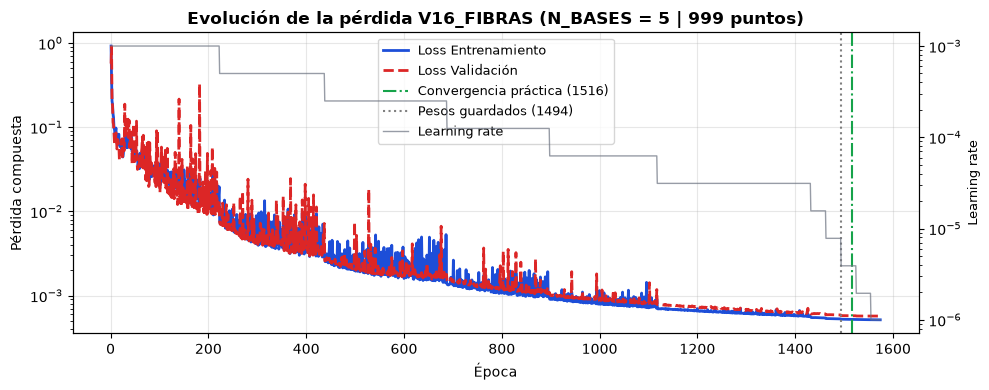

In [12]:
# ==============================================================================
# CÉLULA 8: ENTRENAMIENTO (O CARGA DEL MODELO GUARDADO) Y GUARDADO DE MODELO + ESCALADORES
# ==============================================================================
"""
ENTRENAR = True  → entrena, guarda modelo, escaladores e historial.
ENTRENAR = False → carga el modelo y el historial guardados (no reentrena). Sirve para volver a
                   correr la evaluación (Células 8b en adelante) con el modelo ya entrenado.
                   Requiere haber ejecutado antes las Células G a 7 (mismo dataset y escaladores).

Época de los pesos guardados: con restore_best_weights y min_delta, Keras restaura la última época
cuya val_loss mejoró en más de MIN_DELTA_VAL (no necesariamente el mínimo absoluto). Se reconstruye
desde el historial con la misma regla que EarlyStopping (verificada contra Keras).
"""
import os
import time
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, TerminateOnNaN
from tensorflow.keras.models import load_model

ENTRENAR = False             # False = cargar el modelo guardado y saltear el entrenamiento

PATIENCE_EARLY_STOP = 80
PATIENCE_LR = 30            # V14: la meseta con lr ≈ 3e-5 (épocas 230–600) fue la etapa más productiva
MIN_DELTA_VAL = 1e-5        # mejora mínima de val_loss que cuenta (V12 seguía "mejorando" en el 5.º decimal)
EPOCHS = 2000               # tope; V14 cortó en 1000 todavía bajando (~15 % en las últimas 280 épocas)
BATCH_SIZE = 64
TOL_CONVERGENCIA = 0.01     # época de convergencia práctica: val_loss dentro del 1 % del mejor valor
ARCHIVO_HISTORIAL = f"historial_entrenamiento_{VERSION}.csv"


def epoca_restaurada(val_loss, min_delta, epochs_tope):
    """Época (1-based) cuyos pesos deja EarlyStopping(restore_best_weights=True, min_delta)."""
    if len(val_loss) >= epochs_tope:          # no hubo corte anticipado: quedan los pesos de la última época
        return len(val_loss)
    mejor, ep = np.inf, len(val_loss)
    for i, v in enumerate(val_loss):
        if v + min_delta < mejor:
            mejor, ep = v, i + 1
    return ep


if ENTRENAR:
    callbacks = [
        TerminateOnNaN(),
        EarlyStopping(monitor='val_loss', patience=PATIENCE_EARLY_STOP, min_delta=MIN_DELTA_VAL,
                      restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=PATIENCE_LR, min_delta=MIN_DELTA_VAL,
                          min_lr=1e-6, verbose=1),
        ModelCheckpoint(filepath=ARCHIVO_MODELO, monitor='val_loss', save_best_only=True, verbose=0),
    ]
    print(f"🚀 Entrenamiento {VERSION.upper()} para N = {N_BASES} bases ({N_PUNTOS} pts) | validación ≠ test...")
    t_start = time.time()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),      # el test NO participa en el entrenamiento ni en la selección
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=1,
    )
    t_elapsed = time.time() - t_start
    hist = pd.DataFrame(history.history)
    hist.index = np.arange(1, len(hist) + 1)
    hist.index.name = "epoca"

    # --- Guardado coherente con la Célula 14 ---------------------------------------------
    model.save(ARCHIVO_MODELO)               # pesos restaurados por EarlyStopping
    with open(ARCHIVO_SCALERS, "wb") as f:
        pickle.dump({
            "scaler_x": sx,
            "scaler_y": sy,
            "offset_log": OFFSET_LOG,
            "max_coef": MAX_COEF,
            "n_bases": N_BASES,
            "x_mesh": X_MESH_999,
            "version": VERSION,
        }, f)
    hist.to_csv(ARCHIVO_HISTORIAL)
    print(f"\n✅ Entrenamiento completado en {t_elapsed/60:.2f} min ({len(hist)} épocas ejecutadas).")
    print(f"💾 Modelo → '{ARCHIVO_MODELO}' | Escaladores + OFFSET_LOG → '{ARCHIVO_SCALERS}' | "
          f"Historial → '{ARCHIVO_HISTORIAL}'")
else:
    for f in (ARCHIVO_MODELO, ARCHIVO_SCALERS, ARCHIVO_HISTORIAL):
        if not os.path.exists(f):
            raise FileNotFoundError(f"No se encontró '{f}': ejecutá la Célula 8 con ENTRENAR = True.")
    model = load_model(ARCHIVO_MODELO, compile=False)
    with open(ARCHIVO_SCALERS, "rb") as f:
        _meta = pickle.load(f)
    # Los escaladores de la Célula 5 deben coincidir con los guardados (mismo dataset).
    _ok = (np.allclose(_meta["scaler_x"].mean_, sx.mean_) and np.allclose(_meta["scaler_x"].scale_, sx.scale_)
           and np.allclose(_meta["scaler_y"].mean_, sy.mean_, atol=1e-6) and np.allclose(_meta["scaler_y"].scale_, sy.scale_, atol=1e-6))
    if not _ok:
        raise ValueError("Los escaladores de la Célula 5 no coinciden con los guardados: el dataset cambió. "
                         "Reentrená con ENTRENAR = True.")
    hist = pd.read_csv(ARCHIVO_HISTORIAL, index_col="epoca")
    print(f"📦 Modelo cargado desde '{ARCHIVO_MODELO}' (sin reentrenar) | escaladores verificados | "
          f"historial: {len(hist)} épocas.")

val_hist = hist['val_loss'].to_numpy()
argmin_ep = int(np.argmin(val_hist)) + 1
best_ep = epoca_restaurada(val_hist, MIN_DELTA_VAL, EPOCHS)
ep_conv = int(np.argmax(val_hist <= val_hist.min() * (1.0 + TOL_CONVERGENCIA))) + 1
lr_col = next((c for c in ("learning_rate", "lr") if c in hist.columns), None)

print(f"   • Época de los pesos guardados: {best_ep} | val_loss: {val_hist[best_ep - 1]:.6f} | "
      f"loss de entrenamiento: {hist['loss'].iloc[best_ep - 1]:.6f}")
print(f"   • Mínimo absoluto de val_loss: {val_hist.min():.6f} en la época {argmin_ep} "
      f"(diferencia {val_hist[best_ep - 1] - val_hist.min():.2e}; min_delta = {MIN_DELTA_VAL:g})")
print(f"   • Convergencia práctica (val_loss a ≤ {TOL_CONVERGENCIA:.0%} del mejor): época {ep_conv}")
_ventana = min(200, len(val_hist) // 4)
if len(val_hist) >= EPOCHS and _ventana > 10:
    _baja = 1.0 - val_hist[-1] / val_hist[-_ventana]
    print(f"   ⚠️ Se alcanzó el tope de {EPOCHS} épocas sin corte anticipado: val_loss bajó {_baja:.1%} en las "
          f"últimas {_ventana} épocas ({'todavía mejorando' if _baja > 0.02 else 'prácticamente convergido'}).")
print(f"   • MAE de validación en la época guardada (espacio estandarizado): {hist['val_mae'].iloc[best_ep - 1]:.6f}")
if lr_col:
    print(f"   • Learning rate final: {hist[lr_col].iloc[-1]:.2e}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hist.index, hist['loss'], label='Loss Entrenamiento', color='#1d4ed8', linewidth=2)
ax.plot(hist.index, val_hist, label='Loss Validación', color='#dc2626', linewidth=2, linestyle='--')
ax.axvline(ep_conv, color='#16a34a', linestyle='-.', label=f'Convergencia práctica ({ep_conv})')
ax.axvline(best_ep, color='gray', linestyle=':', label=f'Pesos guardados ({best_ep})')
ax.set_title(f'Evolución de la pérdida {VERSION.upper()} (N_BASES = {N_BASES} | {N_PUNTOS} puntos)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Época', fontsize=10)
ax.set_ylabel('Pérdida compuesta', fontsize=10)
ax.set_yscale('log')
ax.grid(True, alpha=0.3)
if lr_col:
    ax_lr = ax.twinx()
    ax_lr.plot(hist.index, hist[lr_col], color='#6b7280', linewidth=1, alpha=0.7, label='Learning rate')
    ax_lr.set_yscale('log')
    ax_lr.set_ylabel('Learning rate', fontsize=9)
    l1, n1 = ax.get_legend_handles_labels()
    l2, n2 = ax_lr.get_legend_handles_labels()
    ax.legend(l1 + l2, n1 + n2, fontsize=9)
else:
    ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f"evolucion_perdida_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Célula 8b — Evaluación base en test (la reutilizan 9, 12 y 13)

In [13]:
# ==============================================================================
# CÉLULA 8b: EVALUACIÓN BASE SOBRE EL CONJUNTO DE TEST (la usan las Células 9, 12 y 13)
# ==============================================================================
"""
Un único lugar para la inferencia sobre test:
  • coef_crudo : salida de la red desestandarizada (sin proyectar).
  • coef_rn    : proyección de coef_crudo sobre la caja [0, MAX_COEF] (paso explícito del método).
  • coef_lsq   : óptimo acotado de la curva de ENTRADA (techo alcanzable con las bases).
  • coef_opt   : etiqueta (= coef_lsq: la etiqueta es el óptimo acotado de la curva de entrada).
  • coef_pul   : red + pulido (conjunto activo de la red + mínimos cuadrados en los libres + KKT).
                 Si la red identificó bien el conjunto activo, coef_pul ES el óptimo exacto.
  • b_limpio   : curva SIN ruido (la verdadera); permite medir el error contra la curva verdadera.
"""
import time
import numpy as np

N_CRONO_LSQ = 300   # curvas para cronometrar lsq_linear


def evaluar_test():
    y_pred_norm = model.predict(X_test, batch_size=1024, verbose=0)
    coef_crudo = sy.inverse_transform(y_pred_norm)
    coef_rn = np.clip(coef_crudo, COEF_MIN, MAX_COEF)
    coef_opt = sy.inverse_transform(y_test)
    b_in = Y_raw[idx_test]
    coef_lsq = coef_opt.copy()
    return {
        "coef_crudo": coef_crudo,
        "coef_rn": coef_rn,                              # (n_test, N_BASES) predicho y proyectado
        "coef_opt": coef_opt,                            # (n_test, N_BASES) etiqueta
        "coef_lsq": coef_lsq,                            # (n_test, N_BASES) óptimo de la entrada
        "b_rn": coef_rn @ A_base.T,                      # curva reconstruida por la red
        "b_opt": coef_opt @ A_base.T,                    # curva reconstruida con la etiqueta
        "b_lsq": coef_lsq @ A_base.T,                    # mejor reconstrucción posible de la entrada
        "b_in": b_in,                                    # curva REAL de entrada a la red
        "b_limpio": Y_limpio[idx_test],                  # curva verdadera, sin ruido
        "fam": fam_test,
        "idx": idx_test,
    }


EVAL = evaluar_test()
n_test = EVAL["coef_rn"].shape[0]
_pul = [pulir(A_base, y, c) for y, c in zip(EVAL["b_in"], EVAL["coef_crudo"])]
EVAL["coef_pul"] = np.array([p[0] for p in _pul])
EVAL["pul_exacto"] = np.array([p[1] for p in _pul])
EVAL["b_pul"] = EVAL["coef_pul"] @ A_base.T
neg = EVAL["coef_crudo"] < COEF_MIN
sobre = EVAL["coef_crudo"] > MAX_COEF
print(f"✅ Evaluación base lista: {n_test} curvas de test, {EVAL['coef_rn'].shape[1]} coeficientes.")
print(f"   • Predicciones crudas fuera de la caja (antes de proyectar): "
      f"negativas {neg.mean():.2%} de los coeficientes ({neg.any(axis=1).mean():.2%} de las curvas, "
      f"mínimo {EVAL['coef_crudo'].min():.4f}) | > MAX_COEF {sobre.mean():.2%}")

print(f"   • Pulido (conjunto activo de la red + KKT): la red identificó el conjunto activo exacto en "
      f"{EVAL['pul_exacto'].mean():.2%} de las curvas | |c_pul − c_opt| máx. = "
      f"{np.abs(EVAL['coef_pul'] - EVAL['coef_opt']).max():.1e}")
for f, nombre in FAMILIAS.items():
    m = EVAL["fam"] == f
    print(f"       {nombre:<20}: conjunto activo exacto {EVAL['pul_exacto'][m].mean():7.2%}")

# --- Cronometraje justo: red en lote vs. lsq_linear curva a curva -----------------------------
Y_crono = Y_raw[idx_test]
t0 = time.perf_counter()
_ = np.clip(sy.inverse_transform(model.predict(sx.transform(safe_log_transform(Y_crono)),
                                               batch_size=1024, verbose=0)), COEF_MIN, MAX_COEF)
t_rn = (time.perf_counter() - t0) / len(Y_crono)
t0 = time.perf_counter()
for y in Y_crono[:N_CRONO_LSQ]:
    lsq_acotado(A_base, y)
t_lsq = (time.perf_counter() - t0) / N_CRONO_LSQ
TIEMPOS = {"rn_ms_por_curva": t_rn * 1e3, "lsq_ms_por_curva": t_lsq * 1e3}
print(f"   • Tiempo por curva (incluye log + escalado): red en lote {t_rn*1e3:.4f} ms | "
      f"lsq_linear[{METODO_LSQ}] {t_lsq*1e3:.3f} ms → factor {t_lsq / t_rn:.1f}×")
print("     (referencia de velocidad, no aporte central: un solver exacto vectorizado para tan pocas variables sería competitivo)")

✅ Evaluación base lista: 6000 curvas de test, 5 coeficientes.
   • Predicciones crudas fuera de la caja (antes de proyectar): negativas 17.74% de los coeficientes (33.37% de las curvas, mínimo -0.0870) | > MAX_COEF 0.01%
   • Pulido (conjunto activo de la red + KKT): la red identificó el conjunto activo exacto en 73.35% de las curvas | |c_pul − c_opt| máx. = 1.6e-06
       pura                : conjunto activo exacto  18.33%
       combinada           : conjunto activo exacto  48.75%
       constitutiva        : conjunto activo exacto  99.83%
       constitutiva_amplia : conjunto activo exacto  99.87%
       exponencial         : conjunto activo exacto 100.00%
   • Tiempo por curva (incluye log + escalado): red en lote 0.0582 ms | lsq_linear[bvls] 0.198 ms → factor 3.4×
     (referencia de velocidad, no aporte central: un solver exacto vectorizado para tan pocas variables sería competitivo)


## Célula 9 — Reconstrucción física en test (una muestra por familia)

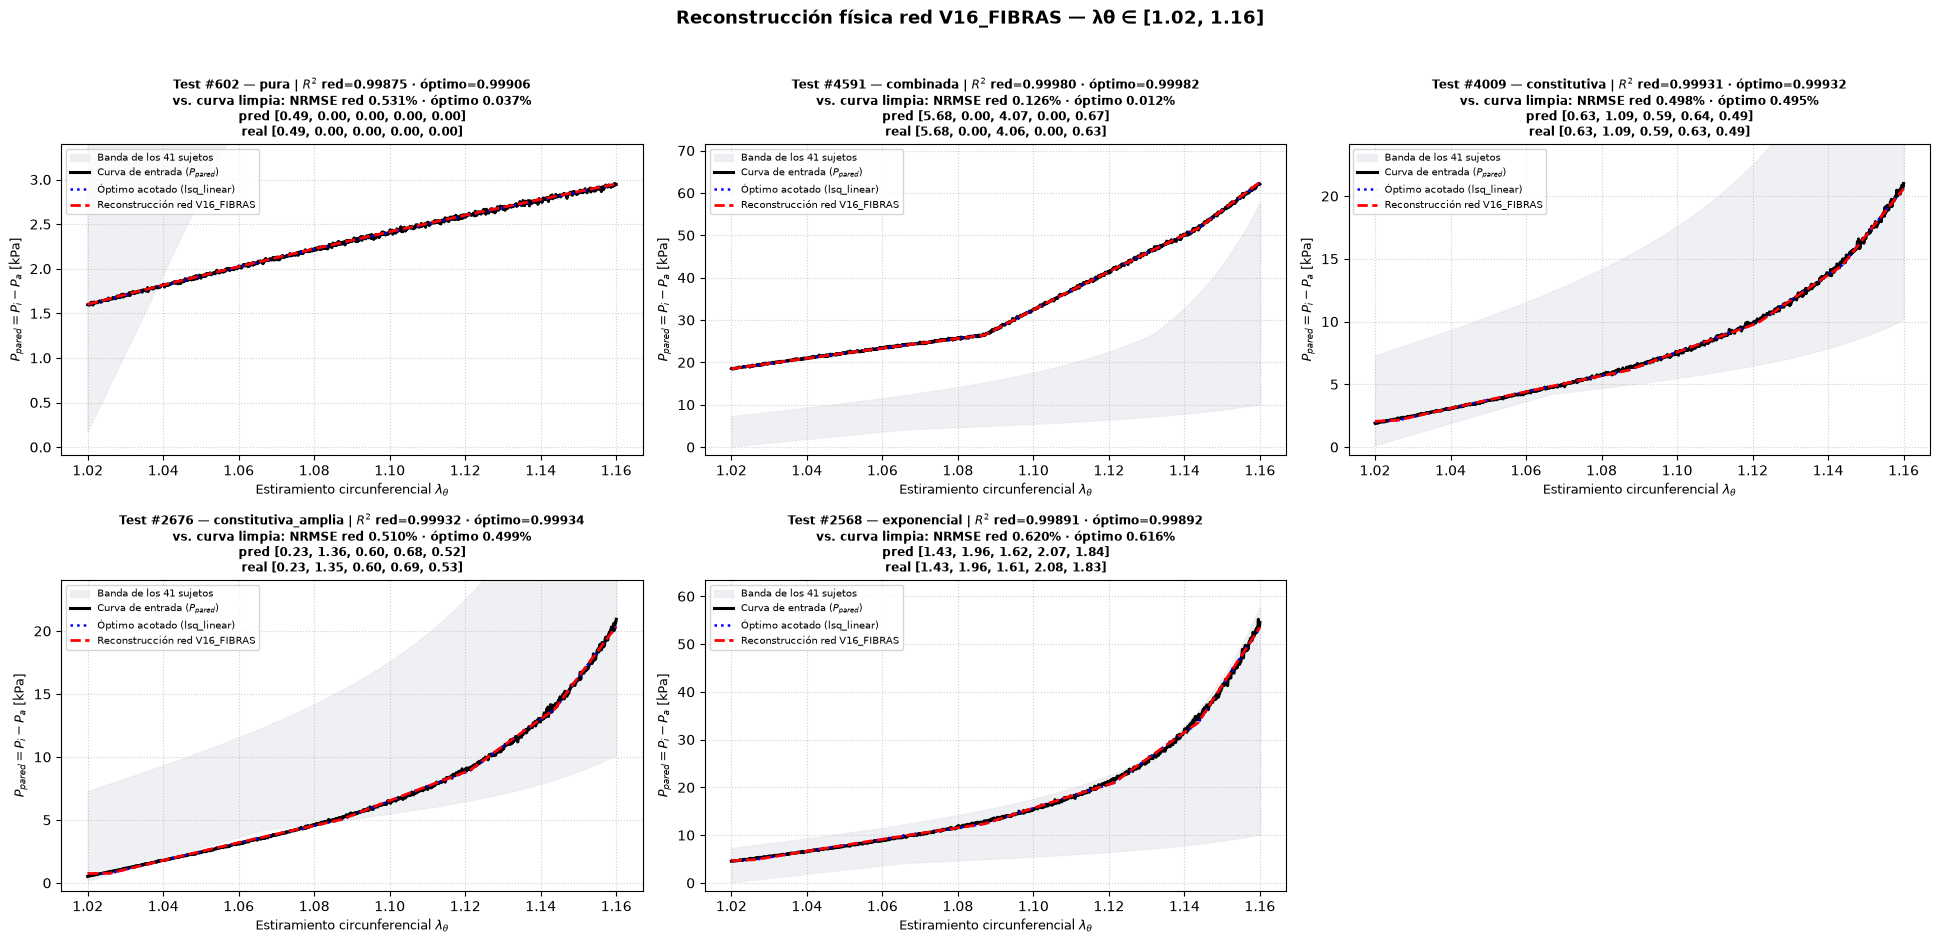

📏 NRMSE medio contra la curva LIMPIA (verdadera) vs. contra la entrada con ruido, por familia:
   • pura                : vs. limpia — red 0.095% | óptimo 0.018%   (vs. entrada con ruido — red 0.372%)
   • combinada           : vs. limpia — red 0.219% | óptimo 0.020%   (vs. entrada con ruido — red 0.353%)
   • constitutiva        : vs. limpia — red 0.490% | óptimo 0.478%   (vs. entrada con ruido — red 0.739%)
   • constitutiva_amplia : vs. limpia — red 0.505% | óptimo 0.486%   (vs. entrada con ruido — red 0.748%)
   • exponencial         : vs. limpia — red 0.533% | óptimo 0.511%   (vs. entrada con ruido — red 0.757%)

=== INFERENCIA EN LAS CURVAS MEDIAS RECONSTRUIDAS (grupos de las Figs. 5a y 7a) ===
✅ Mean Young : c proyectado = [1.3395 0.8368 0.4205 0.4594 0.3409] | óptimo = [1.3412 0.8365 0.4187 0.4601 0.3389]
✅ Mean Old   : c proyectado = [0.9201 1.2918 0.8946 0.9867 0.718 ] | óptimo = [0.9143 1.2917 0.8961 0.9861 0.7253]
✅ Mean NT    : c proyectado = [0.9561 1.2878 0.8547 0.9546 0

In [14]:
# ==============================================================================
# CÉLULA 9: RECONSTRUCCIÓN FÍSICA EN TEST (UNA MUESTRA ALEATORIA POR FAMILIA)
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt

x_mesh = X_MESH_999
rng_plot = np.random.default_rng(SEED)
idx_muestras = [int(rng_plot.choice(np.where(EVAL["fam"] == f)[0])) for f in sorted(FAMILIAS)]

n_cols = 3
n_rows = int(np.ceil(len(idx_muestras) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.5 * n_cols, 4.6 * n_rows), squeeze=False)
for ax in axes.flatten()[len(idx_muestras):]:
    ax.axis("off")
for ax, s in zip(axes.flatten(), idx_muestras):
    b_in, b_rn, b_lsq, b_0 = EVAL["b_in"][s], EVAL["b_rn"][s], EVAL["b_lsq"][s], EVAL["b_limpio"][s]
    c_pred, c_true = EVAL["coef_rn"][s], EVAL["coef_opt"][s]
    m_rn, m_lsq = metricas_curva(b_in, b_rn), metricas_curva(b_in, b_lsq)
    m0_rn, m0_lsq = metricas_curva(b_0, b_rn), metricas_curva(b_0, b_lsq)

    ax.fill_between(x_mesh, BANDA_INF, BANDA_SUP, color="#e5e7eb", alpha=0.6, label="Banda de los 41 sujetos")
    ax.plot(x_mesh, b_in, 'k-', lw=2.2, label='Curva de entrada ($P_{pared}$)')
    ax.plot(x_mesh, b_lsq, 'b:', lw=1.8, label='Óptimo acotado (lsq_linear)')
    ax.plot(x_mesh, b_rn, 'r--', lw=2.0, label=f'Reconstrucción red {VERSION.upper()}')
    ax.set_ylim(bottom=-0.03 * max(b_in.max(), 1.0), top=1.15 * max(b_in.max(), 1.0))

    coef_str = ", ".join(f"{c_pred[i]:.2f}" for i in range(N_BASES))
    true_str = ", ".join(f"{c_true[i]:.2f}" for i in range(N_BASES))
    ax.set_title(f"Test #{s} — {FAMILIAS[int(EVAL['fam'][s])]} | $R^2$ red={m_rn['R2']:.5f} · óptimo={m_lsq['R2']:.5f}\n"
                 f"vs. curva limpia: NRMSE red {m0_rn['NRMSE']:.3f}% · óptimo {m0_lsq['NRMSE']:.3f}%\n"
                 f"pred [{coef_str}]\nreal [{true_str}]", fontsize=8.5, fontweight='bold')
    ax.set_xlabel(r"Estiramiento circunferencial $\lambda_\theta$", fontsize=9)
    ax.set_ylabel(ETQ_Y, fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper left', fontsize=7)

plt.suptitle(f"Reconstrucción física red {VERSION.upper()} — λθ ∈ [{X_MIN_DOMINIO}, {X_MAX_DOMINIO}]",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f"reconstruccion_curvas_test_{VERSION}.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# --- Error contra la curva verdadera (sin ruido): el R² contra la entrada ruidosa tiene un techo ---------
print("📏 NRMSE medio contra la curva LIMPIA (verdadera) vs. contra la entrada con ruido, por familia:")
M0_rn = metricas_lote(EVAL["b_limpio"], EVAL["b_rn"]); M0_lsq = metricas_lote(EVAL["b_limpio"], EVAL["b_lsq"])
Mi_rn = metricas_lote(EVAL["b_in"], EVAL["b_rn"])
for f, nombre in FAMILIAS.items():
    m = EVAL["fam"] == f
    print(f"   • {nombre:<20}: vs. limpia — red {np.nanmean(M0_rn['NRMSE'][m]):.3f}% | óptimo {np.nanmean(M0_lsq['NRMSE'][m]):.3f}%"
          f"   (vs. entrada con ruido — red {np.nanmean(Mi_rn['NRMSE'][m]):.3f}%)")

# --- Inferencia sobre las 4 curvas medias reconstruidas (la comparación completa está en la Célula 10) ---
print("\n=== INFERENCIA EN LAS CURVAS MEDIAS RECONSTRUIDAS (grupos de las Figs. 5a y 7a) ===")
for nombre, y_m in MEDIAS_RECONSTRUIDAS.items():
    Xn = sx.transform(safe_log_transform(y_m).reshape(1, -1))
    c_crudo = sy.inverse_transform(model.predict(Xn, verbose=0))[0].astype(np.float64)
    c_fr = np.clip(c_crudo, COEF_MIN, MAX_COEF)
    print(f"✅ {nombre:<11}: c proyectado = {np.round(c_fr, 4)} | óptimo = {np.round(lsq_acotado(A_base, y_m), 4)}")

## Célula 10 — Validación con curvas reales: 41 sujetos y 4 curvas medias (red vs. óptimo, pulido, KKT)

In [15]:
# ==============================================================================
# CÉLULA 10: VALIDACIÓN CON CURVAS REALES — 41 SUJETOS Y 4 CURVAS MEDIAS (RED vs. ÓPTIMO + KKT)
# ==============================================================================
"""
Curvas reales = P_pared(λθ) reconstruidas con los parámetros publicados de cada sujeto (Célula M), sin
ruido. Los sujetos marcados como test no participaron del generador ni del diseño de las bases:
son la validación independiente. Las 4 curvas medias (grupos de las Figs. 5a y 7a) promedian
sujetos de entrenamiento y de test.

Para cada curva:
  • Óptimo: lsq_linear (bvls) con la caja [0, MAX_COEF], la misma referencia de las etiquetas.
  • Verificación KKT post-hoc con g = Aᵀ(A c* − y): cota inferior activa → μ_i = g_i >= 0;
    superior activa → ν_i = −g_i >= 0; componente libre → g_i ≈ 0. Se cruza con active_mask.
  • Control de clase (es_curva_J) antes de la red.
"""
import time
import numpy as np
import pandas as pd
from scipy.optimize import lsq_linear

N_REP_TIEMPO = 50
TOL_ACTIVA = 1e-6


def _mediana_tiempo(fn, n=N_REP_TIEMPO):
    ts = []
    for _ in range(n):
        t0 = time.perf_counter()
        fn()
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts))


def verificacion_kkt(A, y, c, active_mask):
    g = A.T @ (A @ c - y)
    inf = c <= COEF_MIN + TOL_ACTIVA
    sup = c >= MAX_COEF - TOL_ACTIVA
    libre = ~(inf | sup)
    mu, nu = np.where(inf, g, 0.0), np.where(sup, -g, 0.0)
    escala = max(float(np.linalg.norm(A.T @ y)), 1e-12)
    return {"mu_inf": mu, "nu_sup": nu, "activas_inf": np.where(inf)[0] + 1, "activas_sup": np.where(sup)[0] + 1,
            "estacionariedad_rel": (float(np.max(np.abs(g[libre]))) if libre.any() else 0.0) / escala,
            "signos_ok": bool(np.all(mu >= -1e-8 * escala) and np.all(nu >= -1e-8 * escala)),
            "coincide_active_mask": bool(np.array_equal(inf, active_mask == -1) and np.array_equal(sup, active_mask == 1))}


def evaluar_curva_real(y, nombre):
    res = lsq_linear(A_base, y, bounds=(COEF_MIN, MAX_COEF), method=METODO_LSQ)
    Xn = sx.transform(safe_log_transform(y).reshape(1, -1))
    c_crudo = sy.inverse_transform(model(Xn, training=False).numpy()).flatten().astype(np.float64)
    c_rn = np.clip(c_crudo, COEF_MIN, MAX_COEF)
    c_pul, pul_exacto = pulir(A_base, y, c_crudo)
    b_rn, b_opt = A_base @ c_rn, A_base @ res.x
    m_rn, m_opt = metricas_curva(y, b_rn), metricas_curva(y, b_opt)
    return {"nombre": nombre, "y": y, "coef_pred": c_rn, "coef_crudo": c_crudo, "coef_opt": res.x,
            "coef_pul": c_pul, "pul_exacto": pul_exacto,
            "b_rn": b_rn, "b_opt": b_opt, "m_rn": m_rn, "m_opt": m_opt, "en_clase": es_curva_J(y),
            "kkt": verificacion_kkt(A_base, y, res.x, res.active_mask)}


# --- 1. Los 41 sujetos -------------------------------------------------------------------------
RES_SUJETOS = [evaluar_curva_real(y, r["id"]) for (_, r), y in zip(POB.iterrows(), POB_Y)]
filas = []
for (_, r), e in zip(POB.iterrows(), RES_SUJETOS):
    filas.append(dict(id=r["id"], grupo=r["grupo"], test=bool(r["test"]), en_clase=e["en_clase"],
                      R2_red=e["m_rn"]["R2"], R2_opt=e["m_opt"]["R2"],
                      NRMSE_red=e["m_rn"]["NRMSE"], NRMSE_opt=e["m_opt"]["NRMSE"],
                      MaxAE_rel_red=e["m_rn"]["MaxAE_rel"], MaxAE_rel_opt=e["m_opt"]["MaxAE_rel"],
                      dc_max=float(np.max(np.abs(e["coef_pred"] - e["coef_opt"]))),
                      pul_exacto=e["pul_exacto"], dc_pul=float(np.max(np.abs(e["coef_pul"] - e["coef_opt"]))),
                      kkt_estac=e["kkt"]["estacionariedad_rel"], kkt_signos=e["kkt"]["signos_ok"],
                      kkt_mask=e["kkt"]["coincide_active_mask"], cotas_activas=len(e["kkt"]["activas_inf"]) + len(e["kkt"]["activas_sup"])))
DF_SUJETOS = pd.DataFrame(filas)
DF_SUJETOS["exceso_NRMSE_pct"] = (DF_SUJETOS["NRMSE_red"] / DF_SUJETOS["NRMSE_opt"] - 1.0) * 100
DF_SUJETOS.to_csv(f"validacion_sujetos_reales_{VERSION}.csv", index=False)

print("=" * 112)
print(f"🫀 VALIDACIÓN CON LOS {len(POB)} SUJETOS REALES (P_pared reconstruida, sin ruido)")
print("=" * 112)
print(f"{'Subconjunto':<20} {'n':>3} | {'R² ópt.':>8} {'R² red':>8} {'mín. red':>9} | {'NRMSE ópt.':>10} {'NRMSE red':>10} "
      f"{'Exceso':>8} | {'MaxAE_rel red máx.':>18} | {'máx |Δc|':>8}")
print("-" * 112)
for etiqueta, m in [("Test (reservados)", DF_SUJETOS["test"]), ("Entrenamiento", ~DF_SUJETOS["test"]),
                    ("NT", DF_SUJETOS["grupo"] == "NT"), ("HT", DF_SUJETOS["grupo"] == "HT"),
                    ("Todos", DF_SUJETOS["grupo"].notna())]:
    d = DF_SUJETOS[m.to_numpy()]
    exc = (d["NRMSE_red"].mean() / d["NRMSE_opt"].mean() - 1) * 100
    print(f"{etiqueta:<20} {len(d):>3} | {d['R2_opt'].mean():8.5f} {d['R2_red'].mean():8.5f} {d['R2_red'].min():9.5f} | "
          f"{d['NRMSE_opt'].mean():9.3f}% {d['NRMSE_red'].mean():9.3f}% {exc:+7.1f}% | {d['MaxAE_rel_red'].max():17.2f}% | "
          f"{d['dc_max'].max():8.4f}")
print("-" * 112)
print(f"KKT en los {len(DF_SUJETOS)} óptimos: estacionariedad relativa máx. {DF_SUJETOS['kkt_estac'].max():.1e} | "
      f"signos correctos: {DF_SUJETOS['kkt_signos'].all()} | coincide con active_mask: {DF_SUJETOS['kkt_mask'].all()} | "
      f"curvas con cotas activas: {(DF_SUJETOS['cotas_activas'] > 0).sum()}")
print(f"Control de clase (es_curva_J): {DF_SUJETOS['en_clase'].mean():.0%} de los sujetos reales aceptados.")
print(f"Red + pulido: conjunto activo exacto en {DF_SUJETOS['pul_exacto'].mean():.0%} de los sujetos | "
      f"máx |c_pul − c_opt| = {DF_SUJETOS['dc_pul'].max():.1e} (≈ 0 ⇒ red + pulido = óptimo exacto)")
peor = DF_SUJETOS.loc[DF_SUJETOS["R2_red"].idxmin()]
print(f"Peor sujeto: {peor['id']} ({'test' if peor['test'] else 'entrenamiento'}) — R² red {peor['R2_red']:.5f} "
      f"vs. óptimo {peor['R2_opt']:.5f}")
if "NT08" in set(DF_SUJETOS["id"]):
    _n8 = DF_SUJETOS.set_index("id").loc["NT08"]
    print(f"NT08 (arteria más blanda de la población): R² red {_n8['R2_red']:.5f} vs. óptimo {_n8['R2_opt']:.5f} "
          f"| exceso NRMSE {_n8['exceso_NRMSE_pct']:+.1f}%")
_d_t = DF_SUJETOS[DF_SUJETOS["test"]]
print(f"Test: exceso NRMSE mediano por sujeto {_d_t['exceso_NRMSE_pct'].median():+.1f}% | "
      f"máximo {_d_t['exceso_NRMSE_pct'].max():+.1f}% ({_d_t.loc[_d_t['exceso_NRMSE_pct'].idxmax(), 'id']})")

# --- 2. Las 4 curvas medias reconstruidas ------------------------------------------------------
RES_MEDIAS = {k: evaluar_curva_real(y, k) for k, y in MEDIAS_RECONSTRUIDAS.items()}
y_ej = MEDIAS_RECONSTRUIDAS["Mean HT"]
t_lsq = _mediana_tiempo(lambda: lsq_acotado(A_base, y_ej))
t_rn = _mediana_tiempo(lambda: model(sx.transform(safe_log_transform(y_ej).reshape(1, -1)), training=False))


def reportar_media(r):
    k = r["kkt"]
    print("\n" + "=" * 92)
    print(f"{r['nombre']} (reconstruida; n = {int(GRUPOS_MEDIAS[r['nombre']].sum())} sujetos)")
    print("=" * 92)
    print(f"Coeficientes óptimos (lsq_linear): {np.round(r['coef_opt'], 4)}")
    print(f"Coeficientes red                 : {np.round(r['coef_pred'], 4)}   (crudos: {np.round(r['coef_crudo'], 4)})")
    print(f"Cotas activas: inferior {k['activas_inf'].tolist() or '—'} | superior {k['activas_sup'].tolist() or '—'} | "
          f"KKT: estacionariedad {k['estacionariedad_rel']:.1e}, signos {k['signos_ok']}, active_mask {k['coincide_active_mask']}")
    print(f"{'':<12} {'R²':>10} {'RMSE [kPa]':>11} {'MaxAE [kPa]':>12} {'NRMSE':>9} {'MaxAE_rel':>10}")
    for etiqueta, m in [("Red", r["m_rn"]), ("Óptimo lsq", r["m_opt"])]:
        print(f"{etiqueta:<12} {m['R2']:10.6f} {m['RMSE']:11.4f} {m['MaxAE']:12.4f} {m['NRMSE']:8.4f}% {m['MaxAE_rel']:9.3f}%")
    print(f"Exceso de RMSE de la red sobre el óptimo: {(r['m_rn']['RMSE'] / r['m_opt']['RMSE'] - 1.0) * 100:+.2f}%")


for r in RES_MEDIAS.values():
    reportar_media(r)
print(f"\nTiempo por curva (mediana de {N_REP_TIEMPO}): lsq_linear[{METODO_LSQ}] {t_lsq*1e3:.3f} ms | "
      f"red (1 curva, incluye overhead de Keras) {t_rn*1e3:.3f} ms")

🫀 VALIDACIÓN CON LOS 41 SUJETOS REALES (P_pared reconstruida, sin ruido)
Subconjunto            n |  R² ópt.   R² red  mín. red | NRMSE ópt.  NRMSE red   Exceso | MaxAE_rel red máx. | máx |Δc|
----------------------------------------------------------------------------------------------------------------
Test (reservados)     10 |  0.99960  0.99953   0.99913 |     0.500%     0.536%    +7.2% |              3.61% |   0.0223
Entrenamiento         31 |  0.99963  0.99959   0.99895 |     0.475%     0.502%    +5.7% |              3.03% |   0.0207
NT                    16 |  0.99965  0.99955   0.99895 |     0.462%     0.522%   +13.0% |              3.61% |   0.0223
HT                    25 |  0.99961  0.99959   0.99940 |     0.494%     0.503%    +1.9% |              2.30% |   0.0161
Todos                 41 |  0.99963  0.99958   0.99895 |     0.481%     0.511%    +6.1% |              3.61% |   0.0223
----------------------------------------------------------------------------------------------

## Célula 11 — Figuras de validación: curvas medias y sujetos reservados

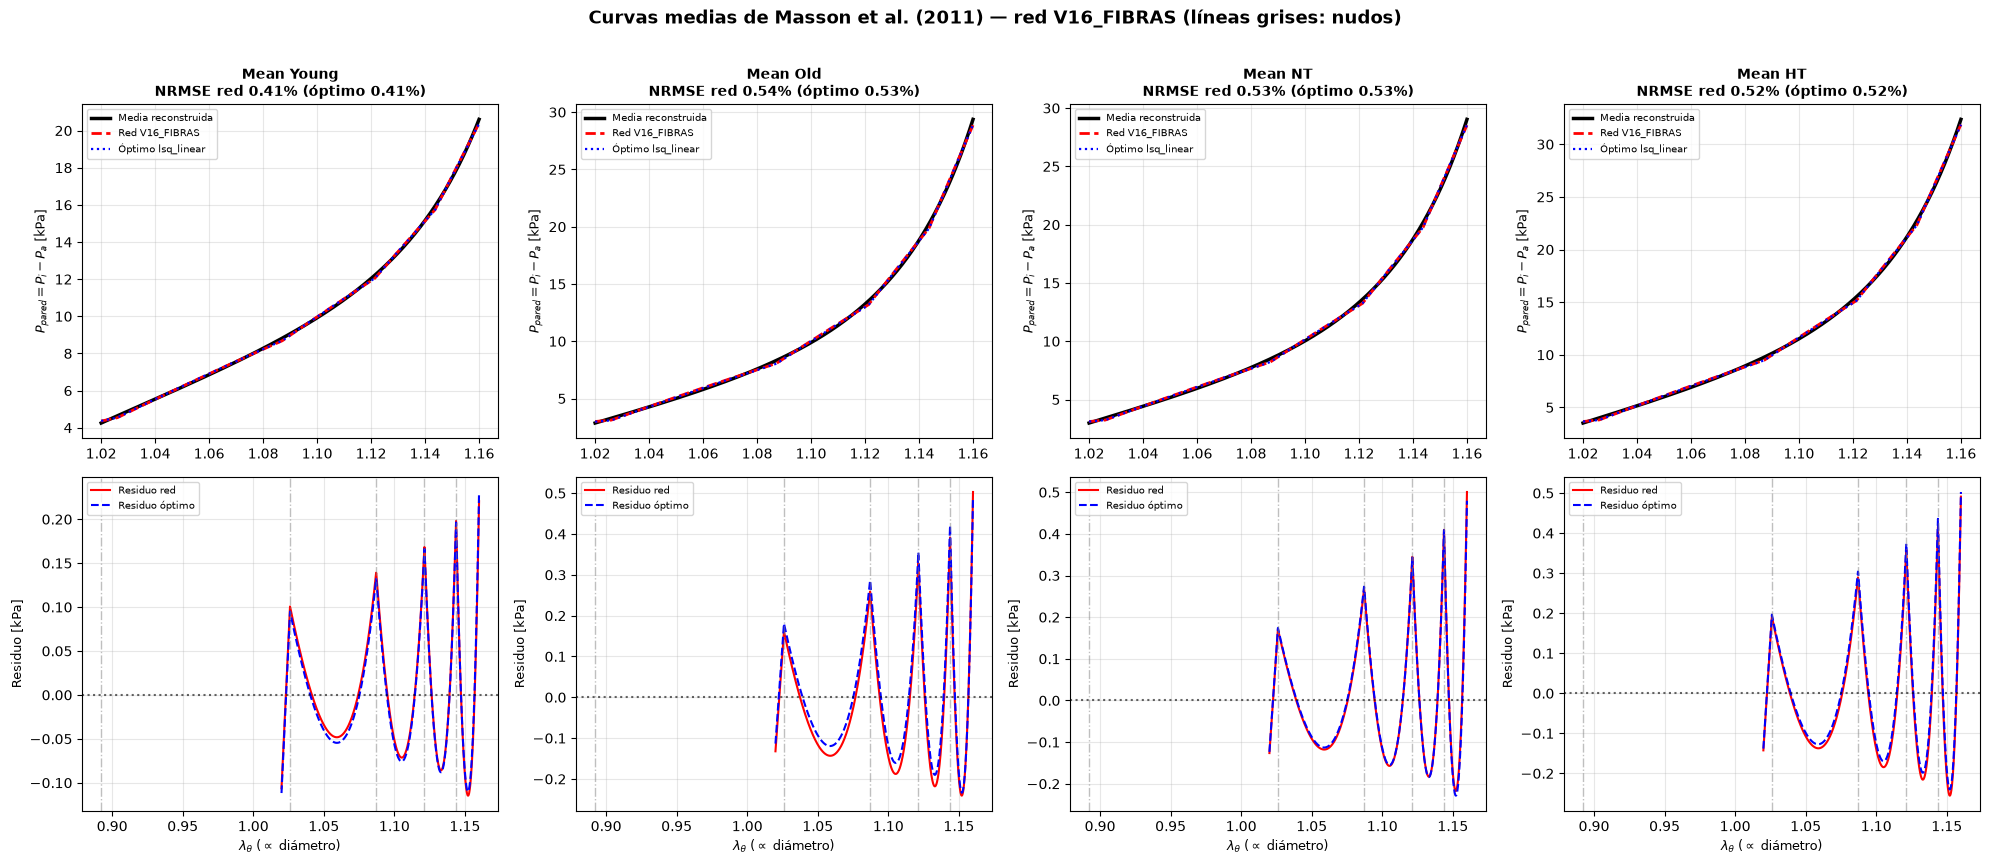

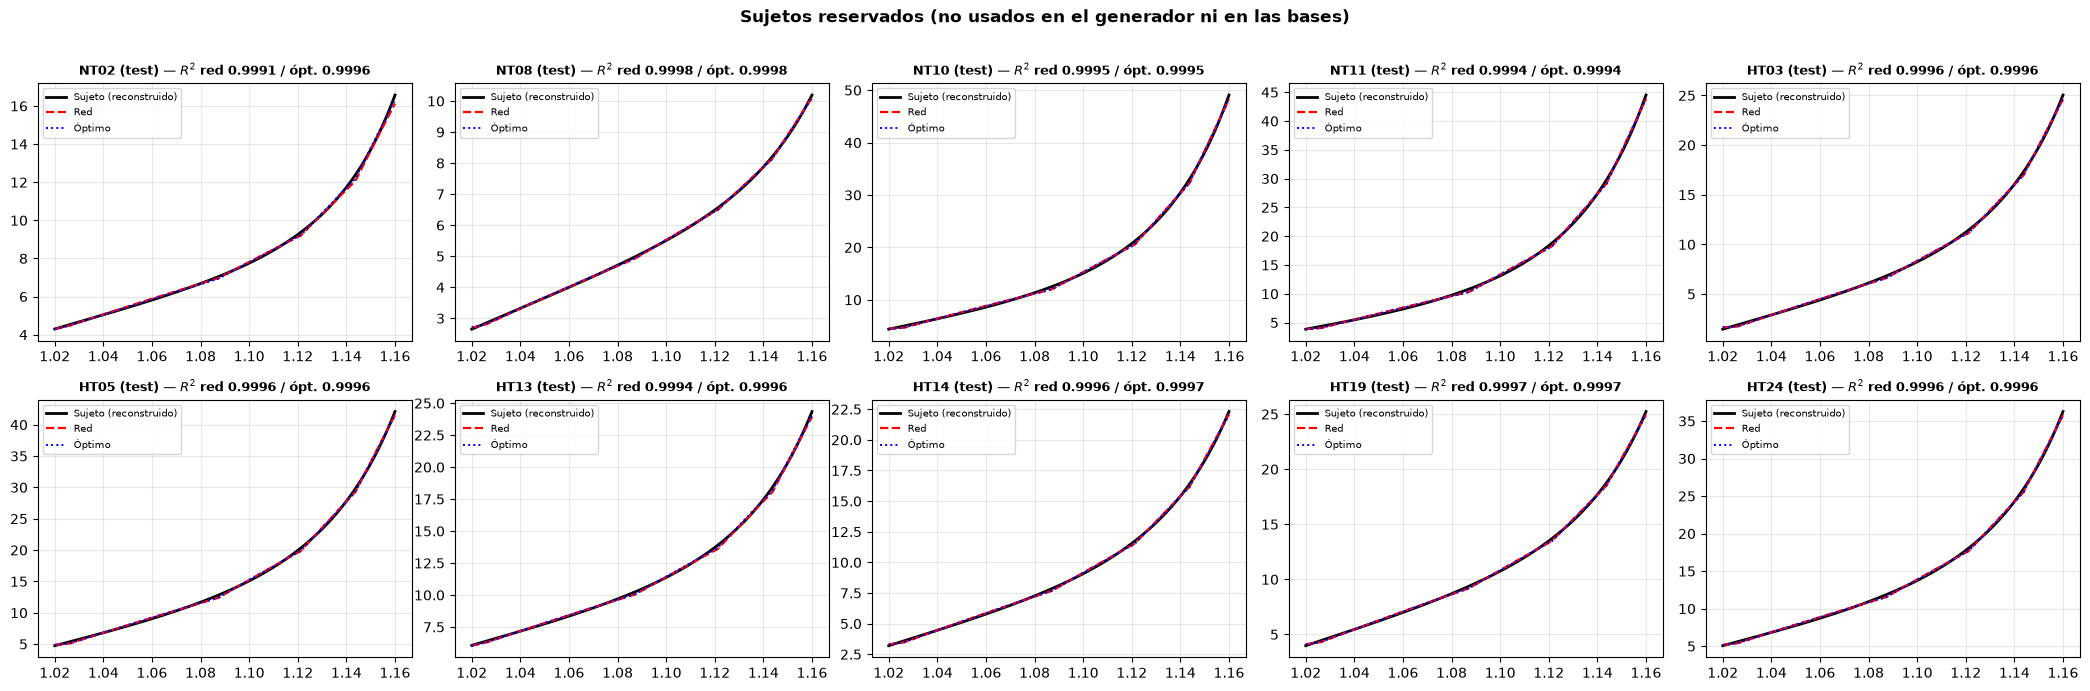

In [16]:
# ==============================================================================
# CÉLULA 11: FIGURAS DE VALIDACIÓN — CURVAS MEDIAS Y SUJETOS RESERVADOS PARA TEST
# ==============================================================================
"""
Figura 1: las 4 curvas medias de P_pared (entrada reconstruida, red y óptimo) con sus residuos; las líneas grises marcan los nudos de las rampas.
Figura 2: los sujetos reservados para test, uno por panel.
"""
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

nudos = PARAMS_BASES["knots"]
dig = None   # V16: las medias digitalizadas del paper son de σθθ, no de P_pared (no se superponen)

fig, axes = plt.subplots(2, 4, figsize=(20, 8.5))
for col, (nombre, r) in enumerate(RES_MEDIAS.items()):
    ax_a, ax_r = axes[0, col], axes[1, col]
    ax_a.plot(X_MESH_999, r["y"], "k-", lw=2.5, label="Media reconstruida")
    if dig is not None and (dig["curva"] == nombre).any():
        d = dig[dig["curva"] == nombre]
        ax_a.plot(d["lambda_theta"], d["sigma_theta_kPa"], color="#f59e0b", lw=5, alpha=0.45,
                  label="Media digitalizada (paper)")
    ax_a.plot(X_MESH_999, r["b_rn"], "r--", lw=2, label=f"Red {VERSION.upper()}")
    ax_a.plot(X_MESH_999, r["b_opt"], "b:", lw=1.6, label="Óptimo lsq_linear")
    ax_a.set_title(f"{nombre}\nNRMSE red {r['m_rn']['NRMSE']:.2f}% (óptimo {r['m_opt']['NRMSE']:.2f}%)",
                   fontsize=10, fontweight="bold")
    ax_a.set_ylabel(ETQ_Y, fontsize=9)
    ax_a.grid(True, alpha=0.3)
    ax_a.legend(fontsize=7, loc="upper left")

    ax_r.plot(X_MESH_999, r["y"] - r["b_rn"], "r-", lw=1.5, label="Residuo red")
    ax_r.plot(X_MESH_999, r["y"] - r["b_opt"], "b--", lw=1.5, label="Residuo óptimo")
    for k in nudos:
        ax_r.axvline(k, color="gray", linestyle="-.", alpha=0.5, lw=1)
    ax_r.axhline(0, color="black", linestyle=":", alpha=0.6)
    ax_r.set_xlabel(ETQ_X, fontsize=9)
    ax_r.set_ylabel("Residuo [kPa]", fontsize=9)
    ax_r.grid(True, alpha=0.3)
    ax_r.legend(fontsize=7)
plt.suptitle(f"Curvas medias de Masson et al. (2011) — red {VERSION.upper()} (líneas grises: nudos)",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(f"validacion_curvas_medias_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# --- Sujetos reservados para test ---------------------------------------------------------------
idx_t = np.where(MASK_POB_TEST)[0]
n_cols = 5
n_rows = int(np.ceil(len(idx_t) / n_cols))
fig2, axes2 = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.4 * n_rows), squeeze=False)
for ax, i in zip(axes2.flatten(), idx_t):
    r = RES_SUJETOS[i]
    ax.plot(X_MESH_999, r["y"], "k-", lw=2, label="Sujeto (reconstruido)")
    ax.plot(X_MESH_999, r["b_rn"], "r--", lw=1.6, label="Red")
    ax.plot(X_MESH_999, r["b_opt"], "b:", lw=1.4, label="Óptimo")
    ax.set_title(f"{r['nombre']} (test) — $R^2$ red {r['m_rn']['R2']:.4f} / ópt. {r['m_opt']['R2']:.4f}",
                 fontsize=9, fontweight="bold")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7, loc="upper left")
for ax in axes2.flatten()[len(idx_t):]:
    ax.axis("off")
plt.suptitle("Sujetos reservados (no usados en el generador ni en las bases)", fontsize=12, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(f"validacion_sujetos_test_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

## Célula 12 — Evaluación en test: coeficientes, brecha red vs. óptimo, peores casos

📊 Evaluando la red V16_FIBRAS en el conjunto de prueba (Test)...

🎯 PRECISIÓN DE COEFICIENTES — TODAS LAS FAMILIAS (n = 6000)
Coef.    |         R² |        MAE |       RMSE |   rango etiqueta
------------------------------------------------------------------
c1       |   0.999954 |   0.004333 |   0.008218 | [ 0.00,  6.00]
c2       |   0.999936 |   0.005487 |   0.010093 | [ 0.00,  6.00]
c3       |   0.999911 |   0.006156 |   0.011594 | [ 0.00,  5.99]
c4       |   0.999884 |   0.006468 |   0.012982 | [ 0.00,  6.00]
c5       |   0.999838 |   0.007826 |   0.015930 | [ 0.00,  5.99]
------------------------------------------------------------------
PROMEDIO |   0.999905 |   0.006054 |   0.011763
🎯 PRECISIÓN DE COEFICIENTES — SOLO FAMILIAS FISIOLÓGICAS (constitutivas + exponencial; dominio objetivo) (n = 3600)
Coef.    |         R² |        MAE |       RMSE |   rango etiqueta
------------------------------------------------------------------
c1       |   0.999902 |   0.003591 |   0.004942 | 

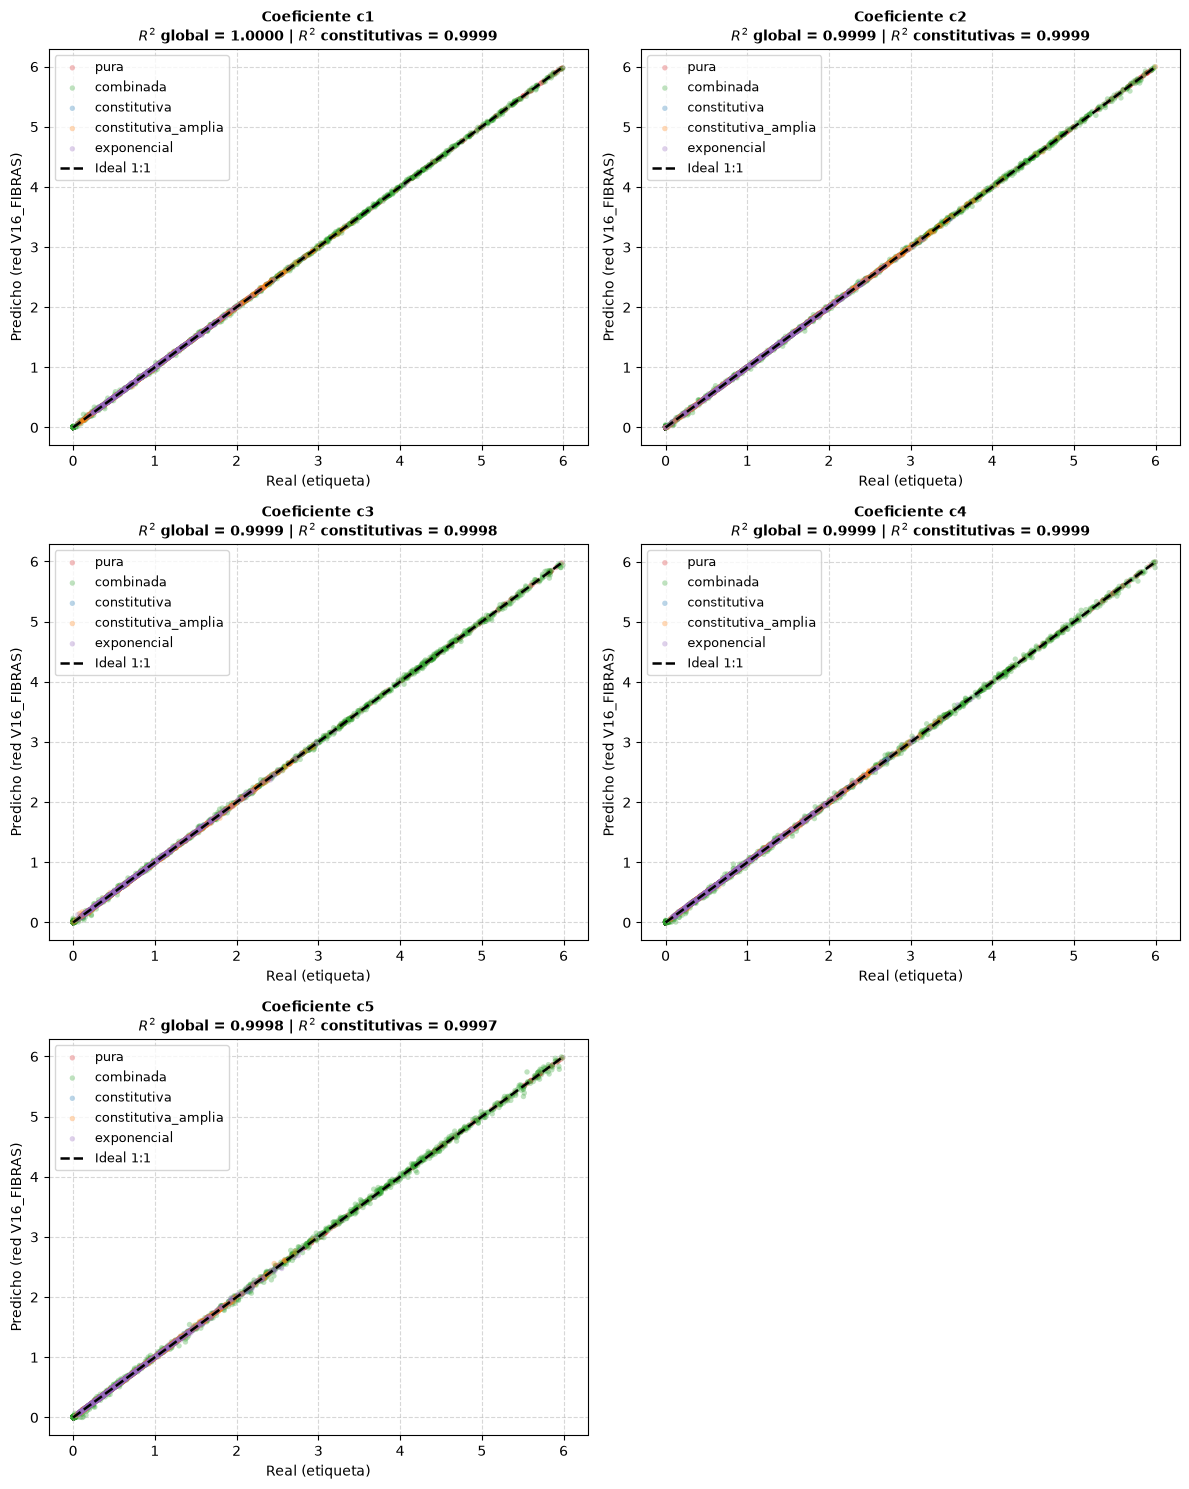

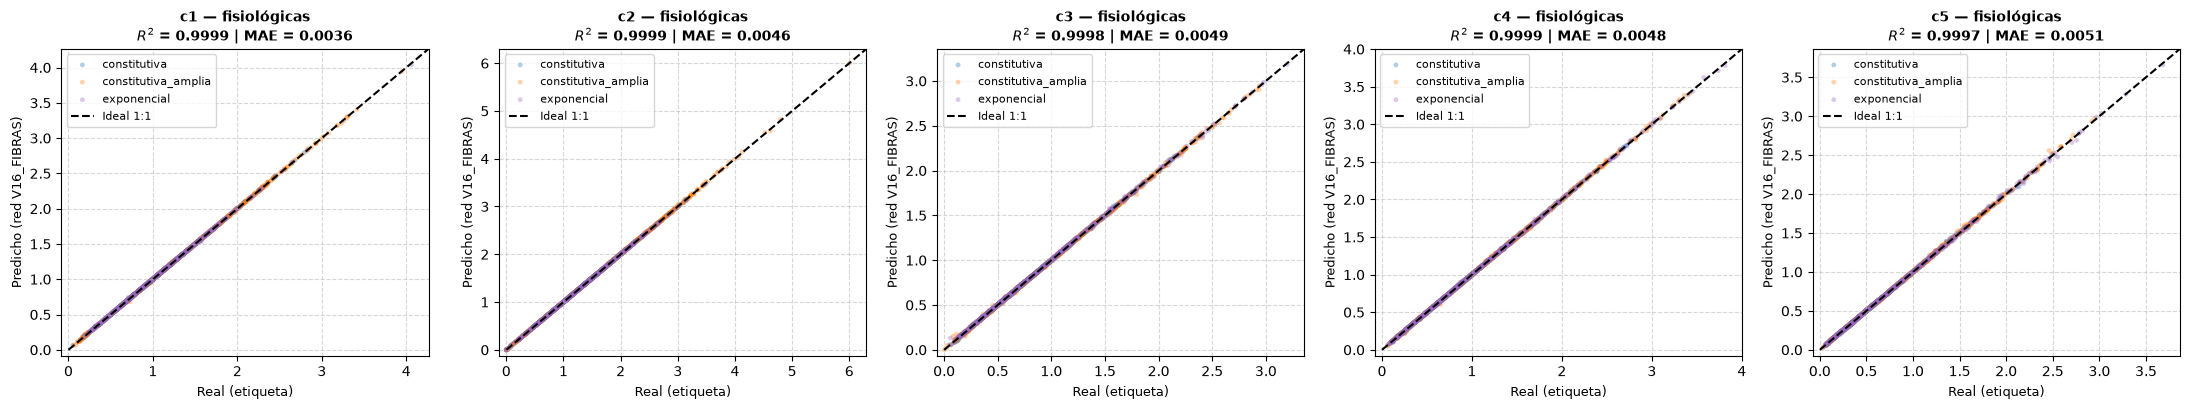

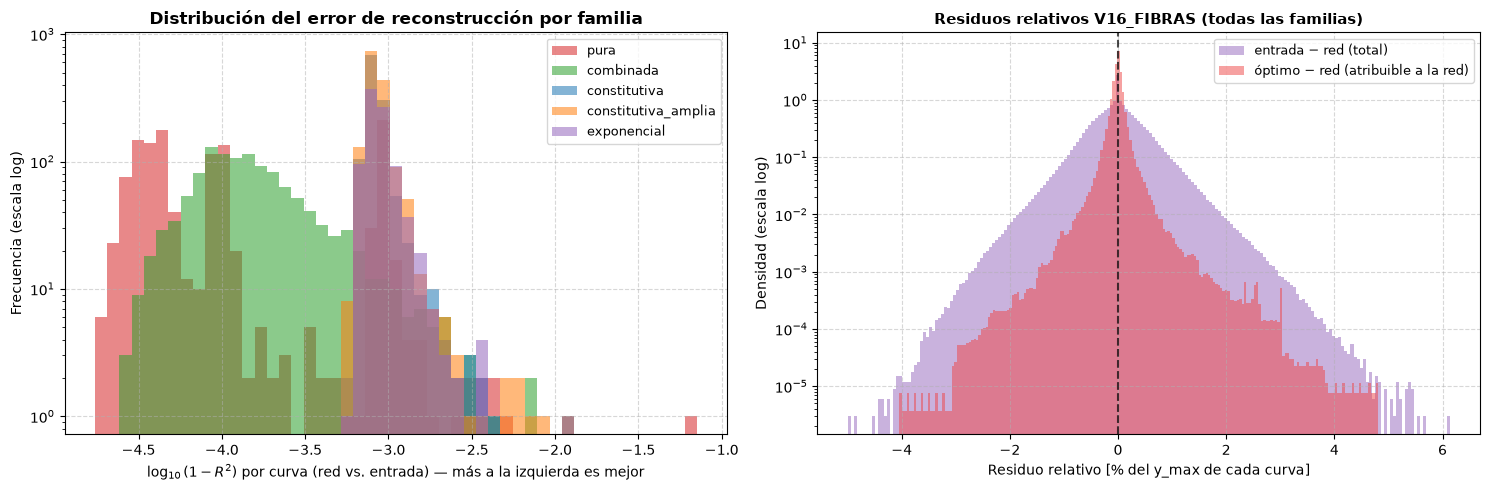


Percentiles de |residuo relativo| [% de y_max] (por punto):
Familia         | tipo         |     p50     p95     p99     máx
pura            | total        |   0.044   0.644   1.010   3.751
pura            | red−óptimo   |   0.013   0.160   0.513   2.982
combinada       | total        |   0.130   0.710   1.246   5.327
combinada       | red−óptimo   |   0.083   0.497   1.056   4.807
constitutiva    | total        |   0.373   1.298   1.944   5.641
constitutiva    | red−óptimo   |   0.038   0.152   0.276   1.516
constitutiva_amplia | total        |   0.377   1.322   1.986   5.337
constitutiva_amplia | red−óptimo   |   0.044   0.196   0.426   1.506
exponencial     | total        |   0.397   1.341   2.027   6.136
exponencial     | red−óptimo   |   0.049   0.234   0.471   2.402


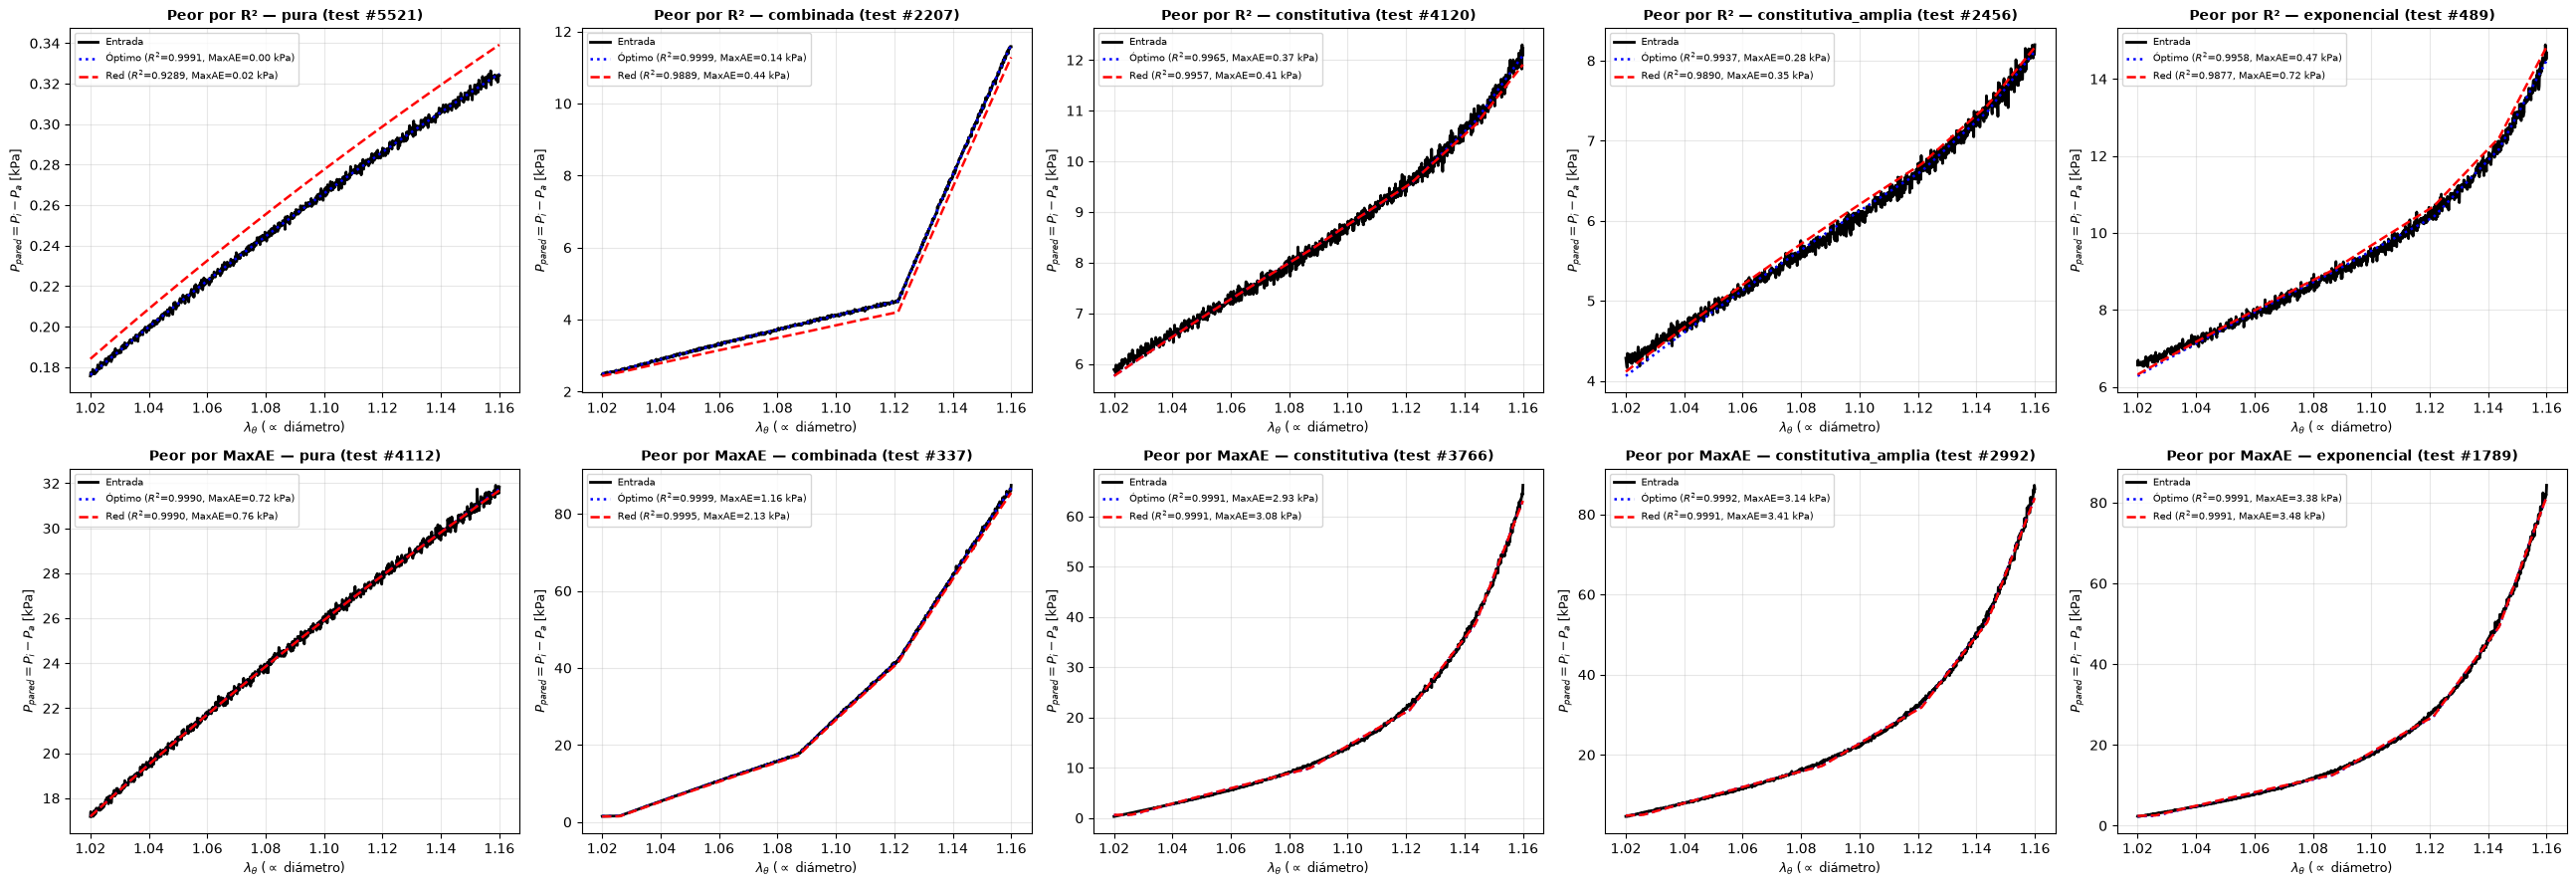

✅ Célula 12 ejecutada correctamente.


In [17]:
# ==============================================================================
# CÉLULA 12: EVALUACIÓN EN TEST — COEFICIENTES, BRECHA RED vs. ÓPTIMO, PEORES CASOS
# ==============================================================================
"""
Todas las métricas de curva comparan contra la curva de ENTRADA (la que ve la red):
  • red     : A·c_red      (coef_rn, proyectado sobre la caja)
  • óptimo  : A·c_lsq      (techo alcanzable con las bases sobre ESA curva)
La brecha red − óptimo es lo atribuible a la red; el óptimo mide el piso de las bases.
NRMSE y MaxAE_rel se calculan por curva con su propio rango (Célula 3).
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print(f"📊 Evaluando la red {VERSION.upper()} en el conjunto de prueba (Test)...\n")

c_rn, c_opt, c_crudo = EVAL["coef_rn"], EVAL["coef_opt"], EVAL["coef_crudo"]
b_in, b_rn, b_lsq = EVAL["b_in"], EVAL["b_rn"], EVAL["b_lsq"]
fam_t = EVAL["fam"]
N_COEFS = c_opt.shape[1]
M_RN = metricas_lote(b_in, b_rn)
M_OPT = metricas_lote(b_in, b_lsq)
m_env = np.isin(fam_t, FAMILIAS_OBJETIVO)      # familias fisiológicas = dominio objetivo


# --- 1. Coeficientes: global y restringido a las familias constitutivas --------------------------
def _tabla_coef(mask, titulo):
    print("=" * 80)
    print(f"🎯 PRECISIÓN DE COEFICIENTES — {titulo} (n = {mask.sum()})")
    print("=" * 80)
    print(f"{'Coef.':<8} | {'R²':>10} | {'MAE':>10} | {'RMSE':>10} | {'rango etiqueta':>16}")
    print("-" * 66)
    out = []
    for i in range(N_COEFS):
        yt, yp = c_opt[mask, i], c_rn[mask, i]
        fila = (r2_score(yt, yp), mean_absolute_error(yt, yp), np.sqrt(mean_squared_error(yt, yp)))
        out.append(fila)
        print(f"c{i+1:<7} | {fila[0]:10.6f} | {fila[1]:10.6f} | {fila[2]:10.6f} | [{yt.min():5.2f}, {yt.max():5.2f}]")
    out = np.array(out)
    print("-" * 66)
    print(f"{'PROMEDIO':<8} | {out[:, 0].mean():10.6f} | {out[:, 1].mean():10.6f} | {out[:, 2].mean():10.6f}")
    return out


COEF_GLOBAL = _tabla_coef(np.ones_like(fam_t, dtype=bool), "TODAS LAS FAMILIAS")
COEF_ENV = _tabla_coef(m_env, "SOLO FAMILIAS FISIOLÓGICAS (constitutivas + exponencial; dominio objetivo)")
print("   (el R² global se infla porque las familias 0 y 1 estiran el rango de las etiquetas a [0, MAX_COEF])")

neg = c_crudo < COEF_MIN
print(f"\n🔒 Predicciones crudas negativas: {neg.mean():.2%} de los coeficientes | "
      f"> MAX_COEF: {(c_crudo > MAX_COEF).mean():.2%} (se proyectan sobre la caja)")

# --- 2. Reconstrucción por familia: red vs. óptimo sobre la misma curva --------------------------
print("\n" + "=" * 118)
print("🧬 RECONSTRUCCIÓN POR FAMILIA (contra la curva de entrada)")
print("=" * 118)
print(f"{'Familia':<15} {'n':>5} | {'R² óptimo':>10} {'R² red':>9} {'med. red':>9} {'mín. red':>9} {'(test #)':>9} | "
      f"{'NRMSE ópt.':>10} {'NRMSE red':>10} {'p95 red':>8} | {'Exceso':>8} | {'MaxAE_rel p95':>13}")
print("-" * 118)
RESUMEN_FAM = []
for f, nombre in FAMILIAS.items():
    m = fam_t == f
    i_peor = int(np.where(m)[0][np.nanargmin(M_RN["R2"][m])])
    i_peor_kpa = int(np.where(m)[0][np.nanargmax(M_RN["MaxAE"][m])])
    exceso = (np.nanmean(M_RN["NRMSE"][m]) / np.nanmean(M_OPT["NRMSE"][m]) - 1.0) * 100.0
    fila = dict(familia=nombre, n=int(m.sum()),
                R2_opt=np.nanmean(M_OPT["R2"][m]), R2_red=np.nanmean(M_RN["R2"][m]),
                R2_red_mediana=np.nanmedian(M_RN["R2"][m]), R2_red_min=np.nanmin(M_RN["R2"][m]),
                R2_opt_en_peor=M_OPT["R2"][i_peor], idx_peor=i_peor, idx_peor_kpa=i_peor_kpa,
                NRMSE_opt=np.nanmean(M_OPT["NRMSE"][m]), NRMSE_red=np.nanmean(M_RN["NRMSE"][m]),
                NRMSE_red_mediana=np.nanmedian(M_RN["NRMSE"][m]), NRMSE_red_p95=np.nanpercentile(M_RN["NRMSE"][m], 95),
                exceso_NRMSE_pct=exceso, MaxAE_rel_p95=np.nanpercentile(M_RN["MaxAE_rel"][m], 95),
                MaxAE_kPa_max=np.nanmax(M_RN["MaxAE"][m]),
                MAE_coef=np.abs(c_opt[m] - c_rn[m]).mean(axis=0))
    RESUMEN_FAM.append(fila)
    print(f"{nombre:<15} {fila['n']:>5} | {fila['R2_opt']:10.5f} {fila['R2_red']:9.5f} {fila['R2_red_mediana']:9.5f} "
          f"{fila['R2_red_min']:9.5f} {i_peor:>9d} | {fila['NRMSE_opt']:9.3f}% {fila['NRMSE_red']:9.3f}% "
          f"{fila['NRMSE_red_p95']:7.3f}% | {exceso:+7.1f}% | {fila['MaxAE_rel_p95']:12.3f}%")
print("-" * 118)
print("Exceso = NRMSE medio de la red / NRMSE medio del óptimo − 1 (lo que pierde la red frente al techo de las bases).")
print("\nMAE de coeficientes por familia:")
for fila in RESUMEN_FAM:
    print(f"   • {fila['familia']:<15}: {np.round(fila['MAE_coef'], 4)} | peor por R²: test #{fila['idx_peor']} "
          f"(R² red {fila['R2_red_min']:.5f} vs. óptimo {fila['R2_opt_en_peor']:.5f}) | peor por MaxAE: "
          f"test #{fila['idx_peor_kpa']} ({fila['MaxAE_kPa_max']:.2f} kPa; óptimo {M_OPT['MaxAE'][fila['idx_peor_kpa']]:.2f} kPa)")
print("   (el peor por R² tiende a ser una curva de poca amplitud; el peor por MaxAE, una de mucha amplitud)")

# --- 3. Persistencia de métricas por curva (para el artículo) ------------------------------------
DF_TEST = pd.DataFrame({"idx_test": np.arange(len(fam_t)), "idx_dataset": EVAL["idx"],
                        "familia": [FAMILIAS[int(f)] for f in fam_t]})
for k in ("R2", "NRMSE", "MaxAE", "MaxAE_rel"):
    DF_TEST[f"{k}_red"], DF_TEST[f"{k}_opt"] = M_RN[k], M_OPT[k]
for i in range(N_COEFS):
    DF_TEST[f"c{i+1}_etiqueta"], DF_TEST[f"c{i+1}_red"], DF_TEST[f"c{i+1}_crudo"] = c_opt[:, i], c_rn[:, i], c_crudo[:, i]
DF_TEST.to_csv(f"metricas_test_por_curva_{VERSION}.csv", index=False)
pd.DataFrame([{k: v for k, v in r.items() if k != "MAE_coef"} for r in RESUMEN_FAM]).to_csv(
    f"resumen_test_por_familia_{VERSION}.csv", index=False)
print(f"\n💾 'metricas_test_por_curva_{VERSION}.csv' y 'resumen_test_por_familia_{VERSION}.csv' guardados.")

# --- Figura 1: regresión 1:1 de coeficientes ------------------------------------------------------
colores = {0: "#d62728", 1: "#2ca02c", 2: "#1f77b4", 3: "#ff7f0e", 4: "#9467bd"}
n_cols = 2
n_rows = int(np.ceil(N_COEFS / n_cols))
fig1, axes1 = plt.subplots(n_rows, n_cols, figsize=(12, 5 * n_rows), squeeze=False)
axes1 = axes1.flatten()
for i in range(N_COEFS):
    ax = axes1[i]
    for f, nombre in FAMILIAS.items():
        m = fam_t == f
        ax.scatter(c_opt[m, i], c_rn[m, i], alpha=0.3, color=colores[f], edgecolors="none", s=15, label=nombre)
    lims = [min(c_opt[:, i].min(), c_rn[:, i].min()), max(c_opt[:, i].max(), c_rn[:, i].max())]
    ax.plot(lims, lims, "k--", label="Ideal 1:1", linewidth=1.8)
    ax.set_title(f"Coeficiente c{i+1}\n$R^2$ global = {COEF_GLOBAL[i, 0]:.4f} | $R^2$ constitutivas = {COEF_ENV[i, 0]:.4f}",
                 fontweight="bold", fontsize=10)
    ax.set_xlabel("Real (etiqueta)", fontsize=10)
    ax.set_ylabel(f"Predicho (red {VERSION.upper()})", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper left", fontsize=9)
for j in range(N_COEFS, len(axes1)):
    axes1[j].axis("off")
plt.tight_layout()
plt.savefig(f"diagnostico_coeficientes_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Figura 1b: regresión 1:1 solo en el dominio objetivo (familias constitutivas) ----------------
fig1b, axes1b = plt.subplots(1, N_COEFS, figsize=(4.4 * N_COEFS, 4.2), squeeze=False)
for i in range(N_COEFS):
    ax = axes1b[0, i]
    for f in FAMILIAS_OBJETIVO:
        m = fam_t == f
        ax.scatter(c_opt[m, i], c_rn[m, i], alpha=0.35, color=colores[f], edgecolors="none", s=12, label=FAMILIAS[f])
    hi = 1.05 * max(c_opt[m_env, i].max(), c_rn[m_env, i].max(), 1e-3)
    ax.plot([0, hi], [0, hi], "k--", linewidth=1.5, label="Ideal 1:1")
    ax.set_xlim(-0.02 * hi, hi)
    ax.set_ylim(-0.02 * hi, hi)
    ax.set_title(f"c{i+1} — fisiológicas\n$R^2$ = {COEF_ENV[i, 0]:.4f} | MAE = {COEF_ENV[i, 1]:.4f}", fontsize=10, fontweight="bold")
    ax.set_xlabel("Real (etiqueta)", fontsize=9)
    ax.set_ylabel(f"Predicho (red {VERSION.upper()})", fontsize=9)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(f"diagnostico_coeficientes_constitutivas_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Figura 2: log10(1 − R²) por familia y residuos relativos ------------------------------------
fig2, (ax_r2, ax_res) = plt.subplots(1, 2, figsize=(15, 5))
log_err = np.log10(np.clip(1.0 - M_RN["R2"], 1e-8, None))
bins = np.linspace(np.nanmin(log_err), np.nanmax(log_err), 50)
for f, nombre in FAMILIAS.items():
    m = fam_t == f
    ax_r2.hist(log_err[m], bins=bins, alpha=0.55, color=colores[f], label=nombre)
ax_r2.set_yscale("log")
ax_r2.set_xlabel(r"$\log_{10}(1 - R^2)$ por curva (red vs. entrada) — más a la izquierda es mejor", fontsize=10)
ax_r2.set_ylabel("Frecuencia (escala log)", fontsize=10)
ax_r2.set_title("Distribución del error de reconstrucción por familia", fontweight="bold")
ax_r2.grid(True, linestyle="--", alpha=0.5)
ax_r2.legend(fontsize=9)

y_max_curva = np.maximum(b_in.max(axis=1, keepdims=True), 1.0)
res_red_rel = ((b_lsq - b_rn) / y_max_curva * 100.0)       # error atribuible a la red (% de y_max)
res_tot_rel = ((b_in - b_rn) / y_max_curva * 100.0)        # error total contra la entrada
for datos, color, etiqueta in [(res_tot_rel, "#9467bd", "entrada − red (total)"),
                               (res_red_rel, "#ef4444", "óptimo − red (atribuible a la red)")]:
    ax_res.hist(datos.flatten(), bins=200, density=True, alpha=0.5, color=color, label=etiqueta)
ax_res.set_yscale("log")
ax_res.axvline(0, color="black", linestyle="--", alpha=0.7)
ax_res.set_xlabel("Residuo relativo [% del y_max de cada curva]", fontsize=10)
ax_res.set_ylabel("Densidad (escala log)", fontsize=10)
ax_res.set_title(f"Residuos relativos {VERSION.upper()} (todas las familias)", fontsize=11, fontweight="bold")
ax_res.legend(fontsize=9)
ax_res.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(f"distribucion_residuos_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nPercentiles de |residuo relativo| [% de y_max] (por punto):")
print(f"{'Familia':<15} | {'tipo':<12} | {'p50':>7} {'p95':>7} {'p99':>7} {'máx':>7}")
for f, nombre in FAMILIAS.items():
    m = fam_t == f
    for tipo, datos in [("total", res_tot_rel), ("red−óptimo", res_red_rel)]:
        q = np.percentile(np.abs(datos[m]), [50, 95, 99, 100])
        print(f"{nombre:<15} | {tipo:<12} | {q[0]:7.3f} {q[1]:7.3f} {q[2]:7.3f} {q[3]:7.3f}")

# --- Figura 3: peor caso de cada familia ------------------------------------------------------------
fig3, axes3 = plt.subplots(2, len(FAMILIAS), figsize=(5.2 * len(FAMILIAS), 9), squeeze=False)
for col, fila in enumerate(RESUMEN_FAM):
    for row, (clave, criterio) in enumerate([("idx_peor", "R²"), ("idx_peor_kpa", "MaxAE")]):
        ax = axes3[row, col]
        s = fila[clave]
        ax.plot(X_MESH_999, b_in[s], "k-", lw=2, label="Entrada")
        ax.plot(X_MESH_999, b_lsq[s], "b:", lw=1.8,
                label=f"Óptimo ($R^2$={M_OPT['R2'][s]:.4f}, MaxAE={M_OPT['MaxAE'][s]:.2f} kPa)")
        ax.plot(X_MESH_999, b_rn[s], "r--", lw=1.8,
                label=f"Red ($R^2$={M_RN['R2'][s]:.4f}, MaxAE={M_RN['MaxAE'][s]:.2f} kPa)")
        ax.set_title(f"Peor por {criterio} — {fila['familia']} (test #{s})", fontsize=10, fontweight="bold")
        ax.set_xlabel(ETQ_X, fontsize=9)
        ax.set_ylabel(ETQ_Y, fontsize=9)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.savefig(f"peores_casos_test_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

print("✅ Célula 12 ejecutada correctamente.")

## Célula 12b — Generalización dentro de la clase (Fung) y control de clase a la entrada

In [18]:
# ==============================================================================
# CÉLULA 12b: GENERALIZACIÓN DENTRO DE LA CLASE (FUNG) Y CONTROL DE CLASE A LA ENTRADA
# ==============================================================================
"""
1) OOD dentro de la clase: curvas J de otra familia funcional, nunca vista en el entrenamiento:
       P(λ) = C + A·(exp(B·(λ − λ_min)) − 1),   A, B, C > 0   (ley exponencial tipo Fung)
   con (A, B, C) = media geométrica ponderada (Dirichlet) de los ajustes de 2–3 sujetos de entrenamiento
   + perturbación log-normal: misma región de la población, otra forma funcional.
   Métrica principal: brecha red − óptimo lsq_linear sobre la misma curva.
2) Control de clase: curvas fuera de la clase (sujetos de test modulados con una oscilación, no
   monótonas o no convexas desde X_INICIO_CONVEXIDAD). es_curva_J debe rechazarlas, y aceptar las curvas Fung con ruido.
   Para una curva rechazada el método devuelve el óptimo lsq_linear (exacto para cualquier entrada).
"""
import numpy as np
from scipy.optimize import curve_fit

N_OOD = 300
RUIDO_OOD = 0.01
rng_ood = np.random.default_rng(SEED_DATASET + 1)
t_ood = X_MESH_999 - X_MIN_DOMINIO


def fung(x, A, B, C):
    return C + A * (np.exp(B * (x - X_MIN_DOMINIO)) - 1.0)


# --- 1. Ajuste Fung a los sujetos de entrenamiento → rango de parámetros ------------------------
P_FUNG = []
for y in POB_Y[MASK_POB_TRAIN]:
    p, _ = curve_fit(fung, X_MESH_999, y, p0=(5.0, 20.0, y[0]), bounds=([1e-6, 1e-3, 0.0], [1e4, 200.0, 1e3]),
                     maxfev=20000)
    P_FUNG.append(p)
P_FUNG = np.array(P_FUNG)
lo_p, hi_p = P_FUNG.min(axis=0), P_FUNG.max(axis=0)
r2_fung = [1 - np.sum((y - fung(X_MESH_999, *p)) ** 2) / np.sum((y - y.mean()) ** 2)
           for y, p in zip(POB_Y[MASK_POB_TRAIN], P_FUNG)]
print(f"📐 Ajuste Fung a {len(P_FUNG)} sujetos de entrenamiento (R² mín. {min(r2_fung):.4f}): "
      f"A ∈ [{lo_p[0]:.2f}, {hi_p[0]:.2f}] kPa | B ∈ [{lo_p[1]:.1f}, {hi_p[1]:.1f}] | C ∈ [{lo_p[2]:.1f}, {hi_p[2]:.1f}] kPa")

SD_LOG_FUNG = 0.10
Y_fung = []
while len(Y_fung) < N_OOD:
    k = rng_ood.integers(2, 4)
    idx = rng_ood.choice(len(P_FUNG), size=k, replace=False)
    logp = rng_ood.dirichlet(np.ones(k)) @ np.log(P_FUNG[idx]) + rng_ood.normal(0.0, SD_LOG_FUNG, size=3)
    y0 = fung(X_MESH_999, *np.exp(logp))
    if y0.min() > 0 and y0.max() <= SIGMA_MAX_KPA:
        Y_fung.append(y0)
Y_fung = np.array(Y_fung)
fuera_banda = np.mean((Y_fung < BANDA_INF - 1e-9) | (Y_fung > BANDA_SUP + 1e-9))
d_fung = np.array([np.min(np.sqrt(np.mean((POB_Y[MASK_POB_TRAIN] - y) ** 2, axis=1))) / y.max() for y in Y_fung])
print(f"   Curvas Fung: puntos fuera de la banda poblacional {fuera_banda:.1%} | distancia relativa al sujeto "
      f"más cercano: mediana {np.median(d_fung):.2%}")
Y_fung_r = np.maximum(Y_fung + rng_ood.normal(0.0, RUIDO_OOD, size=Y_fung.shape) * np.abs(Y_fung), TENSION_MIN_KPA)

c_opt = np.array([lsq_acotado(A_base, y) for y in Y_fung_r])
c_rn = np.clip(sy.inverse_transform(model.predict(sx.transform(safe_log_transform(Y_fung_r)), verbose=0)),
               COEF_MIN, MAX_COEF)
M_rn, M_opt = metricas_lote(Y_fung_r, c_rn @ A_base.T), metricas_lote(Y_fung_r, c_opt @ A_base.T)
exc = (np.nanmean(M_rn["NRMSE"]) / np.nanmean(M_opt["NRMSE"]) - 1) * 100
i_p = int(np.nanargmin(M_rn["R2"]))
RES_OOD = dict(M_rn=M_rn, M_opt=M_opt, exceso_NRMSE_pct=exc)
print("\n🧪 OOD dentro de la clase (ley tipo Fung, con ruido 1 %)")
print(f"   R² red {np.nanmean(M_rn['R2']):.5f} | óptimo {np.nanmean(M_opt['R2']):.5f} | "
      f"NRMSE red {np.nanmean(M_rn['NRMSE']):.3f}% | óptimo {np.nanmean(M_opt['NRMSE']):.3f}% | exceso {exc:+.1f}%")
print(f"   Peor caso: R² red {M_rn['R2'][i_p]:.5f} (óptimo en esa curva {M_opt['R2'][i_p]:.5f}) | "
      f"p95 NRMSE red {np.nanpercentile(M_rn['NRMSE'], 95):.3f}%")
_c_crudo_ood = sy.inverse_transform(model.predict(sx.transform(safe_log_transform(Y_fung_r)), verbose=0))
_pul_ood = [pulir(A_base, y, c)[1] for y, c in zip(Y_fung_r, _c_crudo_ood)]
print(f"   Red + pulido: conjunto activo exacto en {np.mean(_pul_ood):.1%} de las curvas Fung (resultado = óptimo exacto)")

# --- 2. Control de clase -------------------------------------------------------------------------
Y_fuera = []
for y in POB_Y[MASK_POB_TEST]:
    for _ in range(max(1, N_OOD // (4 * MASK_POB_TEST.sum()))):
        f = rng_ood.uniform(1.0, 3.0)
        amp = rng_ood.uniform(0.10, 0.30)
        mod = 1.0 + amp * np.sin(2 * np.pi * f * t_ood / t_ood[-1] + rng_ood.uniform(0, 2 * np.pi))
        Y_fuera.append(y * mod)
Y_fuera = np.array(Y_fuera)
Y_fuera_r = np.maximum(Y_fuera + rng_ood.normal(0.0, RUIDO_OOD, size=Y_fuera.shape) * np.abs(Y_fuera), TENSION_MIN_KPA)
fuera_de_clase = np.array([not all(diagnostico_forma(y)) for y in Y_fuera])      # verdad (curva limpia)

dist_fung = np.array([distancia_a_clase_J(y) for y in Y_fung_r])
dist_fuera = np.array([distancia_a_clase_J(y) for y in Y_fuera_r])
dist_suj = np.array([distancia_a_clase_J(y) for y in POB_Y])
acept_fung, acept_fuera, acept_suj = (dist_fung <= TOL_CLASE_NRMSE, dist_fuera <= TOL_CLASE_NRMSE,
                                      dist_suj <= TOL_CLASE_NRMSE)
print(f"\n🛂 Control de clase es_curva_J (tolerancia {TOL_CLASE_NRMSE}%; distancias mediana [máx])")
print(f"   distancias: Fung con ruido {np.median(dist_fung):.2f}% [{dist_fung.max():.2f}%] | sujetos "
      f"{np.median(dist_suj):.2f}% [{dist_suj.max():.2f}%] | moduladas fuera de clase "
      f"{np.median(dist_fuera[fuera_de_clase]):.2f}% [mín. {dist_fuera[fuera_de_clase].min():.2f}%]")
print(f"   • Curvas Fung (en clase)           : aceptadas {acept_fung.mean():.1%}")
print(f"   • Sujetos reales (en clase)        : aceptados {acept_suj.mean():.1%}")
print(f"   • Moduladas fuera de la clase (n={fuera_de_clase.sum()}): rechazadas {(~acept_fuera[fuera_de_clase]).mean():.1%}")
if (~fuera_de_clase).any():
    print(f"   • Moduladas que siguieron siendo J (n={(~fuera_de_clase).sum()}): aceptadas {acept_fuera[~fuera_de_clase].mean():.1%}")
print("   Para una curva rechazada, la salida del método es el óptimo lsq_linear (exacto) en lugar de la red.")

📐 Ajuste Fung a 31 sujetos de entrenamiento (R² mín. 0.9947): A ∈ [0.92, 5.54] kPa | B ∈ [7.2, 25.4] | C ∈ [1.2, 8.4] kPa
   Curvas Fung: puntos fuera de la banda poblacional 2.4% | distancia relativa al sujeto más cercano: mediana 3.19%

🧪 OOD dentro de la clase (ley tipo Fung, con ruido 1 %)
   R² red 0.99846 | óptimo 0.99873 | NRMSE red 1.055% | óptimo 0.965% | exceso +9.3%
   Peor caso: R² red 0.99366 (óptimo en esa curva 0.99605) | p95 NRMSE red 1.418%
   Red + pulido: conjunto activo exacto en 99.3% de las curvas Fung (resultado = óptimo exacto)

🛂 Control de clase es_curva_J (tolerancia 2.0%; distancias mediana [máx])
   distancias: Fung con ruido 0.54% [1.34%] | sujetos 0.06% [0.08%] | moduladas fuera de clase 4.40% [mín. 1.31%]
   • Curvas Fung (en clase)           : aceptadas 100.0%
   • Sujetos reales (en clase)        : aceptados 100.0%
   • Moduladas fuera de la clase (n=47): rechazadas 91.5%
   • Moduladas que siguieron siendo J (n=23): aceptadas 82.6%
   Para una curva r

## Célula 13 — Reconstrucción de muestras aleatorias (escala por panel)

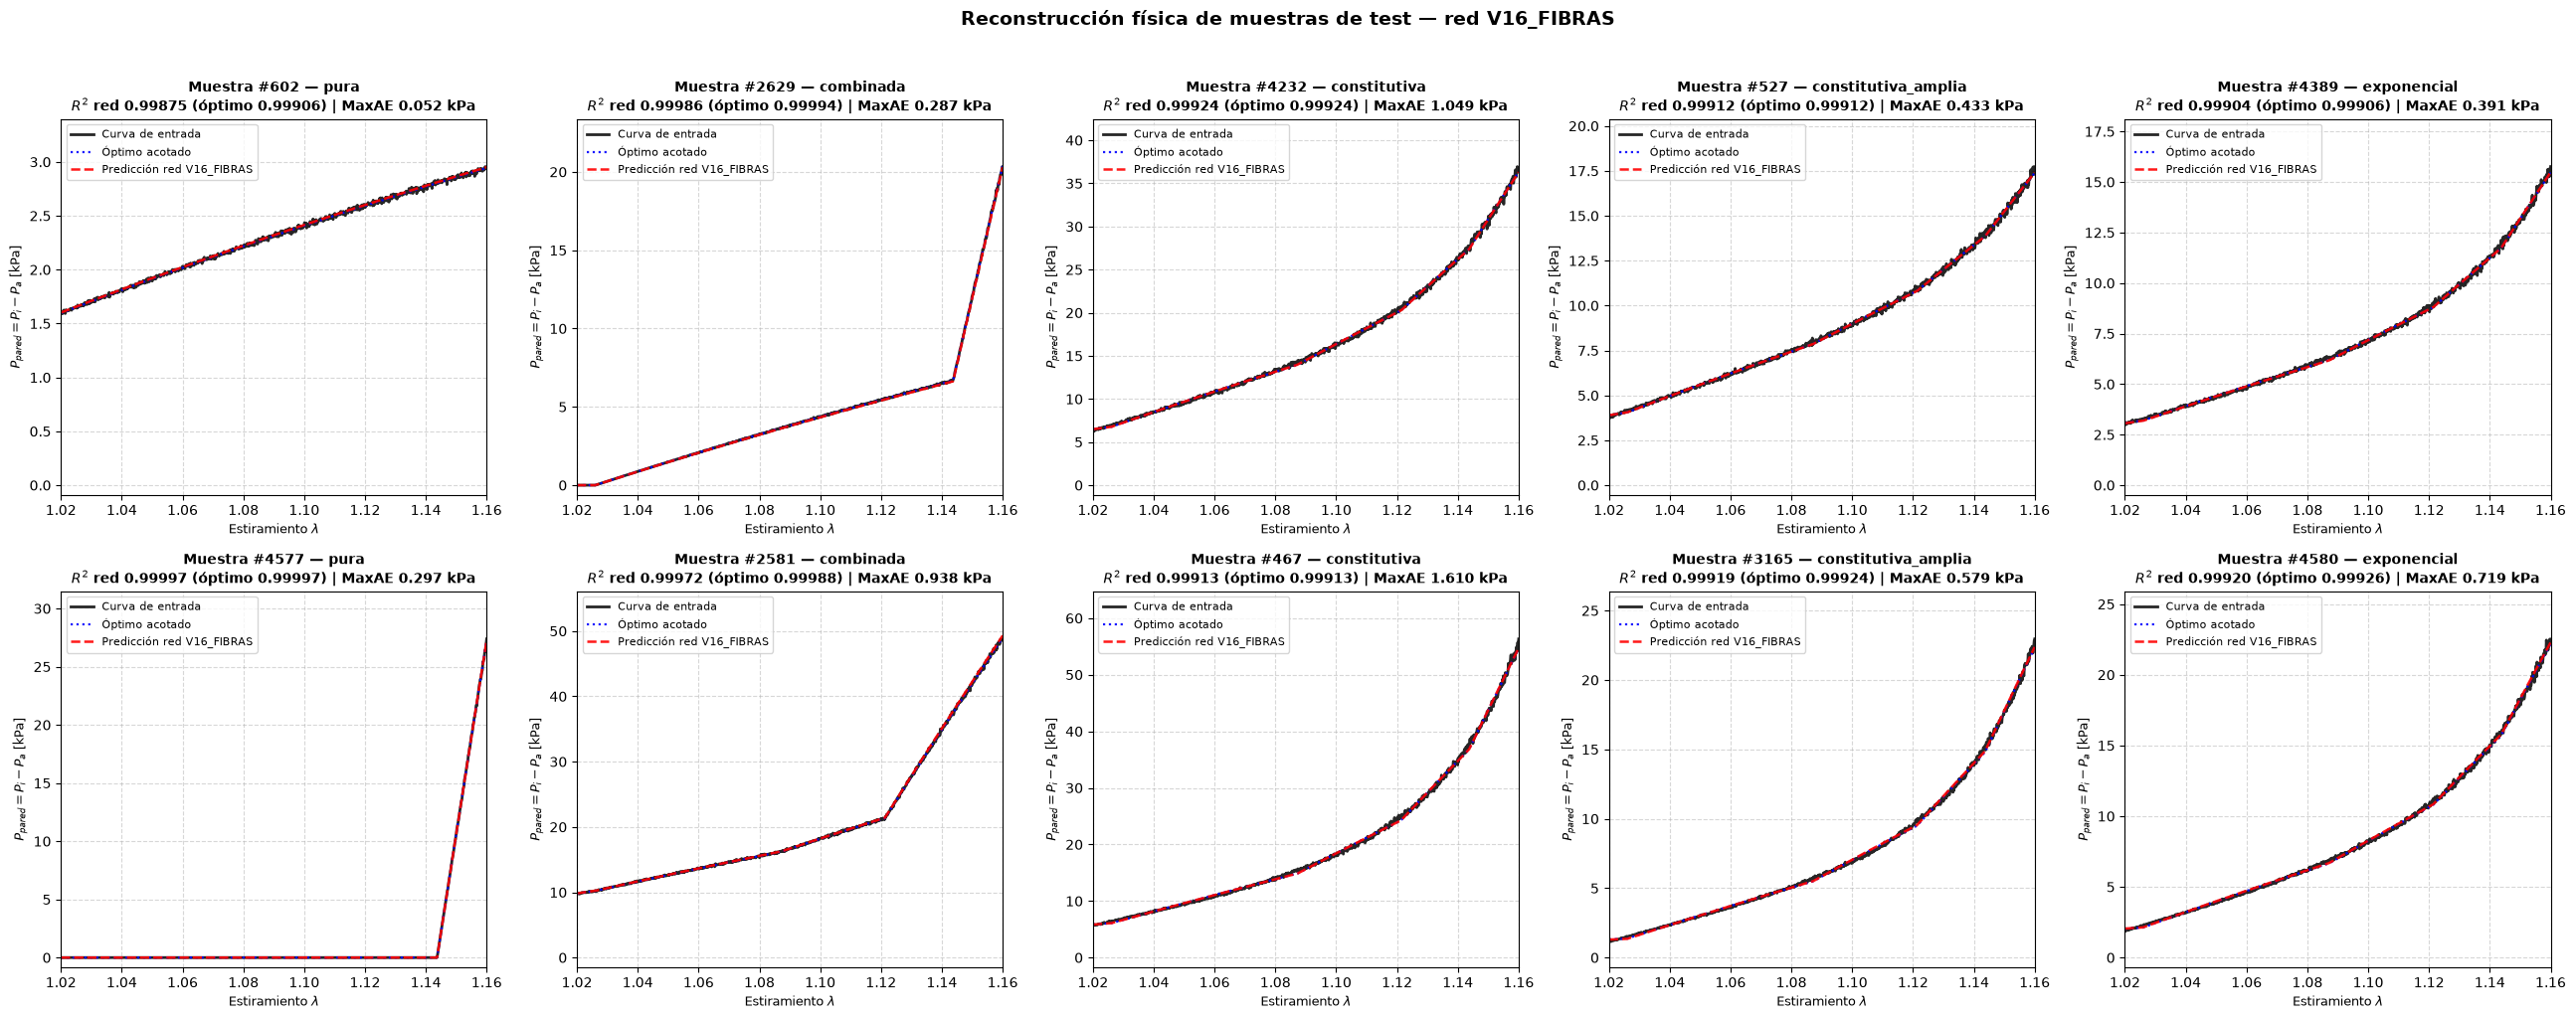

✅ Célula 13 ejecutada. Ventana: λ ∈ [1.02, 1.16] | escala vertical por panel.


In [19]:
# ==============================================================================
# CÉLULA 13: RECONSTRUCCIÓN FÍSICA DE MUESTRAS ALEATORIAS (2 POR FAMILIA)
# ==============================================================================
"""
Escala vertical por panel.
Los peores casos de cada familia están en la Figura 3 de la Célula 12.
"""
import numpy as np
import matplotlib.pyplot as plt

rng_plot = np.random.default_rng(SEED)
indices_muestras = []
for f in sorted(FAMILIAS):
    cand = np.where(EVAL["fam"] == f)[0]
    indices_muestras += [int(i) for i in rng_plot.choice(cand, size=min(2, len(cand)), replace=False)]

n_cols = len(FAMILIAS)
fig, axes = plt.subplots(2, n_cols, figsize=(5.2 * n_cols, 10), squeeze=False)
indices_muestras = [indices_muestras[2 * j + r] for r in range(2) for j in range(n_cols)]   # fila = muestra, columna = familia
for ax, s in zip(axes.flatten(), indices_muestras):
    b_in, b_pred, b_lsq = EVAL["b_in"][s], EVAL["b_rn"][s], EVAL["b_lsq"][s]
    m_rn, m_lsq = metricas_curva(b_in, b_pred), metricas_curva(b_in, b_lsq)
    ax.plot(X_MESH_999, b_in, "k-", linewidth=2.0, label="Curva de entrada", alpha=0.85)
    ax.plot(X_MESH_999, b_lsq, "b:", linewidth=1.6, label="Óptimo acotado", alpha=0.9)
    ax.plot(X_MESH_999, b_pred, "r--", linewidth=1.8, label=f"Predicción red {VERSION.upper()}", alpha=0.9)
    ax.set_title(f"Muestra #{s} — {FAMILIAS[int(EVAL['fam'][s])]}\n"
                 f"$R^2$ red {m_rn['R2']:.5f} (óptimo {m_lsq['R2']:.5f}) | MaxAE {m_rn['MaxAE']:.3f} kPa",
                 fontweight="bold", fontsize=10)
    ax.set_xlabel(r"Estiramiento $\lambda$", fontsize=9)
    ax.set_ylabel(ETQ_Y, fontsize=9)
    ax.set_xlim(X_MIN_DOMINIO, X_MAX_DOMINIO)
    ax.set_ylim(-0.03 * max(b_in.max(), 1.0), 1.15 * max(b_in.max(), 1.0))
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper left", fontsize=8)

plt.suptitle(f"Reconstrucción física de muestras de test — red {VERSION.upper()}",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"reconstruccion_ejemplos_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"✅ Célula 13 ejecutada. Ventana: λ ∈ [{X_MIN_DOMINIO}, {X_MAX_DOMINIO}] | escala vertical por panel.")

## Célula 14 — Diseñador de injerto: curva presión–diámetro → cantidad de cada capa (red + pulido = óptimo exacto)

📂 Cargando base funcional (malla unificada)...
   • Malla: 999 puntos en [1.020, 1.160] | Bases: 5
✅ Sistema cargado (v16_fibras) | OFFSET_LOG = 5.0000
🫀 Curva de Masson et al.: Mean HT (media reconstruida)
   Control de clase (curva realizable con telas): ✅ dentro

🎯 COEFICIENTES (N_BASES = 5)
Coef. | Óptimo acotado (lsq)   | Red (proyectado)   | Red (crudo)  | Diferencia
------------------------------------------------------------------------------------
c1    | 1.123480               | 1.124847           | 1.124847     | -0.001366 
c2    | 1.449181               | 1.451979           | 1.451979     | -0.002798 
c3    | 0.951544               | 0.949915           | 0.949915     | 0.001629  
c4    | 1.035145               | 1.036450           | 1.036450     | -0.001305 
c5    | 0.751314               | 0.749403           | 0.749403     | 0.001911  

📊 MÉTRICAS EN [1.02, 1.16]
Métrica      | Óptimo acotado (lsq)   | Red V16_FIBRAS
--------------------------------------------------------

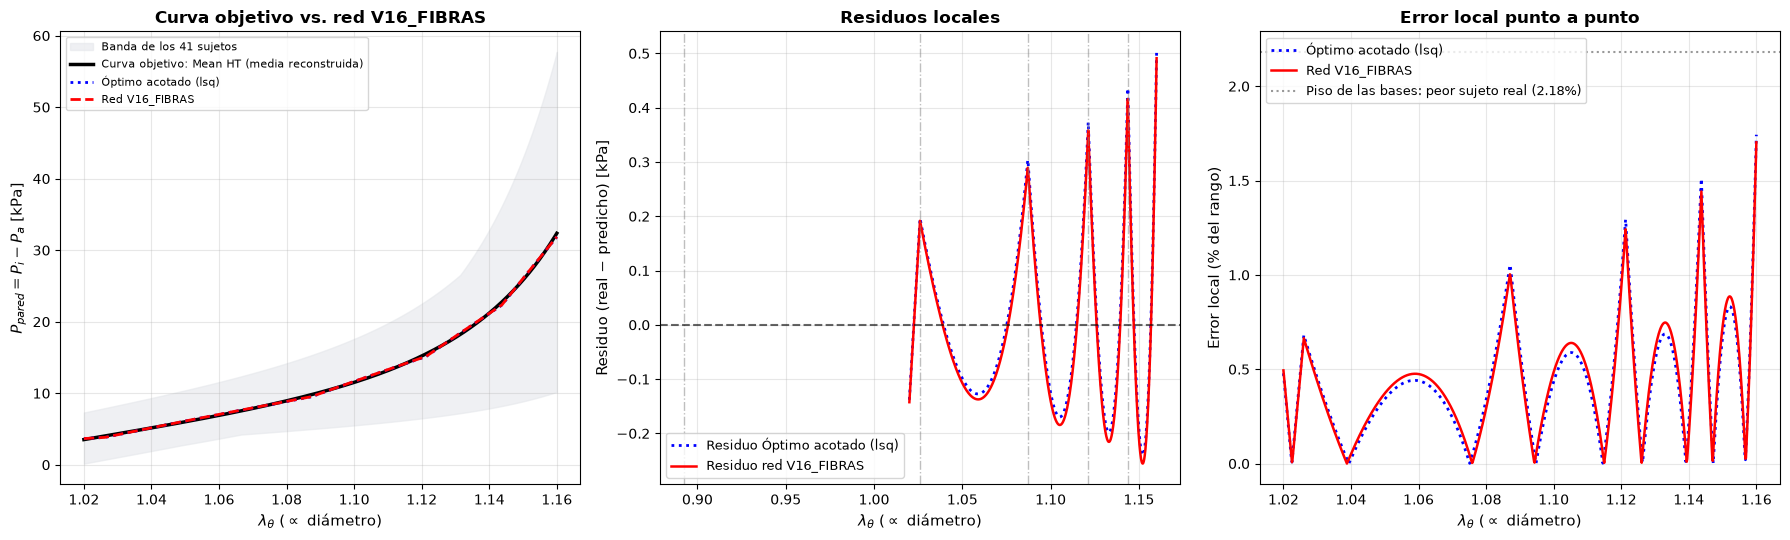

In [20]:
# ==============================================================================
# CÉLULA 14: EVALUADOR / DISEÑADOR DE INJERTO (curva presión–diámetro → cantidad de cada capa)
# ==============================================================================
"""
Requiere las Células G, M y 3, y el modelo guardado (Célula 8). Usa los MISMOS archivos, MAX_COEF y
OFFSET_LOG que el entrenamiento. No hace relleno ni recorte silencioso de features: si hay
incompatibilidad, falla.

Modos de entrada:
  'masson' : un sujeto reconstruido de Masson et al. (SUJETO_EVAL, p. ej. "HT07") o una curva media
             ("Mean Young", "Mean Old", "Mean NT", "Mean HT").
  'excel'  : columnas (λθ, P_pared [kPa]) en ARCHIVO_EXCEL_CURVA_J (P en kPa; 1 mmHg = 0,1333 kPa).
  'puntos' : lista PUNTOS_USUARIO interpolada (lineal o PCHIP).
Resultado: el método devuelve SIEMPRE el óptimo acotado exacto.
  • Curva dentro de la clase J: red → pulido (conjunto activo de la red + mínimos cuadrados + KKT). Si la red
    identificó bien el conjunto activo, el pulido da el óptimo exacto sin correr bvls completo.
  • Curva fuera de la clase, o pulido que no verifica KKT: bvls completo.
La red sola (sin pulido) se muestra como comparación. Al final, tabla de diseño del injerto (capa, enganche, cantidad).
"""
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from tensorflow.keras.models import load_model

for _req in ("POB", "MEDIAS_RECONSTRUIDAS", "safe_log_transform", "metricas_curva", "lsq_acotado", "es_curva_J"):
    if _req not in globals():
        raise RuntimeError(f"Falta '{_req}': ejecutá primero las Células G, M y 3.")

# ── 1. CONFIGURACIÓN DEL EVALUADOR ────────────────────────────────────────────────────────────
MODO_ENTRADA = "masson"               # 'masson', 'excel' o 'puntos'
SUJETO_EVAL = "Mean HT"               # id de sujeto ("NT03", "HT12", ...) o nombre de curva media
ARCHIVO_EXCEL_CURVA_J = "Curva_J.xlsx"
TIPO_INTERPOLACION_PUNTOS = "pchip"   # 'lineal' o 'pchip'
COL_OPT = "Óptimo acotado (lsq)"

PUNTOS_USUARIO = [(1.02, 2.0), (1.06, 7.0), (1.10, 13.0), (1.13, 21.0), (1.16, 38.0)]   # (λθ, P_pared [kPa])


# ── 2. CARGA DE ARCHIVOS ──────────────────────────────────────────────────────────────────────
def cargar_archivos_sistema():
    print("📂 Cargando base funcional (malla unificada)...")
    if not os.path.exists(ARCHIVO_BASES):
        raise FileNotFoundError(f"No se encontró '{ARCHIVO_BASES}'.")
    df_base = pd.read_excel(ARCHIVO_BASES, header=None)
    x_base = df_base.iloc[:, 0].values.astype(np.float64)
    A_base_ev = df_base.iloc[:, 1:].values.astype(np.float64)
    print(f"   • Malla: {len(x_base)} puntos en [{x_base[0]:.3f}, {x_base[-1]:.3f}] | Bases: {A_base_ev.shape[1]}")
    for f in (ARCHIVO_MODELO, ARCHIVO_SCALERS):
        if not os.path.exists(f):
            raise FileNotFoundError(f"No se encontró '{f}'. Ejecutá la Célula 8 (guarda ambos archivos).")
    modelo = load_model(ARCHIVO_MODELO, compile=False)
    with open(ARCHIVO_SCALERS, "rb") as f:
        meta = pickle.load(f)
    sx_l, sy_l, offset_l = meta["scaler_x"], meta["scaler_y"], meta["offset_log"]
    if modelo.input_shape[-1] != len(x_base) or sx_l.n_features_in_ != len(x_base):
        raise ValueError(f"Incompatibilidad: modelo espera {modelo.input_shape[-1]} features, "
                         f"escalador {sx_l.n_features_in_}, malla de bases {len(x_base)}.")
    if modelo.output_shape[-1] != A_base_ev.shape[1]:
        raise ValueError(f"Incompatibilidad: el modelo predice {modelo.output_shape[-1]} coeficientes "
                         f"y las bases son {A_base_ev.shape[1]}.")
    print(f"✅ Sistema cargado ({meta.get('version', '?')}) | OFFSET_LOG = {offset_l:.4f}")
    return x_base, A_base_ev, modelo, sx_l, sy_l, offset_l


def predecir_coeficientes(modelo, sx_l, sy_l, offset_l, Y):
    """Coeficientes de la red (crudos y proyectados sobre la caja) para una o varias curvas."""
    Y = np.atleast_2d(Y)
    crudo = sy_l.inverse_transform(modelo.predict(sx_l.transform(safe_log_transform(Y, offset=offset_l)), verbose=0))
    return crudo, np.clip(crudo, COEF_MIN, MAX_COEF)


# ── 3. CURVA OBJETIVO ──────────────────────────────────────────────────────────────────────────
def generar_curva_objetivo(x_base):
    puntos_ctrl = None
    if MODO_ENTRADA == "masson":
        if SUJETO_EVAL in MEDIAS_RECONSTRUIDAS:
            y = np.interp(x_base, X_MESH_999, MEDIAS_RECONSTRUIDAS[SUJETO_EVAL])
            etiqueta = f"{SUJETO_EVAL} (media reconstruida)"
        else:
            fila = POB[POB["id"] == SUJETO_EVAL]
            if fila.empty:
                raise ValueError(f"SUJETO_EVAL '{SUJETO_EVAL}' no existe. Opciones: {list(POB['id'])} o "
                                 f"{list(MEDIAS_RECONSTRUIDAS)}")
            y = curva_objetivo(x_base, fila.iloc[0])
            etiqueta = f"{SUJETO_EVAL} ({'test' if bool(fila.iloc[0]['test']) else 'entrenamiento'})"
        print(f"🫀 Curva de Masson et al.: {etiqueta}")
        return y, puntos_ctrl, etiqueta
    if MODO_ENTRADA == "excel":
        print(f"📖 Cargando curva desde '{ARCHIVO_EXCEL_CURVA_J}'...")
        if not os.path.exists(ARCHIVO_EXCEL_CURVA_J):
            raise FileNotFoundError(f"No se encontró '{ARCHIVO_EXCEL_CURVA_J}'.")
        d = pd.read_excel(ARCHIVO_EXCEL_CURVA_J, header=None)
        x_u, y_u = d.iloc[:, 0].to_numpy(float), d.iloc[:, 1].to_numpy(float)
        etiqueta = ARCHIVO_EXCEL_CURVA_J
    else:
        print(f"✏️ Generando curva desde puntos manuales ({TIPO_INTERPOLACION_PUNTOS})...")
        pts = sorted(PUNTOS_USUARIO, key=lambda p: p[0])
        x_u, y_u = np.array([p[0] for p in pts], float), np.array([p[1] for p in pts], float)
        etiqueta = "puntos manuales"
    orden = np.argsort(x_u)
    x_u, y_u = x_u[orden], y_u[orden]
    if TIPO_INTERPOLACION_PUNTOS == "pchip" and MODO_ENTRADA == "puntos":
        y = PchipInterpolator(x_u, y_u)(x_base)
    else:
        y = np.interp(x_base, x_u, y_u, left=y_u[0], right=y_u[-1])
    if x_u.min() > x_base.min() + 1e-9 or x_u.max() < x_base.max() - 1e-9:
        print(f"⚠️ La curva cubre λ ∈ [{x_u.min():.3f}, {x_u.max():.3f}] y el dominio es "
              f"[{x_base.min():.3f}, {x_base.max():.3f}]: los extremos se completan con el valor del borde.")
    puntos_ctrl = list(zip(x_u, y_u))
    return y, puntos_ctrl, etiqueta


# ── 4. GRÁFICOS ────────────────────────────────────────────────────────────────────────────────
def graficar_resultados(x, b_real, b_rn, b_opt, pts_ctrl, etiqueta):
    rango_y = b_real.max() - b_real.min()
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    axes[0].fill_between(x, envolvente_inferior(x), envolvente_superior(x), color="#e5e7eb", alpha=0.6,
                         label="Banda de los 41 sujetos")
    axes[0].plot(x, b_real, "k-", linewidth=2.5, label=f"Curva objetivo: {etiqueta}")
    axes[0].plot(x, b_opt, "b:", linewidth=2.0, label=COL_OPT)
    axes[0].plot(x, b_rn, "r--", linewidth=2.0, label=f"Red {VERSION.upper()}")
    pts = [p for p in (pts_ctrl or []) if x.min() <= p[0] <= x.max()]
    if pts and len(pts) <= 60:
        px, py = zip(*pts)
        axes[0].scatter(px, py, color="black", zorder=5, s=25, label="Puntos de control")
    axes[0].set_xlabel(ETQ_X, fontsize=11)
    axes[0].set_ylabel(ETQ_Y, fontsize=11)
    axes[0].set_title(f"Curva objetivo vs. red {VERSION.upper()}", fontsize=12, fontweight="bold")
    axes[0].legend(fontsize=8, loc="upper left")
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(x, b_real - b_opt, "b:", linewidth=2.0, label=f"Residuo {COL_OPT}")
    axes[1].plot(x, b_real - b_rn, "r-", linewidth=1.8, label=f"Residuo red {VERSION.upper()}")
    for k in PARAMS_BASES.get("knots", []) if "PARAMS_BASES" in globals() else []:
        axes[1].axvline(k, color="gray", linestyle="-.", alpha=0.5, lw=1)
    axes[1].axhline(0, color="black", linestyle="--", alpha=0.6)
    axes[1].set_xlabel(ETQ_X, fontsize=11)
    axes[1].set_ylabel("Residuo (real − predicho) [kPa]", fontsize=11)
    axes[1].set_title("Residuos locales", fontsize=12, fontweight="bold")
    axes[1].legend(fontsize=9, loc="lower left")
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(x, np.abs(b_real - b_opt) / rango_y * 100.0, "b:", linewidth=2.0, label=COL_OPT)
    axes[2].plot(x, np.abs(b_real - b_rn) / rango_y * 100.0, "r-", linewidth=1.8, label=f"Red {VERSION.upper()}")
    if "PISO_MAXAE_REL_MAX" in globals():
        axes[2].axhline(PISO_MAXAE_REL_MAX, color="gray", linestyle=":", alpha=0.8,
                        label=f"Piso de las bases: peor sujeto real ({PISO_MAXAE_REL_MAX:.2f}%)")
    axes[2].set_xlabel(ETQ_X, fontsize=11)
    axes[2].set_ylabel("Error local (% del rango)", fontsize=11)
    axes[2].set_title("Error local punto a punto", fontsize=12, fontweight="bold")
    axes[2].legend(fontsize=9, loc="upper left")
    axes[2].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"evaluacion_inferencia_curva_j_{VERSION}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


# ── 5. PIPELINE ─────────────────────────────────────────────────────────────────────────────────
def ejecutar_pipeline_evaluacion():
    x_base, A_ev, modelo, sx_l, sy_l, offset_l = cargar_archivos_sistema()
    y_t, pts_ctrl, etiqueta = generar_curva_objetivo(x_base)

    en_clase = es_curva_J(y_t, x_base)
    debajo, encima = y_t < envolvente_inferior(x_base) - 1e-9, y_t > envolvente_superior(x_base) + 1e-9
    print(f"   Control de clase (curva realizable con telas): {'✅ dentro' if en_clase else '⛔ FUERA'}")
    if debajo.any() or encima.any():
        print(f"   Fuera de la banda de los 41 sujetos en {np.mean(debajo | encima):.1%} de los puntos "
              f"(extrapolación respecto de la población, aunque la curva sea J).")

    c_opt = lsq_acotado(A_ev, y_t)
    c_mco = np.linalg.lstsq(A_ev, y_t, rcond=None)[0]          # mínimos cuadrados ordinarios (sin cotas)
    mco_fab = bool(np.all(c_mco >= COEF_MIN - 1e-9) and np.all(c_mco <= MAX_COEF + 1e-9))
    c_crudo, c_rn = predecir_coeficientes(modelo, sx_l, sy_l, offset_l, y_t)
    c_crudo, c_rn = c_crudo[0], c_rn[0]
    y_opt, y_rn = A_ev @ c_opt, A_ev @ c_rn

    print("\n" + "=" * 84)
    print(f"🎯 COEFICIENTES (N_BASES = {A_ev.shape[1]})")
    print("=" * 84)
    print(f"Coef. | {COL_OPT:<22} | {'Red (proyectado)':<18} | {'Red (crudo)':<12} | {'Diferencia':<10}")
    print("-" * 84)
    for m in range(A_ev.shape[1]):
        print(f"c{m+1:<4} | {c_opt[m]:<22.6f} | {c_rn[m]:<18.6f} | {c_crudo[m]:<12.6f} | {c_opt[m] - c_rn[m]:<10.6f}")

    m_opt, m_rn = metricas_curva(y_t, y_opt), metricas_curva(y_t, y_rn)
    print("\n" + "=" * 84)
    print(f"📊 MÉTRICAS EN [{X_MIN_DOMINIO}, {X_MAX_DOMINIO}]")
    print("=" * 84)
    print(f"Métrica      | {COL_OPT:<22} | Red {VERSION.upper()}")
    print("-" * 84)
    for k in ["R2", "RMSE", "MAE", "MaxAE", "NRMSE", "MaxAE_rel"]:
        suf = "%" if k in ("NRMSE", "MaxAE_rel") else ""
        print(f"{k:<12} | {m_opt[k]:<22.6f}{suf} | {m_rn[k]:<22.6f}{suf}")
    if m_opt["NRMSE"] > 1e-4:
        print(f"Exceso de RMSE de la red sobre el óptimo: {(m_rn['RMSE'] / m_opt['RMSE'] - 1.0) * 100:+.1f}%")
    else:
        print(f"El óptimo reproduce la curva exactamente (NRMSE ≈ 0): la red queda a {m_rn['RMSE']:.4f} kPa de RMSE.")
    if en_clase:
        c_final, exacto = pulir(A_ev, y_t, c_crudo)
        via = ("red + pulido (la red identificó el conjunto activo; certificado KKT: resultado = óptimo exacto de MC)" if exacto
               else "bvls completo (el pulido no cumplió las condiciones de optimalidad KKT)")
    else:
        c_final, via = c_opt, "bvls completo (curva fuera de la clase J)"
    print(f"\n🧮 MC ordinarios (sin cotas): c = {np.round(c_mco, 6)} → "
          + ("fabricable: coincide con MC con cotas (|Δc| máx. = %.1e)" % np.abs(c_mco - c_opt).max() if mco_fab
             else "NO fabricable (c fuera de [0, MAX_COEF]); se usa MC con cotas"))
    print(f"\n➡️ Resultado del método: {via}")
    print(f"   c = {np.round(c_final, 6)} | |c − c_óptimo| máx. = {np.abs(c_final - c_opt).max():.1e}")
    tabla_diseno_injerto(x_base, A_ev, c_final)
    graficar_resultados(x_base, y_t, y_rn, y_opt, pts_ctrl, etiqueta)


# ── 6. TABLA DE DISEÑO DEL INJERTO ──────────────────────────────────────────────────────────────
def tabla_diseno_injerto(x, A_ev, c):
    """Cada capa: enganche (en λ de la arteria y respecto del reposo del injerto), cantidad y aporte de presión."""
    nombres = PARAMS_BASES.get("nombres", [f"base {j+1}" for j in range(A_ev.shape[1])])
    s_mat = PARAMS_BASES.get("s_matriz")
    enganches = ([s_mat] if s_mat is not None else []) + list(PARAMS_BASES.get("knots", []))
    s_g = S_REPOSO_INJERTO
    i_med = int(np.argmin(np.abs(x - 0.5 * (x[0] + x[-1]))))
    filas = []
    for j, nom in enumerate(nombres):
        k = enganches[j] if j < len(enganches) else np.nan
        filas.append({"capa": nom, "enganche λ (arteria)": k, "enganche λ_g = λ/s (injerto)": k / s_g,
                      "cantidad c": c[j], f"aporte P en λ={x[i_med]:.3f} [kPa]": c[j] * A_ev[i_med, j],
                      f"aporte P en λ={x[-1]:.3f} [kPa]": c[j] * A_ev[-1, j]})
    df = pd.DataFrame(filas)
    print("\n" + "=" * 100)
    print(f"🧵 DISEÑO DEL INJERTO ({DISENO}) — radio de reposo del injerto = {s_g:.4f}·R_m "
          f"(λ_g >= 1 en todas las capas: ninguna pretensada)")
    print("=" * 100)
    print(df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    print(f"Capas activas (c > 1e-6): {int((c > 1e-6).sum())} de {len(c)} | P total en λ={x[-1]:.3f}: "
          f"{(A_ev[-1] @ c):.2f} kPa ({(A_ev[-1] @ c) / 0.133322:.0f} mmHg)")
    df.to_csv(f"diseno_injerto_{VERSION}.csv", index=False)
    return df


ejecutar_pipeline_evaluacion()

## Célula 14b — Prueba de reproducción de las bases (N bases × 4 amplitudes)

📂 Cargando base funcional (malla unificada)...
   • Malla: 999 puntos en [1.020, 1.160] | Bases: 5
✅ Sistema cargado (v16_fibras) | OFFSET_LOG = 5.0000

🧱 REPRODUCCIÓN DE BASES PURAS (respuesta exacta: c = a·e_j)
 base  amplitud  R2_red  NRMSE_red_pct  MaxAE_red_kPa  MaxAE_rel_nivel_pct  err_c_activo  err_rel_c_activo_pct  max_c_inactivo  min_c_crudo
    1   0.50000 0.99974        0.46582        0.00807              0.26888       0.00134               0.26888         0.00000     -0.00794
    1   1.00000 0.99999        0.10298        0.00357              0.05944      -0.00059              -0.05944         0.00000     -0.00435
    1   3.00000 0.99999        0.10386        0.01079              0.05995      -0.00180              -0.05995         0.00000     -0.00223
    1   6.00000 0.99987        0.32653        0.06325              0.17570      -0.01227              -0.20442         0.00128     -0.00293
    2   0.50000 0.99990        0.29551        0.01269              0.42288      -0.0027

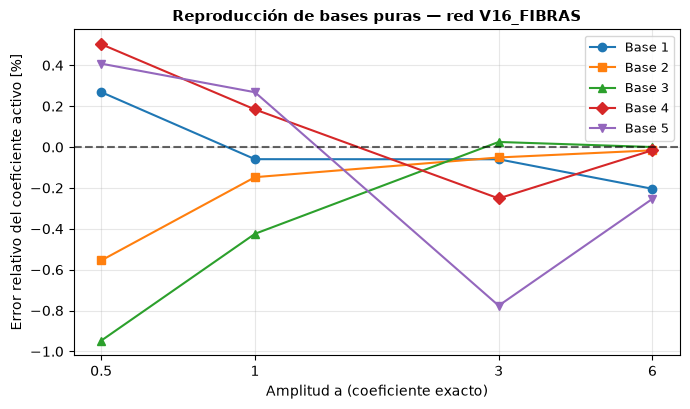

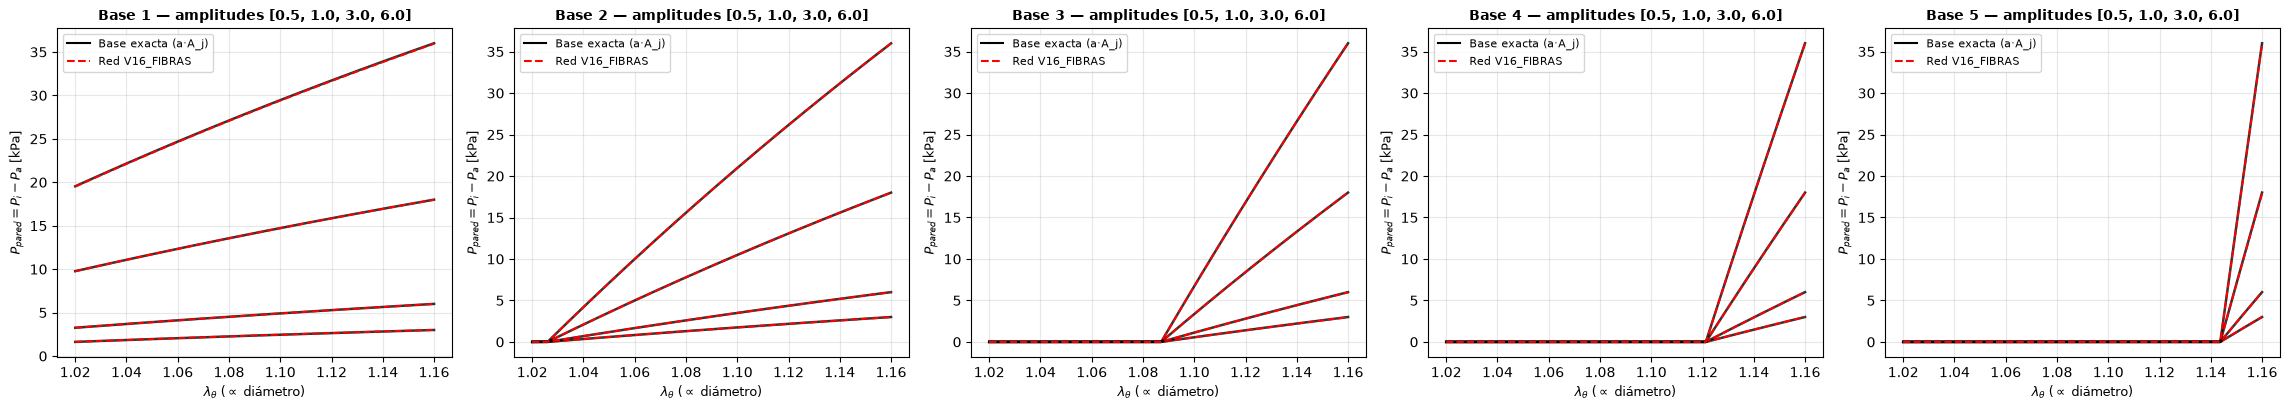

In [21]:
# ==============================================================================
# CÉLULA 14b: PRUEBA DE REPRODUCCIÓN DE LAS BASES (N bases × 4 amplitudes)
# ==============================================================================
"""
Entrada: y = a · A_j (una sola base, amplitud a).
Respuesta exacta: c = a · e_j. Se compara la red con el valor exacto y con el óptimo acotado.
Las bases puras no son curvas fisiológicas; la familia 'pura' del dataset las cubre con ruido.
Para la base constante el R² no está definido (curva plana): se informa NaN y vale el error del coeficiente.
Requiere la Célula 14 (usa cargar_archivos_sistema y predecir_coeficientes).
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AMPLITUDES_TEST = [0.5, 1.0, 3.0, MAX_COEF]
RUIDO_REL_TEST_BASES = 0.0      # 0 = prueba limpia; p. ej. 0.005 = mismo ruido que la familia 'pura'
rng_bases = np.random.default_rng(SEED + 7)

x_b, A_b, modelo_b, sx_b, sy_b, off_b = cargar_archivos_sistema()
n_b = A_b.shape[1]

filas, curvas = [], []
for j in range(n_b):
    for a in AMPLITUDES_TEST:
        c_exacto = np.zeros(n_b)
        c_exacto[j] = a
        y = A_b @ c_exacto
        if RUIDO_REL_TEST_BASES > 0:
            y = np.maximum(y + rng_bases.normal(0.0, RUIDO_REL_TEST_BASES, size=y.shape) * np.abs(y), 0.0)
        c_crudo, c_rn = predecir_coeficientes(modelo_b, sx_b, sy_b, off_b, y)
        c_crudo, c_rn = c_crudo[0], c_rn[0]
        c_lsq = lsq_acotado(A_b, y)
        m_rn, m_lsq = metricas_curva(y, A_b @ c_rn), metricas_curva(y, A_b @ c_lsq)
        fila = {"base": j + 1, "amplitud": a, "R2_red": m_rn["R2"], "NRMSE_red_pct": m_rn["NRMSE"],
                "MaxAE_red_kPa": m_rn["MaxAE"], "R2_opt": m_lsq["R2"],
                # error máximo relativo al NIVEL de la curva: definido también para la base constante,
                # donde R² y NRMSE no existen (varianza y rango nulos)
                "MaxAE_rel_nivel_pct": m_rn["MaxAE"] / max(float(np.abs(y).max()), 1e-12) * 100.0,
                "err_c_activo": c_rn[j] - a, "err_rel_c_activo_pct": (c_rn[j] - a) / a * 100.0,
                "max_c_inactivo": float(np.delete(c_rn, j).max()),
                "min_c_crudo": float(c_crudo.min())}
        for i in range(n_b):
            fila[f"c{i+1}_red"] = c_rn[i]
        filas.append(fila)
        curvas.append((j, a, y, A_b @ c_rn))

DF_BASES = pd.DataFrame(filas)
pd.set_option("display.width", 160)
print("\n" + "=" * 110)
print("🧱 REPRODUCCIÓN DE BASES PURAS (respuesta exacta: c = a·e_j)")
print("=" * 110)
print(DF_BASES[["base", "amplitud", "R2_red", "NRMSE_red_pct", "MaxAE_red_kPa", "MaxAE_rel_nivel_pct", "err_c_activo",
                "err_rel_c_activo_pct", "max_c_inactivo", "min_c_crudo"]].to_string(index=False, float_format=lambda v: f"{v:.5f}"))
print("-" * 110)
print("(R² y NRMSE no están definidos para la base constante: curva sin variación; usar MaxAE_rel_nivel_pct)")
print(f"Peor R² red (bases no constantes): {DF_BASES['R2_red'].min():.6f} | peor MaxAE relativo al nivel: "
      f"{DF_BASES['MaxAE_rel_nivel_pct'].max():.2f}% | peor |error relativo| en el coeficiente activo: "
      f"{DF_BASES['err_rel_c_activo_pct'].abs().max():.3f}% | máximo crosstalk: {DF_BASES['max_c_inactivo'].max():.5f}")
DF_BASES.to_csv(f"test_reproduccion_bases_{VERSION}.csv", index=False)
print(f"💾 'test_reproduccion_bases_{VERSION}.csv' guardado.")

# --- Error relativo del coeficiente activo vs. amplitud (la figura informativa para el artículo) ---
fig_e, ax_e = plt.subplots(figsize=(7, 4.2))
marcadores = ["o", "s", "^", "D", "v", "P"]
for j in range(n_b):
    d = DF_BASES[DF_BASES["base"] == j + 1]
    ax_e.plot(d["amplitud"], d["err_rel_c_activo_pct"], marker=marcadores[j % len(marcadores)], lw=1.5,
              label=f"Base {j+1}")
ax_e.axhline(0, color="black", linestyle="--", alpha=0.6)
ax_e.set_xscale("log")
ax_e.minorticks_off()
ax_e.set_xticks(AMPLITUDES_TEST)
ax_e.set_xticklabels([f"{a:g}" for a in AMPLITUDES_TEST])
ax_e.set_xlabel("Amplitud a (coeficiente exacto)", fontsize=10)
ax_e.set_ylabel("Error relativo del coeficiente activo [%]", fontsize=10)
ax_e.set_title(f"Reproducción de bases puras — red {VERSION.upper()}", fontsize=11, fontweight="bold")
ax_e.grid(True, alpha=0.3)
ax_e.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f"test_reproduccion_bases_error_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, n_b, figsize=(4.6 * n_b, 4.2), squeeze=False)
for j in range(n_b):
    ax = axes[0, j]
    for (jj, a, y, y_rn) in curvas:
        if jj != j:
            continue
        ax.plot(x_b, y, "k-", lw=1.8, alpha=0.8)
        ax.plot(x_b, y_rn, "r--", lw=1.4)
    ax.plot([], [], "k-", label="Base exacta (a·A_j)")
    ax.plot([], [], "r--", label=f"Red {VERSION.upper()}")
    ax.set_title(f"Base {j+1} — amplitudes {AMPLITUDES_TEST}", fontsize=10, fontweight="bold")
    ax.set_xlabel(ETQ_X, fontsize=9)
    ax.set_ylabel(ETQ_Y, fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(f"test_reproduccion_bases_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Célula 15 — Visualización de las capas (bases)

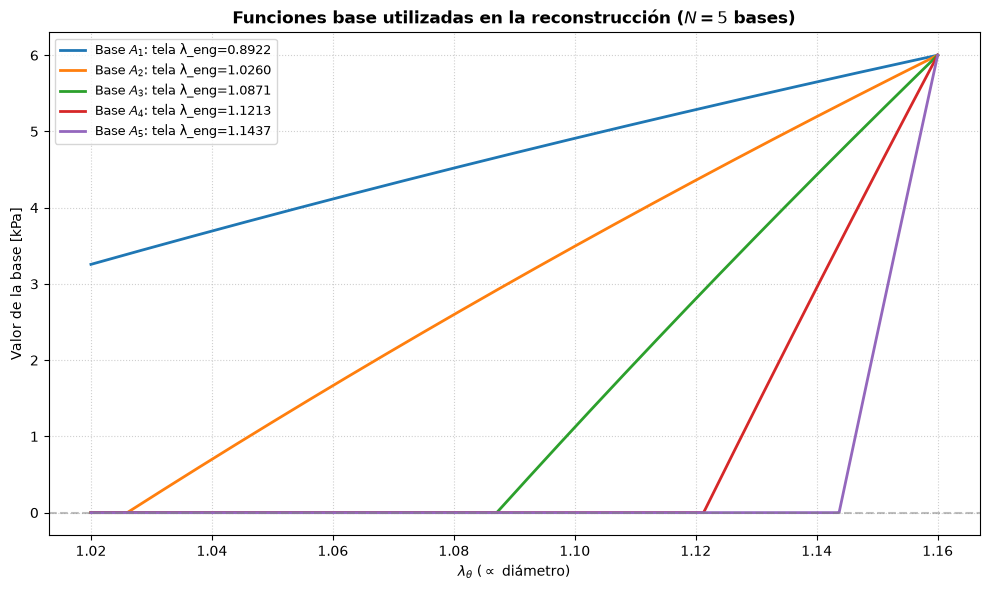

In [22]:
# ==============================================================================
# CÉLULA 15: VISUALIZACIÓN DE LAS BASES FUNCIONALES (A_base)
# ==============================================================================
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
for j in range(A_base.shape[1]):
    plt.plot(X_MESH_999, A_base[:, j], lw=2, label=rf"Base $A_{{{j+1}}}$: {NOMBRES_BASES[j]}" if "NOMBRES_BASES" in globals() else rf"Base $A_{{{j+1}}}$")

plt.title(rf"Funciones base utilizadas en la reconstrucción ($N = {A_base.shape[1]}$ bases)",
          fontsize=12, fontweight="bold")
plt.xlabel(ETQ_X, fontsize=10)
plt.ylabel("Valor de la base [kPa]", fontsize=10)
plt.axhline(0, color="gray", linestyle="--", alpha=0.5)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f"bases_funcionales_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()